# Separating temperature from supply with two ring oscillators in GF180MCU

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Orlando-Palma/sscs-ose-code-a-chip.github.io/blob/main/ISSCC27/submitted_notebooks/gf180_ro_pvt_sensor/ro_pvt_gf180.ipynb)

- **Author:** Orlando Arturo Palma León, Universidad de Sonora (México)
- **Submission:** IEEE SSCS Code-a-Chip, ISSCC 2027
- **License:** Apache License 2.0 (see `LICENSE`)
- **Tools:** ngspice 45.2, GF180MCU open PDK (`gf180mcu_fd_pr` models, open_pdks `gf180mcuC`), magic 8.3.464, netgen 1.5.272, KLayout 0.28.17, schemdraw 0.23

**Abstract.** A ring oscillator is the simplest on-chip temperature sensor, but its frequency depends as much on the supply as on temperature. This notebook designs, lays out and characterizes, in the open GF180MCU PDK, a monitor that pairs a plain CMOS ring (A) with a resistor-biased current-starved ring (B), so that their two frequencies separate temperature from supply. With one calibration temperature and a supply trim that needs no temperature chamber, the read-out stays within 2 °C in four of five process corners (4.9 °C in ff) over −40 to 125 °C and a ±10 % supply, where ring A alone errs by up to 63 °C. A mismatch Monte Carlo traces the remaining spread to one shared mirror device. In a 48-chip process + mismatch Monte Carlo, 24 test chips spread ±10.0 °C (3σ) with one calibration temperature and ±0.7 °C with two; a correction learned on the other 24 chips from three extra measurements at the single calibration temperature halves the one-temperature spread on the test chips (±5.3 °C), and Bayesian model fusion adapts it to an emulated silicon lot with one measured chip (rms 3.1 to 1.6 °C). The rings are laid out as code, pass magic DRC, LVS and the PDK's KLayout sign-off deck, and keep their corner accuracy after extraction. Every number is reproducible from a clean Colab runtime.

**Results at a glance** (values from the run saved with this notebook; a new run can differ by about 0.2 °C)

| | Ring A alone | Rings A + B with supply trim |
|---|---|---|
| Inaccuracy, 5 corners, ±10 % supply (one-point calibration) | 45–63 °C | ≤ 2 °C in four corners, 4.9 °C in ff |
| Residual supply sensitivity | 126–166 °C/V | ≤ 3.5 °C/V |
| Mismatch, 16 Monte Carlo chips (3σ) | 0.3 °C | 8.0 °C; 2.4 °C with a 16× larger mirror reference |
| Process + mismatch, 24 unseen Monte Carlo chips (3σ) | — | 10.0 °C with 1 calibration temperature; 5.3 °C with the learned correction; 0.7 °C with 2 temperatures |
| Model-to-silicon gap: lot with a resistor TC 10 % off the model (rms) | — | 3.1 °C with the simulation-trained correction; 1.6 °C after Bayesian model fusion with 1 measured chip; 0.3 °C with 2 temperatures |
| Layout parasitics, schematic read-out | 1.1 °C | 3.0 °C |
| Extracted netlists, 5 corners, read-out refitted on them | ≤ 1.6 °C at 3.3 V | ≤ 2.2 °C in four corners, 5.1 °C in ff |
| Aging, 10 mV of NBTI | 1.0 °C | 3.1 °C |
| Area (layout clean under magic DRC, KLayout sign-off DRC and LVS) | 202 µm² | 202 + 1660 µm² |
| Power, continuous | 1.2 mW | 1.4 mW |
| Energy per conversion at 0.1 °C quantization (estimate, rings only) | 5.6 nJ | 21 nJ |

**Key findings**

1. The bias stack of ring B decides whether temperature and supply can be separated at all (condition number 33 with one diode, 2.1 with a pMOS over an nMOS diode).
2. Mismatch in one mirror device shared by all stages, not process, limits the two-ring read-out (±8 °C, 3σ); enlarging it gives ±2.4 °C at a small cost in the corners.
3. From frequencies alone, ring A's temperature coefficient cannot be predicted; adding each ring's supply current and ring A's frequency at 1.2 V lets a learned correction halve the one-temperature error on unseen chips.
4. A correction trained on simulation inherits the model's errors; Bayesian model fusion with one measured chip removes most of that bias.
5. Layout parasitics change ring B's TC by 7 %, so the read-out must be fitted on extracted netlists; refitted, the corners return to their schematic results.

**Reading guide.** In ten minutes: this page, the corner read-out (7.3), the population and the learned calibration (7.9 to 7.11), the layout (9.1) and the error budget (12). Every section ends with a short interpretation; sections 11 to 14 hold the limitations, conclusions and future work. In Colab, the long helper cells are folded: click a title to see the code.

**Running it.** *Runtime → Run all*. The first cell builds ngspice and fetches the device models at pinned versions, so every number can be reproduced; the long simulation sets are cached as CSV files, so re-running a cell only reloads them. A complete run on a free Colab runtime (2 CPU cores) takes about 7 hours, most of it the two Monte Carlo populations of 7.9 and 7.11; keep the browser tab open. To rerun every analysis without the long simulation sets, tick `USE_SAVED_SIMULATIONS` in the first cell (a checkbox in Colab): it loads the simulation results saved with this submission (folder `data`) and the notebook finishes in under an hour.

## 1. Environment

Builds ngspice 45.2 from source (Colab's package is several releases older than the one these results were obtained with) and downloads the GF180MCU models at a fixed commit; re-running skips what is already in place. To use your own installation, set `NGSPICE` and `GF180_MODELS` before running it.

In [17]:
# @title Environment: ngspice 45.2, the GF180MCU models and the saved simulations
import os, shutil, subprocess

WORK = os.path.abspath("gf180_work")
os.makedirs(WORK, exist_ok=True)
NGSPICE_TAG = "ngspice-45.2"                                  # tested version
GF180_REPO = "https://github.com/fossi-foundation/globalfoundries-pdk-libs-gf180mcu_fd_pr.git"
GF180_COMMIT = "5e4be8726e2ae8be099c4131f697a353d6457874"     # tested commit (2026-10-19)

# True: load the simulation results saved with this submission (folder data) instead of running the long simulation
# sets again (about 7 h in Colab); every analysis, the layout flow and the shorter simulations still run
USE_SAVED_SIMULATIONS = False  # @param {type:"boolean"}


import time

LOG = os.path.join(WORK, "setup.log")


def sh(label, cmd, cwd=None):
    # Runs a shell step, keeps its output in setup.log and shows it only if the step fails
    # (Colab does not display the output of child processes in the cell).
    print(f"{label} ...", flush=True)
    with open(LOG, "a") as log:
        log.write(f"\n$ {cmd}\n")
        log.flush()
        p = subprocess.run(cmd, shell=True, cwd=cwd, stdout=log, stderr=subprocess.STDOUT)
    if p.returncode != 0:
        with open(LOG) as log:
            tail = log.read().splitlines()[-40:]
        print("\n".join(tail))
        raise RuntimeError(f"Step failed: {label} (exit {p.returncode}). Last lines of {LOG} above.")


# ngspice ---------------------------------------------------------------------
NGSPICE = os.environ.get("NGSPICE", os.path.join(WORK, "local", "bin", "ngspice"))
if not os.path.exists(NGSPICE):
    tools = ["git", "gcc", "make", "bison", "flex", "autoconf", "automake", "libtoolize"]
    if any(shutil.which(t) is None for t in tools):
        sh("installing build tools (apt)",
           "apt-get -qq update && apt-get -qq install -y build-essential bison flex autoconf automake libtool")
    src = os.path.join(WORK, "ngspice-src")
    if not os.path.isdir(os.path.join(src, ".git")):
        # read-only mirror of the official ngspice git repository (git.code.sf.net/p/ngspice/ngspice)
        sh(f"downloading {NGSPICE_TAG}",
           f"rm -rf {src} && git clone -q --depth 1 --branch {NGSPICE_TAG} https://github.com/imr/ngspice.git {src}")
    sh("autogen", "./autogen.sh", cwd=src)
    rel = os.path.join(src, "release")
    os.makedirs(rel, exist_ok=True)
    sh("configure", f"../configure --prefix={WORK}/local --with-x=no --with-readline=no --disable-debug", cwd=rel)
    sh("compiling (the long step)", "make -j$(nproc)", cwd=rel)
    sh("installing", "make install", cwd=rel)

# GF180MCU device models ------------------------------------------------------
GF180_MODELS = os.environ.get("GF180_MODELS", os.path.join(WORK, "gf180mcu_fd_pr", "models", "ngspice"))
if not os.path.exists(os.path.join(GF180_MODELS, "sm141064.spice")):
    repo = os.path.join(WORK, "gf180mcu_fd_pr")
    os.makedirs(repo, exist_ok=True)
    sh("downloading GF180MCU models",
       f"(git init -q && git remote add origin {GF180_REPO} || true) && "
       f"git fetch -q --depth 1 origin {GF180_COMMIT} && git checkout -q FETCH_HEAD", cwd=repo)

# saved simulation results ------------------------------------------------------
SAVED = ["pvt_grid.csv", "pvt_grid_b_pn.csv", "mc_mismatch_16.csv", "fix_mirror_8x4_16.csv",
         "fix_mirror_8x4_corners.csv", "mc_global_48.csv", "silicon_lot_24.csv", "post_layout_grid.csv"]
DATA_URLS = [f"https://raw.githubusercontent.com/{owner}/sscs-ose-code-a-chip.github.io/main/ISSCC27/submitted_notebooks/"
             "gf180_ro_pvt_sensor/data" for owner in ("sscs-ose", "Orlando-Palma")]
if USE_SAVED_SIMULATIONS:
    import urllib.request
    for name in SAVED:
        dst = os.path.join(WORK, name)
        if os.path.exists(dst):
            continue
        if os.path.exists(os.path.join("data", name)):            # notebook opened from a clone of the repository
            shutil.copy(os.path.join("data", name), dst)
            continue
        for url in DATA_URLS:
            try:
                urllib.request.urlretrieve(f"{url}/{name}", dst)
                break
            except Exception:
                pass
        else:
            raise RuntimeError(f"saved file {name} not found in ./data or at {DATA_URLS}")
    print(f"saved simulation results in place ({len(SAVED)} files)")

ver = subprocess.run([NGSPICE, "-v"], capture_output=True, text=True).stdout
print(next(l for l in ver.splitlines() if "ngspice-" in l).strip(" *"))
print("models:", GF180_MODELS)
print("Environment ready.")

ngspice-45.2 : Circuit level simulation program
models: /content/gf180_work/gf180mcu_fd_pr/models/ngspice
Environment ready.


## 2. Simulation helpers

Each simulation writes a netlist, runs `ngspice -b` in a fresh folder and parses the `.meas` results. Two details matter for this PDK:

- `set ngbehavior=hs` (in `.spiceinit`) lets `X` lines instantiate the binned MOSFET models (`nfet_03v3`, `pfet_03v3`, ...), as the PDK's own smoke test does.
- `.options tnom` is **not** set. The model cards carry `tnom=25`; overriding it to the simulation temperature would cancel the temperature dependence this sensor is built to measure.

In [18]:
# @title Simulation helpers
import re, tempfile, textwrap
import numpy as np
import matplotlib.pyplot as plt

CORNERS = ["typical", "ff", "ss", "fs", "sf"]   # library sections in sm141064.spice


def _workdir():
    d = tempfile.mkdtemp(prefix="gf180_", dir=WORK)
    with open(os.path.join(d, ".spiceinit"), "w") as f:
        f.write("set ngbehavior=hs\nset ng_nomodcheck\n")
    return d


def run_spice(netlist):
    d = _workdir()
    with open(os.path.join(d, "tb.cir"), "w") as f:
        f.write(netlist)
    try:
        p = subprocess.run([NGSPICE, "-b", "tb.cir"], cwd=d, capture_output=True, text=True, timeout=600)
    finally:
        shutil.rmtree(d, ignore_errors=True)             # keep the work folder small
    return p.stdout + p.stderr


def meas(log, name):
    m = re.search(rf"^{name}\s*=\s*([-+0-9.eE]+)", log, re.M)
    return float(m.group(1)) if m else float("nan")


def header(corner="typical", temp=27, mc_seed=None):
    # corner: a library section of sm141064.spice, or the path of a chip library with its own global process
    # sample (section 7.9). mc_seed: None for the nominal devices, or an integer that selects one mismatch
    # sample (section 7.5); the same seed always gives the same chip
    lines = ["* generated testbench", f'.include "{GF180_MODELS}/design.spice"']
    if corner.endswith(".lib"):
        lines += [".param sw_stat_global=1", f'.lib "{corner}" statistical']
    else:
        lines.append(f'.lib "{GF180_MODELS}/sm141064.spice" {corner}')
    s = "\n".join(lines + [f".temp {temp}"]) + "\n"
    if mc_seed is not None:
        s += f".param sw_stat_mismatch=1\n.options seed={int(mc_seed)}\n"
    return s

## 3. Sanity check: inverter delay

A single 3.3 V inverter (`W_n = 1 µm`, `W_p = 2.5 µm`, `L = 0.28 µm`) driving 10 fF, typical corner, 27 °C. On the tested setup this gives about 53 ps (fall) and 44 ps (rise); a value far from that means the models or the `.spiceinit` were not picked up.

In [19]:
def inverter_delay(corner="typical", temp=27, vdd=3.3, wn=1.0, wp=2.5, l=0.28, cl=10e-15):
    h = vdd / 2
    net = header(corner, temp) + textwrap.dedent(f'''\
        Vdd vdd 0 {vdd}
        Vin in 0 pulse(0 {vdd} 0 20p 20p 2n 4n)
        XMN out in 0 0 nfet_03v3 W={wn}u L={l}u
        XMP out in vdd vdd pfet_03v3 W={wp}u L={l}u
        CL out 0 {cl}
        .control
        tran 1p 8n
        meas tran tphl TRIG v(in) VAL={h} RISE=1 TARG v(out) VAL={h} FALL=1
        meas tran tplh TRIG v(in) VAL={h} FALL=1 TARG v(out) VAL={h} RISE=1
        quit
        .endc
        .end
        ''')
    log = run_spice(net)
    tphl, tplh = meas(log, "tphl"), meas(log, "tplh")
    if tphl != tphl or tplh != tplh:
        print(log[-3000:])
        raise RuntimeError("inverter simulation failed: ngspice log above")
    return tphl, tplh


tphl, tplh = inverter_delay()
print(f"tphl = {tphl*1e12:.1f} ps, tplh = {tplh*1e12:.1f} ps")

tphl = 52.8 ps, tplh = 44.4 ps


## 4. Ring oscillator

An odd ring of $N$ inverters oscillates at

$$f_{osc} = \frac{1}{2N\,t_{pd}}, \qquad t_{pd} \approx \frac{C_L\,V_{DD}}{I_{D}}, \qquad I_D \propto \mu(T)\,\big(V_{DD}-V_{TH}(T)\big)^{\alpha}.$$

Mobility falls with temperature while $V_{TH}$ also falls, so the two terms compete, and which one wins depends on the overdrive; the same expression carries the supply dependence, and an aging-induced $\Delta V_{TH}$ appears as a smaller overdrive.

**Aging proxy.** Each gate is driven through a DC source in series (knobs `dvn`, `dvp`), so the device sees its gate voltage shifted by $\Delta V_{TH}$ without any change in capacitance.

**Measurement.** The ring starts from an initial condition (`uic`); the period is averaged over 20 cycles after the first 10, and power is the average supply current over the same window. The schematic shows the ring and one stage with its two aging sources (0 V when fresh).

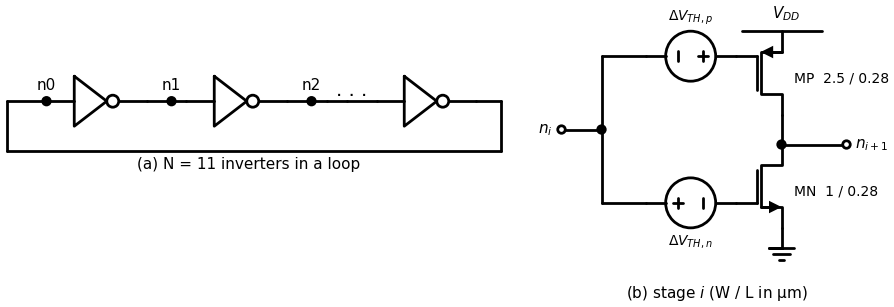

In [20]:
# @title Schematic of ring A
import sys
try:
    import schemdraw
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "schemdraw==0.23"], check=True)
    import schemdraw
import schemdraw.elements as elm
import schemdraw.logic as logic

schemdraw.use("matplotlib")


def nmos(d, drain, gate="left", label=None):
    # nMOS placed by its drain, gate on the left or right; returns the element (anchors drain, gate, source)
    e = elm.AnalogNFet().theta(180).flip() if gate == "left" else elm.AnalogNFet().theta(0)
    e = d.add(e.anchor("drain").at(drain))
    if label:
        dx = 0.35 if gate == "left" else -0.35
        d.add(elm.Label().at((drain[0] + dx, drain[1] - 0.83))
              .label(label, fontsize=10, halign="left" if gate == "left" else "right"))
    return e


def pmos(d, source, gate="left", label=None):
    # pMOS placed by its source
    e = elm.AnalogPFet().theta(180).flip() if gate == "left" else elm.AnalogPFet().theta(0)
    e = d.add(e.anchor("source").at(source))
    if label:
        dx = 0.35 if gate == "left" else -0.35
        d.add(elm.Label().at((source[0] + dx, source[1] - 0.83))
              .label(label, fontsize=10, halign="left" if gate == "left" else "right"))
    return e


with schemdraw.Drawing(unit=2) as d:
    d.config(fontsize=11)
    # (a) the loop
    d += elm.Line().at((0, 0)).right(0.8)
    d += elm.Dot().label("n0", loc="top")
    for name in ["n1", "n2", None, "n0"]:
        if name is None:
            d += elm.Line().right(0.4)
            d += elm.Label().label("· · ·", fontsize=14)
            d += elm.Line().right(0.6)
            continue
        d += logic.Not().right()
        d += elm.Line().right(0.5)
        if name != "n0":
            d += elm.Dot().label(name, loc="top")
            d += elm.Line().right(0.3)
    end = d.here
    d += elm.Line().at(end).down(1.0)
    d += elm.Line().left().tox(0)
    d += elm.Line().up(1.0)
    d += elm.Label().at((end[0] / 2, -1.35)).label("(a) N = 11 inverters in a loop", fontsize=11)
    # (b) stage i with the aging sources of section 4
    x, top = 15.5, 1.4
    d += elm.Line().at((x - 0.8, top)).to((x + 0.8, top))
    d += elm.Label().at((x, top + 0.25)).label("$V_{DD}$")
    mp = pmos(d, (x, top), label="MP  2.5 / 0.28")
    d += elm.Line().at(mp.drain).down(0.6)
    out = d.here
    d += elm.Dot()
    d += elm.Line().at(out).right(1.3)
    d += elm.Dot(open=True).label("$n_{i+1}$", loc="right")
    mn = nmos(d, out, label="MN  1 / 0.28")
    d += elm.Ground().at(mn.source)
    xi = x - 3.6
    d += elm.SourceV().at(mp.gate).left().length(1.8).reverse().label("$\\Delta V_{TH,p}$", loc="top", fontsize=10)
    d += elm.Line().left().tox(xi)
    d += elm.SourceV().at(mn.gate).left().length(1.8).label("$\\Delta V_{TH,n}$", loc="bottom", fontsize=10)
    d += elm.Line().left().tox(xi)
    d += elm.Line().at((xi, mp.gate[1])).to((xi, mn.gate[1]))
    ymid = (mp.gate[1] + mn.gate[1]) / 2
    d += elm.Dot().at((xi, ymid))
    d += elm.Line().at((xi, ymid)).left(0.8)
    d += elm.Dot(open=True).label("$n_i$", loc="left")
    d += elm.Label().at((x - 1.2, mn.source[1] - 1.2)).label("(b) stage $i$ (W / L in µm)", fontsize=11)

In [21]:
# @title Ring A: netlist and simulation
def ro_netlist(n_stages=11, wn=1.0, wp=2.5, l=0.28, dev="03v3", vdd=3.3, corner="typical",
               temp=27, dvn=0.0, dvp=0.0, t_stop=30e-9, t_step=2e-12, rise_a=10, rise_b=30, mc_seed=None):
    assert n_stages % 2 == 1 and n_stages >= 3
    lines = [header(corner, temp, mc_seed), f"Vdd vdd 0 {vdd}"]
    for i in range(n_stages):
        a, y = f"n{i}", f"n{(i + 1) % n_stages}"
        lines += [f"Vgn{i} {a} gn{i} {dvn}",          # v(gn) = v(a) - dvn
                  f"Vgp{i} gp{i} {a} {dvp}",          # v(gp) = v(a) + dvp
                  f"XMN{i} {y} gn{i} 0 0 nfet_{dev} W={wn}u L={l}u",
                  f"XMP{i} {y} gp{i} vdd vdd pfet_{dev} W={wp}u L={l}u"]
    h = vdd / 2
    lines.append(textwrap.dedent(f'''\
        .ic v(n0)=0 v(n1)={vdd}
        .control
        tran {t_step} {t_stop} uic
        meas tran ta WHEN v(n0)={h} RISE={rise_a}
        meas tran tb WHEN v(n0)={h} RISE={rise_b}
        meas tran iavg AVG i(Vdd) FROM=ta TO=tb
        quit
        .endc
        .end
        '''))
    return "\n".join(lines)


def run_ring(netlist_fn, **kw):
    # Simulates any ring built by netlist_fn; returns f (Hz), period (s), power (W), energy per cycle (J).
    # Doubles the simulated window and time step (up to 4 times) if the ring is too slow for it.
    rise_a, rise_b, vdd = kw.get("rise_a", 10), kw.get("rise_b", 30), kw.get("vdd", 3.3)
    for retries in range(5):
        log = run_spice(netlist_fn(**kw))
        ta, tb, iavg = meas(log, "ta"), meas(log, "tb"), meas(log, "iavg")
        if tb == tb:
            break
        kw["t_stop"] = 2 * kw.get("t_stop", 30e-9)
        kw["t_step"] = 2 * kw.get("t_step", 2e-12)
    if tb != tb:
        print(log[-3000:])
        raise RuntimeError("ring-oscillator simulation failed: ngspice log above")
    period = (tb - ta) / (rise_b - rise_a)
    power = -iavg * vdd
    return {"f": 1 / period, "period": period, "power": power, "e_cycle": power * period, "retries": retries}


def run_ro(**kw):
    return run_ring(ro_netlist, **kw)


r = run_ro()
print(f"11-stage ring, typical, 27 C, 3.3 V: f = {r['f']/1e9:.3f} GHz, "
      f"P = {r['power']*1e3:.2f} mW, E/cycle = {r['e_cycle']*1e12:.2f} pJ")

11-stage ring, typical, 27 C, 3.3 V: f = 1.196 GHz, P = 1.22 mW, E/cycle = 1.02 pJ


## 5. First result: frequency versus temperature

Typical corner, 3.3 V, from −40 °C to 125 °C.

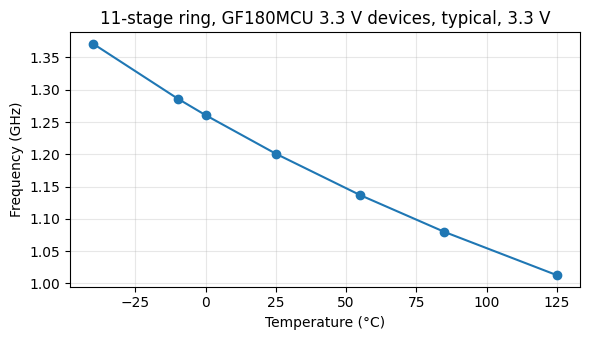

average sensitivity (linear fit, normalized to f at 25 C): -0.179 %/C  (-2.15 MHz/C)
max deviation from a straight line: 8.59 C


In [22]:
temps = np.array([-40, -10, 0, 25, 55, 85, 125])   # same points as the PVT grid
f_T = np.array([run_ro(temp=t)["f"] for t in temps])

slope, intercept = np.polyfit(temps, f_T, 1)
f25 = np.interp(25, temps, f_T)
resid_C = (f_T - (slope * temps + intercept)) / slope       # linearity error expressed in degC

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(temps, f_T / 1e9, "o-")
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Frequency (GHz)")
ax.set_title("11-stage ring, GF180MCU 3.3 V devices, typical, 3.3 V")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

print(f"average sensitivity (linear fit, normalized to f at 25 C): {slope / f25 * 100:.3f} %/C  ({slope/1e6:.2f} MHz/C)")
print(f"max deviation from a straight line: {np.max(np.abs(resid_C)):.2f} C")

## 6. PVT grid

Five process corners × seven temperatures (−40 to 125 °C) × three supplies (3.3 V ± 10 %) = 105 simulations. They run in parallel on every CPU core and are cached in `pvt_grid.csv`, so re-running the cell only reloads the table. Set `RERUN = True` to simulate again.

In [23]:
# @title PVT grid of ring A (105 simulations, about 20 min in Colab)
import itertools, time
import pandas as pd
from concurrent.futures import ThreadPoolExecutor

TEMPS = [-40, -10, 0, 25, 55, 85, 125]   # degC
VDDS = [2.97, 3.30, 3.63]                # V
CSV = os.path.join(WORK, "pvt_grid.csv")
RERUN = False

grid = [(c, t, round(v, 3)) for c, t, v in itertools.product(CORNERS, TEMPS, VDDS)]


def sim_point(p):
    corner, temp, vdd = p
    r = run_ro(corner=corner, temp=temp, vdd=vdd)
    return {"corner": corner, "temp_C": temp, "vdd_V": vdd,
            "f_Hz": r["f"], "power_W": r["power"], "e_cycle_J": r["e_cycle"]}


pvt = pd.read_csv(CSV) if (os.path.exists(CSV) and not RERUN) else None
if pvt is not None and set(zip(pvt.corner, pvt.temp_C, pvt.vdd_V.round(3))) == set(grid):
    print(f"loaded {len(pvt)} points from {CSV}")
else:
    t0, rows = time.time(), []
    with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
        for i, row in enumerate(ex.map(sim_point, grid), 1):
            rows.append(row)
            if i % 15 == 0 or i == len(grid):
                print(f"{i}/{len(grid)} points ({time.time() - t0:.0f} s)", flush=True)
    pvt = pd.DataFrame(rows)
    pvt.to_csv(CSV, index=False)
    print("saved", CSV)

loaded 105 points from /content/gf180_work/pvt_grid.csv


### 6.1 Frequency versus temperature across corners and supplies

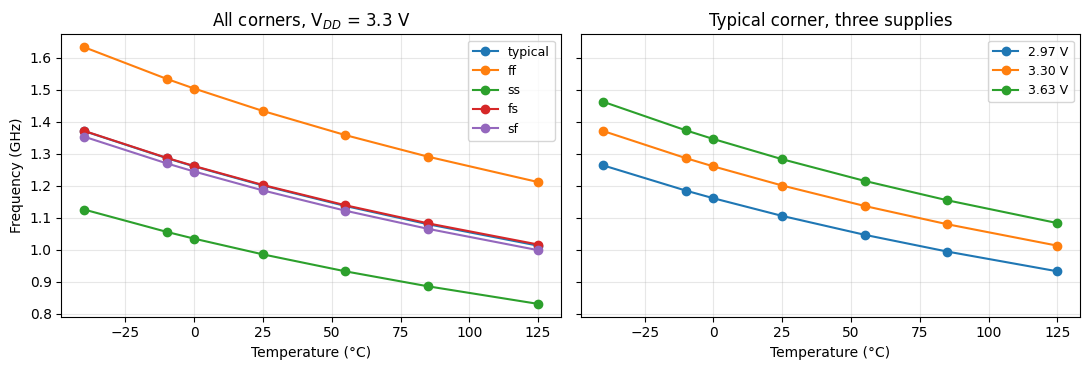

In [24]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for c in CORNERS:
    d = pvt[(pvt.corner == c) & np.isclose(pvt.vdd_V, 3.30)].sort_values("temp_C")
    ax1.plot(d.temp_C, d.f_Hz / 1e9, "o-", label=c)
ax1.set_title("All corners, V$_{DD}$ = 3.3 V")
for v in VDDS:
    d = pvt[(pvt.corner == "typical") & np.isclose(pvt.vdd_V, v)].sort_values("temp_C")
    ax2.plot(d.temp_C, d.f_Hz / 1e9, "o-", label=f"{v:.2f} V")
ax2.set_title("Typical corner, three supplies")
for ax in (ax1, ax2):
    ax.set_xlabel("Temperature (°C)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)
ax1.set_ylabel("Frequency (GHz)")
fig.tight_layout()
plt.show()

### 6.2 Sensitivities per corner

For each corner, at the nominal 3.3 V:

- **TC**: slope of a straight-line fit of $f(T)$, normalized to $f$ at 25 °C, in %/°C.
- **Nonlinearity**: largest deviation of $f(T)$ from that line, expressed in °C.
- **$S_V$**: $\dfrac{f(3.63\,\mathrm{V}) - f(2.97\,\mathrm{V})}{0.66\,\mathrm{V}\cdot f(3.3\,\mathrm{V})}$ at 25 °C, in %/V.
- **Temperature error per 10 mV**: $|S_V| \cdot 10\,\mathrm{mV} / |TC|$, the temperature reading error that a 10 mV supply change causes if the supply is not measured.

In [25]:
rows = []
for c in CORNERS:
    d = pvt[(pvt.corner == c) & np.isclose(pvt.vdd_V, 3.30)].sort_values("temp_C")
    T, f = d.temp_C.to_numpy(), d.f_Hz.to_numpy()
    a, b = np.polyfit(T, f, 1)
    f25 = f[T == 25][0]
    tc = a / f25
    d25 = pvt[(pvt.corner == c) & (pvt.temp_C == 25)].sort_values("vdd_V")
    sv = (d25.f_Hz.iloc[-1] - d25.f_Hz.iloc[0]) / (d25.vdd_V.iloc[-1] - d25.vdd_V.iloc[0]) / f25
    rows.append({"corner": c,
                 "f @25C (GHz)": f25 / 1e9,
                 "TC (%/C)": tc * 100,
                 "nonlinearity (C)": np.max(np.abs(f - (a * T + b))) / abs(a),
                 "S_V (%/V)": sv * 100,
                 "T error per 10 mV (C)": abs(sv * 0.01 / tc),
                 "E/cycle @25C (pJ)": d25.e_cycle_J.iloc[1] * 1e12})
summary = pd.DataFrame(rows).set_index("corner").round(3)
try:
    display(summary)
except NameError:   # outside Jupyter
    print(summary.to_string())

,f @25C (GHz),TC (%/C),nonlinearity (C),S_V (%/V),T error per 10 mV (C),E/cycle @25C (pJ)
corner,,,,,,
typical,1.201,-0.179,8.585,22.353,1.247,1.022
ff,1.434,-0.177,8.361,18.980,1.074,1.025
ss,0.986,-0.180,8.638,25.749,1.432,1.024
fs,1.203,-0.177,8.709,23.003,1.296,1.019
sf,1.186,-0.180,8.406,21.876,1.216,1.025


### 6.3 Read-out polynomial order

Each chip is calibrated at 25 °C, and the ratio $x = \ln(f/f_{25})$ is mapped to temperature by one polynomial whose coefficients come from the typical corner (3.3 V). The table gives the largest temperature error per corner for three polynomial orders; the other four corners are out-of-sample.

In [26]:
nom = pvt[np.isclose(pvt.vdd_V, 3.30)].copy()
f25 = nom[nom.temp_C == 25].set_index("corner").f_Hz
nom["x"] = np.log(nom.f_Hz / nom.corner.map(f25))
typ_nom = nom[nom.corner == "typical"]

orders = {}
for n, name in ((1, "linear"), (2, "quadratic"), (3, "cubic")):
    coef = np.polyfit(typ_nom.x, typ_nom.temp_C, n)
    err = (np.polyval(coef, nom.x) - nom.temp_C).abs()
    orders[name] = err.groupby(nom.corner).max()
order_table = pd.DataFrame(orders).T[CORNERS].round(2)
order_table.index.name = "max |error| (C)"
try:
    display(order_table)
except NameError:
    print(order_table.to_string())

corner,typical,ff,ss,fs,sf
max |error| (C),,,,,
linear,4.32,5.27,4.58,5.41,4.33
quadratic,0.13,1.34,0.44,1.50,0.66
cubic,0.00,1.25,0.31,1.41,0.77


### 6.4 Interpretation

**Process shifts the frequency, not its slope.** Across the corners the frequency at 25 °C spans 0.99 to 1.43 GHz (±18 %) while TC spans only −0.177 to −0.180 %/°C (±1 %). Most process variation scales the drain current by a constant factor $K$, so $\ln f = \ln K + g(T)$, and one calibration point with $x = \ln(f/f_{25})$ removes it; the ±1 % slope spread costs about 1.7 °C at 100 °C from the calibration point.

**One shared quadratic handles the curvature.** $f(T)$ bows by up to 8.7 °C from a straight line, with the same shape in every corner. A quadratic fitted on the typical corner brings every corner within 1.5 °C; a cubic mainly improves the corner it was fitted on.

**The supply limits ring A.** 10 mV of supply reads as 1.1 to 1.4 °C, so a ±10 % supply means about ±41 °C. Reaching ±2 °C would need $V_{DD}$ known within ±16 mV: either regulated that tightly or measured, which is the job of ring B.

## 7. Ring B: separating temperature from supply

Ring B is a current-starved ring whose current comes from a poly resistor:

- **Bias.** A `ppolyf_u_1k` resistor (±20 % across the `res_*` corners, TC −0.94·10⁻³/°C in the model) feeds a stack of diode-connected devices, so $I_B \approx \big(V_{DD} - \sum V_{GS}\big)/R$. The bottom nMOS diode sets the nMOS starving gates; a mirror copies $I_B$ into a pMOS diode for the other side.
- **Stages.** Every inverter is starved on both sides by $L = 1\,\mu$m devices, so $f_B \propto I_B / (C\,V_{DD})$.

The supply enters twice, through $I_B$ (up) and through the swing (down). Three bias stacks are compared:

| `bias` | stack under the resistor | expected effect |
|---|---|---|
| `"n"` | one nMOS diode | the swing term wins: negative supply sensitivity |
| `"nn"` | two nMOS diodes | $I_B$ grows faster than $V_{DD}$: the sign flips |
| `"pn"` | one pMOS diode over one nMOS diode | same flip, and fast nMOS / slow pMOS (fs, sf) partly cancel in $\sum V_{GS}$ |

Resistor corners follow the MOS corner (ff → `res_ff`, ss → `res_ss`, otherwise `res_typical`). In the `"pn"` schematic, $I_B$ flows through R, MPD and MNB; MNB's gate (`nb`) sets the nMOS starving devices, and MNM copies $I_B$ into MPB, whose gate (`pb`) sets the pMOS ones. Bodies go to the rails, except MPD's, tied to its source.

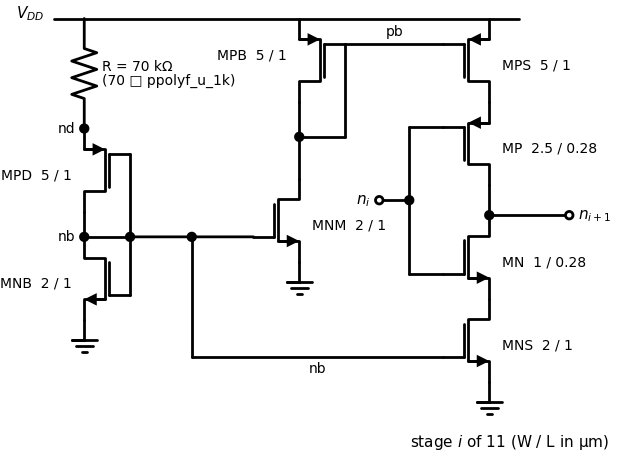

In [27]:
# @title Schematic of ring B
with schemdraw.Drawing(unit=2) as d:
    d.config(fontsize=11)
    d += elm.Line().at((-0.6, 0)).to((8.7, 0))
    d += elm.Label().at((-0.9, 0)).label("$V_{DD}$", halign="right")
    # bias: R over the pMOS-over-nMOS diode stack
    d += elm.Resistor().at((0, 0)).down(2.2).label("R = 70 kΩ\n(70 □ ppolyf_u_1k)", loc="bottom", fontsize=10)
    d += elm.Dot().label("nd", loc="left", fontsize=10)
    mpd = pmos(d, d.here, gate="right", label="MPD  5 / 1")
    d += elm.Line().at(mpd.drain).down(0.5)
    nb = d.here
    d += elm.Dot().label("nb", loc="left", fontsize=10)
    mnb = nmos(d, nb, gate="right", label="MNB  2 / 1")
    d += elm.Ground().at(mnb.source)
    xg = mpd.gate[0]
    d += elm.Line().at(mpd.gate).to((xg, mnb.gate[1]))
    d += elm.Line().at(nb).to((xg, nb[1]))
    d += elm.Dot().at((xg, nb[1]))
    # mirror: MNM copies I_B into the pMOS diode MPB
    xm = 4.3
    mpb = pmos(d, (xm, 0), gate="right", label="MPB  5 / 1")
    d += elm.Line().at(mpb.drain).down(0.7)
    pb = d.here
    d += elm.Dot()
    d += elm.Line().at(pb).to((mpb.gate[0], pb[1]))
    d += elm.Line().to(mpb.gate)
    mnm = nmos(d, (xm, nb[1] + 1.167), gate="left", label="MNM  2 / 1")
    d += elm.Line().at(pb).to(mnm.drain)
    d += elm.Line().at((xg, nb[1])).to(mnm.gate)
    d += elm.Ground().at(mnm.source)
    # one starved stage
    xs = 8.1
    mps = pmos(d, (xs, 0), label="MPS  5 / 1")
    d += elm.Line().at(mpb.gate).to(mps.gate).label("pb", loc="top", fontsize=10)
    mp = pmos(d, mps.drain, label="MP  2.5 / 0.28")
    d += elm.Line().at(mp.drain).down(0.6)
    out = d.here
    d += elm.Dot()
    d += elm.Line().at(out).right(1.6)
    d += elm.Dot(open=True).label("$n_{i+1}$", loc="right")
    mn = nmos(d, out, label="MN  1 / 0.28")
    mns = nmos(d, mn.source, label="MNS  2 / 1")
    d += elm.Ground().at(mns.source)
    xi = xs - 1.6
    d += elm.Line().at(mp.gate).to((xi, mp.gate[1]))
    d += elm.Line().to((xi, mn.gate[1]))
    d += elm.Line().to(mn.gate)
    d += elm.Dot().at((xi, (mp.gate[1] + mn.gate[1]) / 2))
    d += elm.Line().left(0.6)
    d += elm.Dot(open=True).label("$n_i$", loc="left")
    xr = (mnm.gate[0] + xg) / 2
    d += elm.Dot().at((xr, nb[1]))
    d += elm.Line().at((xr, nb[1])).to((xr, mns.gate[1]))
    d += elm.Line().at((xr, mns.gate[1])).to(mns.gate).label("nb", loc="bottom", fontsize=10)
    d += elm.Label().at((xs + 0.3, mns.source[1] - 1.3)).label("stage $i$ of 11 (W / L in µm)", fontsize=11)

In [28]:
# @title Ring B: netlist and simulation
RES_CORNER = {"typical": "res_typical", "ff": "res_ff", "ss": "res_ss", "fs": "res_typical", "sf": "res_typical"}


def csro_netlist(n_stages=11, bias="pn", r_sq=70, r_w=1.0, wn=1.0, wp=2.5, l=0.28, wsn=2.0, wsp=5.0,
                 ls=1.0, vdd=3.3, corner="typical", temp=27, dvn=0.0, dvp=0.0, t_stop=1.2e-6,
                 t_step=50e-12, rise_a=10, rise_b=30, mc_seed=None, wmir=None, lmir=None, wmns=None, lmns=None):
    # wmir, lmir: optional size of the shared nMOS mirror devices MNB and MNM; wmns, lmns: of the 11 MNS (section 7.8)
    assert n_stages % 2 == 1 and bias in ("n", "nn", "pn")
    wm, lm, wns, lns = (wmir or wsn), (lmir or ls), (wmns or wsn), (lmns or ls)
    top = "nb" if bias == "n" else "nd"
    lines = [header(corner, temp, mc_seed),
             (f'.lib "{corner}" res_statistical' if corner.endswith(".lib")
              else f'.lib "{GF180_MODELS}/sm141064.spice" {RES_CORNER[corner]}'),
             f"Vdd vdd 0 {vdd}",
             f"XR vdd {top} 0 ppolyf_u_1k r_length={r_sq * r_w}u r_width={r_w}u",   # R = r_sq squares
             f"XMNB nb nb 0 0 nfet_03v3 W={wm}u L={lm}u"]                           # diode, mirror reference
    if bias == "nn":
        lines.append(f"XMND nd nd nb 0 nfet_03v3 W={wsn}u L={ls}u")                 # stacked nMOS diode
    elif bias == "pn":
        lines.append(f"XMPD nb nb nd nd pfet_03v3 W={wsp}u L={ls}u")                # stacked pMOS diode
    lines += [f"XMNM pb nb 0 0 nfet_03v3 W={wm}u L={lm}u",                          # mirror into the pMOS diode
              f"XMPB pb pb vdd vdd pfet_03v3 W={wsp}u L={ls}u"]
    for i in range(n_stages):
        a, y = f"n{i}", f"n{(i + 1) % n_stages}"
        lines += [f"Vgn{i} {a} gn{i} {dvn}",
                  f"Vgp{i} gp{i} {a} {dvp}",
                  f"XMPS{i} sp{i} pb vdd vdd pfet_03v3 W={wsp}u L={ls}u",           # starving pMOS
                  f"XMNS{i} sn{i} nb 0 0 nfet_03v3 W={wns}u L={lns}u",              # starving nMOS
                  f"XMN{i} {y} gn{i} sn{i} 0 nfet_03v3 W={wn}u L={l}u",
                  f"XMP{i} {y} gp{i} sp{i} vdd pfet_03v3 W={wp}u L={l}u"]
    h = vdd / 2
    lines.append(textwrap.dedent(f'''\
        .ic v(n0)=0 v(n1)={vdd}
        .control
        tran {t_step} {t_stop} uic
        meas tran ta WHEN v(n0)={h} RISE={rise_a}
        meas tran tb WHEN v(n0)={h} RISE={rise_b}
        meas tran iavg AVG i(Vdd) FROM=ta TO=tb
        quit
        .endc
        .end
        '''))
    return "\n".join(lines)


def run_csro(**kw):
    kw.setdefault("t_stop", 1.2e-6)
    kw.setdefault("t_step", 50e-12)
    return run_ring(csro_netlist, **kw)


r = run_csro()
print(f"ring B, typical, 27 C, 3.3 V: f = {r['f']/1e6:.2f} MHz, P = {r['power']*1e6:.0f} uW "
      f"(bias branches included)")

ring B, typical, 27 C, 3.3 V: f = 46.92 MHz, P = 184 uW (bias branches included)


### 7.1 Choosing the bias stack

Around 25 °C and 3.3 V each ring gives one row of

$$\begin{bmatrix}\Delta f_A/f_A\\ \Delta f_B/f_B\end{bmatrix} = S\begin{bmatrix}\Delta T\\ \Delta V_{DD}\end{bmatrix}.$$

The condition number of $S$ (typical corner, columns scaled by the ranges of 165 °C and 0.66 V) measures how much a frequency error is amplified when the pair is inverted: close to 1 is good. The spread of ring B's TC and $S_V$ over the corners shows how well a typical-corner model will transfer. Finite differences of ±25 °C and ±0.1 V.

In [29]:
def sensitivities(run_fn, corner="typical", **kw):
    pts = {"f0": (25, 3.3), "tp": (50, 3.3), "tm": (0, 3.3), "vp": (25, 3.4), "vm": (25, 3.2)}
    f = {k: run_fn(corner=corner, temp=t, vdd=v, **kw)["f"] for k, (t, v) in pts.items()}
    return f["f0"], (f["tp"] - f["tm"]) / 50 / f["f0"], (f["vp"] - f["vm"]) / 0.2 / f["f0"]


RANGES = np.array([165.0, 0.66])
fA, tA, vA = sensitivities(run_ro)
jobs = [(b, c) for b in ("n", "nn", "pn") for c in CORNERS]
with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
    sens_b = dict(zip(jobs, ex.map(lambda j: sensitivities(run_csro, corner=j[1], bias=j[0]), jobs)))

rows = [{"ring": "A (plain)", "f typical (MHz)": fA / 1e6, "TC typical (%/C)": tA * 100,
         "S_V typical (%/V)": vA * 100, "cond(S) with A": np.nan,
         "TC over corners (%/C)": "", "S_V over corners (%/V)": ""}]
for b in ("n", "nn", "pn"):
    fB, tB, vB = sens_b[(b, "typical")]
    tcs = [100 * sens_b[(b, c)][1] for c in CORNERS]
    svs = [100 * sens_b[(b, c)][2] for c in CORNERS]
    rows.append({"ring": f"B, bias='{b}'", "f typical (MHz)": fB / 1e6, "TC typical (%/C)": tB * 100,
                 "S_V typical (%/V)": vB * 100,
                 "cond(S) with A": np.linalg.cond(np.array([[tA, vA], [tB, vB]]) * RANGES),
                 "TC over corners (%/C)": f"{min(tcs):+.3f} to {max(tcs):+.3f}",
                 "S_V over corners (%/V)": f"{min(svs):+.1f} to {max(svs):+.1f}"})
sens_table = pd.DataFrame(rows).set_index("ring").round(3)
try:
    display(sens_table)
except NameError:
    print(sens_table.to_string())

,f typical (MHz),TC typical (%/C),S_V typical (%/V),cond(S) with A,TC over corners (%/C),S_V over corners (%/V)
ring,,,,,,
A (plain),1200.854,-0.189,22.248,NaN,,
"B, bias='n'",103.585,0.055,-8.414,33.470,+0.046 to +0.062,-9.3 to -6.6
"B, bias='nn'",43.279,0.084,25.487,1.696,+0.069 to +0.104,+16.1 to +37.4
"B, bias='pn'",46.857,0.071,20.244,2.072,+0.063 to +0.081,+16.4 to +26.1


### 7.2 PVT grid for ring B (bias = 'pn')

Same 105 points as section 6, cached in `pvt_grid_b_pn.csv`.

In [30]:
# @title PVT grid of ring B (105 simulations, about 20 min in Colab)
B_BIAS = "pn"                                        # bias stack chosen in 7.1
CSV_B = os.path.join(WORK, f"pvt_grid_b_{B_BIAS}.csv")


def sim_point_b(p):
    corner, temp, vdd = p
    r = run_csro(corner=corner, temp=temp, vdd=vdd, bias=B_BIAS)
    return {"corner": corner, "temp_C": temp, "vdd_V": vdd,
            "f_Hz": r["f"], "power_W": r["power"], "e_cycle_J": r["e_cycle"]}


pvt_b = pd.read_csv(CSV_B) if (os.path.exists(CSV_B) and not RERUN) else None
if pvt_b is not None and set(zip(pvt_b.corner, pvt_b.temp_C, pvt_b.vdd_V.round(3))) == set(grid):
    print(f"loaded {len(pvt_b)} points from {CSV_B}")
else:
    t0, rows = time.time(), []
    with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
        for i, row in enumerate(ex.map(sim_point_b, grid), 1):
            rows.append(row)
            if i % 15 == 0 or i == len(grid):
                print(f"{i}/{len(grid)} points ({time.time() - t0:.0f} s)", flush=True)
    pvt_b = pd.DataFrame(rows)
    pvt_b.to_csv(CSV_B, index=False)
    print("saved", CSV_B)

15/105 points (187 s)
30/105 points (354 s)
45/105 points (542 s)
60/105 points (705 s)
75/105 points (900 s)
90/105 points (1068 s)
105/105 points (1244 s)
saved /content/gf180_work/pvt_grid_b_pn.csv


### 7.3 Temperature read-out across corners

Each chip is calibrated at **one temperature**, 25 °C; afterwards only frequency ratios are used, $x_A = \ln(f_A/f_{A,cal})$ and $x_B = \ln(f_B/f_{B,cal})$, with the calibration frequencies taken at 25 °C and 3.3 V. Three read-outs are compared:

1. **Ring A alone.** A quadratic $\hat T(x_A)$, as chosen in 6.3. It cannot see the supply.
2. **A + B, one-point calibration.** Quadratic surfaces $\hat T(x_A, x_B)$ and $\hat V_{DD}(x_A, x_B)$.
3. **A + B with a supply trim.** At the same 25 °C step the tester also reads both rings at 2.97 and 3.63 V: two extra readings, no extra temperature. That gives each chip's supply slopes $v_A$, $v_B$, and $z = x_A - (v_A/v_B)\,x_B$ has no first-order supply dependence; $\hat T$ is a cubic in $z$ plus small $x_B$ terms.

All models are fitted on the typical corner only, so the other four corners are out-of-sample tests.

,"1) A alone, 3.3 V only (C)","1) A alone, 3.3 V +/-10 % (C)","2) A + B, 1-point (C)","2) A + B, 1-point: V_DD (mV)",3) A + B + supply trim (C)
corner,,,,,
typical,0.13,54.98,1.38,11.18,0.84
ff,1.34,45.43,7.80,99.93,4.90
ss,0.44,62.92,7.49,111.22,2.00
fs,1.50,54.88,3.68,10.51,1.33
sf,0.66,54.67,2.58,11.13,1.10


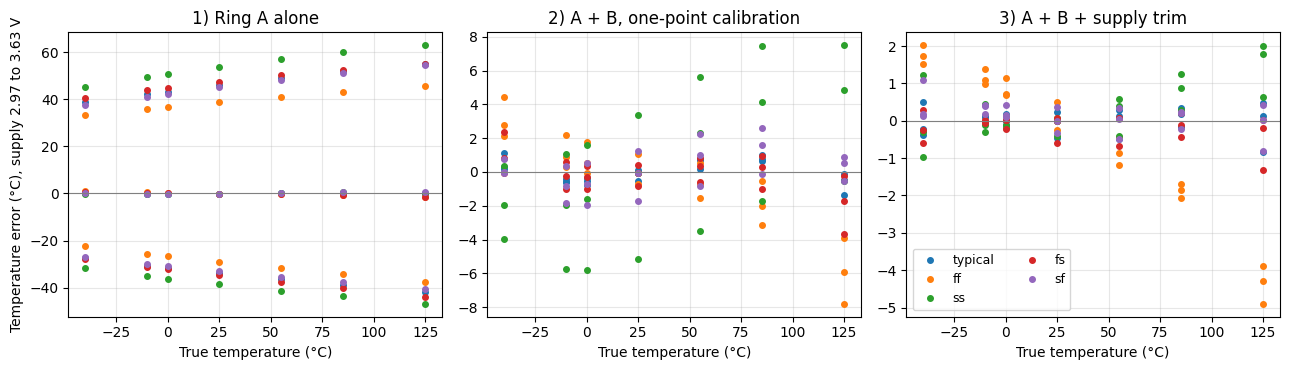

In [31]:
m = pvt.merge(pvt_b, on=["corner", "temp_C", "vdd_V"], suffixes=("_A", "_B"))
cal = m[(m.temp_C == 25) & np.isclose(m.vdd_V, 3.30)].set_index("corner")
m["xA"] = np.log(m.f_Hz_A / m.corner.map(cal.f_Hz_A))
m["xB"] = np.log(m.f_Hz_B / m.corner.map(cal.f_Hz_B))

# supply trim: per-chip slopes d x / d VDD measured at 25 C only
d25 = m[m.temp_C == 25].sort_values("vdd_V")
v_A = d25.groupby("corner").xA.apply(lambda x: (x.iloc[-1] - x.iloc[0]) / 0.66)
v_B = d25.groupby("corner").xB.apply(lambda x: (x.iloc[-1] - x.iloc[0]) / 0.66)
m["z"] = m.xA - m.corner.map(v_A / v_B) * m.xB


def basis_a(xa):
    return np.column_stack([np.ones_like(xa), xa, xa**2])


def basis_ab(xa, xb):
    return np.column_stack([np.ones_like(xa), xa, xb, xa**2, xa * xb, xb**2])


def basis_trim(z, xb):
    return np.column_stack([np.ones_like(z), z, z**2, z**3, xb, xb**2, z * xb])


def fitted(basis, cols, target, mask):
    X = basis(*[m[c].to_numpy() for c in cols])
    coef = np.linalg.lstsq(X[mask.to_numpy()], m[target][mask].to_numpy(), rcond=None)[0]
    return X @ coef


typ = m.corner == "typical"
nominal = np.isclose(m.vdd_V, 3.30)
m["eT_A"] = fitted(basis_a, ["xA"], "temp_C", typ & nominal) - m.temp_C
m["eT_AB"] = fitted(basis_ab, ["xA", "xB"], "temp_C", typ) - m.temp_C
m["eV_AB"] = fitted(basis_ab, ["xA", "xB"], "vdd_V", typ) - m.vdd_V
m["eT_trim"] = fitted(basis_trim, ["z", "xB"], "temp_C", typ) - m.temp_C


def worst(col, rows=None):
    d = m if rows is None else m[rows]
    return d.groupby("corner")[col].apply(lambda e: e.abs().max())


readout = pd.DataFrame({
    "1) A alone, 3.3 V only (C)": worst("eT_A", nominal),
    "1) A alone, 3.3 V +/-10 % (C)": worst("eT_A"),
    "2) A + B, 1-point (C)": worst("eT_AB"),
    "2) A + B, 1-point: V_DD (mV)": 1e3 * worst("eV_AB"),
    "3) A + B + supply trim (C)": worst("eT_trim"),
}).reindex(CORNERS).round(2)
try:
    display(readout)
except NameError:
    print(readout.to_string())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
titles = ["1) Ring A alone", "2) A + B, one-point calibration", "3) A + B + supply trim"]
for ax, col, title in zip(axes, ["eT_A", "eT_AB", "eT_trim"], titles):
    for c in CORNERS:
        d = m[m.corner == c]
        ax.plot(d.temp_C, d[col], "o", ms=4, label=c)
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_title(title)
    ax.set_xlabel("True temperature (°C)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Temperature error (°C), supply 2.97 to 3.63 V")
axes[2].legend(fontsize=9, ncol=2)
fig.tight_layout()
plt.show()

### 7.4 Interpretation

**The bias stack sets the direction of ring B's sensitivity vector.** Ring A has TC < 0 and $S_V$ > 0. With `'n'`, ring B has both signs reversed, so the two vectors are nearly collinear (condition number 33). Two diodes make $I_B$ grow faster than $V_{DD}$, turning $S_V$ positive while TC stays positive: `'nn'` and `'pn'` give 1.7 and 2.1. `'pn'` keeps $S_V$ within 16.4 to 26.1 %/V over the corners (16.1 to 37.4 for `'nn'`) because the nMOS and pMOS shifts cancel in fs and sf, so it is the design.

**The typical corner is in-sample; the other four are the test.** Ring A alone errs by 45 to 63 °C over a ±10 % supply, A + B with a one-point calibration by up to about 8 °C, and the supply trim brings fs, sf and ss to 1 to 2 °C and ff to about 5 °C.

**What remains is ring B's TC.** In ff and ss both diodes move the same way, changing $I_B$ and ring B's $S_V$, which the trim measures; its TC also changes (0.063 to 0.081 %/°C), which a one-temperature calibration cannot see: the ≈5 °C left in ff. The cubic in $z$ improves fs and sf by about 0.5 °C over a quadratic; since that choice looked at the non-typical corners, the clean validation is the Monte Carlo population of 7.9.

### 7.5 Mismatch Monte Carlo

The corners move every device of a die together; mismatch is the random difference between nominally identical devices on one die. The GF180MCU models include it (`sw_stat_mismatch=1`): each device gets its own threshold and mobility offset with a standard deviation proportional to $1/\sqrt{WL}$. With a fixed `.options seed`, ngspice draws the same values in every run of a netlist, so one seed is one chip that can be calibrated at 25 °C and measured later at other temperatures and supplies; rings A and B use different seeds.

Each of `N_MC = 16` chips sits on the typical corner and is simulated at −40, 25 and 125 °C and the three supplies, with its own calibration and supply trim and the nominal read-out coefficients, nothing refitted: 288 simulations, cached.

In [32]:
# @title Mismatch Monte Carlo (288 simulations, about 35 min in Colab)
N_MC = 16                     # chips; more chips give a tighter estimate of the 3-sigma spread
MC_TEMPS = [-40, 25, 125]
CSV_MC = os.path.join(WORK, f"mc_mismatch_{N_MC}.csv")

# 1-sigma mismatch of one device, from the formulas of the fets_mm section of sm141064.spice
# (pair coefficients 7.148 / 6.660 mV*um for V_TH and 0.7008 / 0.2833 %*um for mobility, nMOS / pMOS;
#  L_eff = L - 0.15 um, W_eff = W + 0.1 um)
def device_sigma(w, l, pmos):
    root_area = np.sqrt((l - 0.15) * (w + 0.1))
    a_vt, a_mu = (6.660, 0.2833) if pmos else (7.148, 0.7008)
    return 0.7071 * a_vt / root_area, 0.7071 * a_mu / root_area


dev_rows = []
for name, w, l, pmos in [("MN (inverter)", 1.0, 0.28, False), ("MP (inverter)", 2.5, 0.28, True),
                         ("MNS, MNB, MNM (ring B bias)", 2.0, 1.0, False),
                         ("MPS, MPD, MPB (ring B bias)", 5.0, 1.0, True)]:
    s_vt, s_mu = device_sigma(w, l, pmos)
    dev_rows.append({"device": name, "W/L (um)": f"{w:g}/{l:g}", "sigma V_TH (mV)": s_vt, "sigma mobility (%)": s_mu})
devices = pd.DataFrame(dev_rows).set_index("device").round(2)
try:
    display(devices)
except NameError:
    print(devices.to_string())


def mc_point(job):
    chip, ring, temp, vdd = job
    if ring == "A":
        r = run_ro(temp=temp, vdd=vdd, mc_seed=1000 + chip)
    else:   # 0.9 us holds 30 cycles of ring B at the typical corner; results are identical to the 1.2 us window
        r = run_csro(bias=B_BIAS, temp=temp, vdd=vdd, mc_seed=2000 + chip, t_stop=0.9e-6)
    return {"chip": chip, "ring": ring, "temp_C": temp, "vdd_V": vdd, "f_Hz": r["f"]}


mc_jobs = [(c, ring, t, v) for c in range(N_MC) for ring in ("A", "B") for t in MC_TEMPS for v in VDDS]
mc_raw = pd.read_csv(CSV_MC) if (os.path.exists(CSV_MC) and not RERUN) else None
if mc_raw is not None and len(mc_raw) == len(mc_jobs):
    print(f"loaded {len(mc_raw)} simulations from {CSV_MC}")
else:
    t0, rows = time.time(), []
    with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
        for i, row in enumerate(ex.map(mc_point, mc_jobs), 1):
            rows.append(row)
            if i % 36 == 0 or i == len(mc_jobs):
                print(f"{i}/{len(mc_jobs)} simulations ({time.time() - t0:.0f} s)", flush=True)
    mc_raw = pd.DataFrame(rows)
    mc_raw.to_csv(CSV_MC, index=False)
    print("saved", CSV_MC)

,W/L (um),sigma V_TH (mV),sigma mobility (%)
device,,,
MN (inverter),1/0.28,13.37,1.31
MP (inverter),2.5/0.28,8.10,0.34
"MNS, MNB, MNM (ring B bias)",2/1,3.78,0.37
"MPS, MPD, MPB (ring B bias)",5/1,2.26,0.10


36/288 simulations (261 s)
72/288 simulations (515 s)
108/288 simulations (767 s)
144/288 simulations (1019 s)
180/288 simulations (1275 s)
216/288 simulations (1533 s)
252/288 simulations (1786 s)
288/288 simulations (2051 s)
saved /content/gf180_work/mc_mismatch_16.csv


spread over 16 chips (1 sigma): f at 25 C, 3.3 V: ring A 0.22 %, ring B 2.41 %; supply slope: ring A 0.09 %/V (mean 22.5), ring B 0.76 %/V (mean 20.5)


,no mismatch: max |error| (C),MC: max |mean| (C),MC: max 3 sigma (C),"MC: worst chip, max |error| (C)"
"A alone, 3.3 V",0.11,0.12,0.33,0.31
"A alone, 3.3 V +/-10 %",54.98,54.93,0.73,55.38
"A + B + supply trim, 3.3 V +/-10 %",0.84,1.55,8.02,5.39
"same, mismatch in ring A only",0.84,0.86,0.43,1.15
"same, mismatch in ring B only",0.84,1.53,8.04,5.47


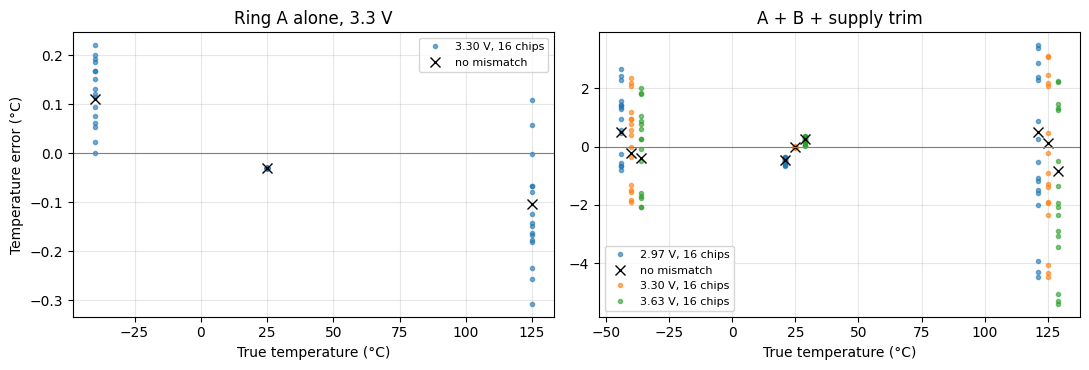

In [33]:
# per-chip calibration and supply trim, exactly as in 7.3
mc = (mc_raw.assign(vdd_V=mc_raw.vdd_V.round(2))
      .pivot_table(index=["chip", "temp_C", "vdd_V"], columns="ring", values="f_Hz").reset_index())
mc.columns.name = None
mc = mc.rename(columns={"A": "f_A", "B": "f_B"})
cal_mc = mc[(mc.temp_C == 25) & np.isclose(mc.vdd_V, 3.30)].set_index("chip")
mc["xA"] = np.log(mc.f_A / mc.chip.map(cal_mc.f_A))
mc["xB"] = np.log(mc.f_B / mc.chip.map(cal_mc.f_B))
s25 = mc[mc.temp_C == 25].sort_values("vdd_V")
vA_mc = s25.groupby("chip").xA.apply(lambda x: (x.iloc[-1] - x.iloc[0]) / 0.66)
vB_mc = s25.groupby("chip").xB.apply(lambda x: (x.iloc[-1] - x.iloc[0]) / 0.66)
mc["z"] = mc.xA - mc.chip.map(vA_mc / vB_mc) * mc.xB

# read-out coefficients fitted on the nominal typical corner (7.3); not refitted
typ_rows = m.corner == "typical"
coef_a = np.linalg.lstsq(basis_a(m.xA[typ_rows & nominal].to_numpy()),
                         m.temp_C[typ_rows & nominal].to_numpy(), rcond=None)[0]
coef_t = np.linalg.lstsq(basis_trim(m.z[typ_rows].to_numpy(), m.xB[typ_rows].to_numpy()),
                         m.temp_C[typ_rows].to_numpy(), rcond=None)[0]
mc["eT_A"] = basis_a(mc.xA.to_numpy()) @ coef_a - mc.temp_C
mc["eT_trim"] = basis_trim(mc.z.to_numpy(), mc.xB.to_numpy()) @ coef_t - mc.temp_C

print(f"spread over {N_MC} chips (1 sigma): f at 25 C, 3.3 V: ring A {100 * cal_mc.f_A.std() / cal_mc.f_A.mean():.2f} %, "
      f"ring B {100 * cal_mc.f_B.std() / cal_mc.f_B.mean():.2f} %; supply slope: ring A {100 * vA_mc.std():.2f} %/V "
      f"(mean {100 * vA_mc.mean():.1f}), ring B {100 * vB_mc.std():.2f} %/V (mean {100 * vB_mc.mean():.1f})")

# same read-out with the mismatch of only one ring (the other ring at its nominal typical value)
typ_pts = m[typ_rows].assign(vdd_V=m.vdd_V.round(2)).set_index(["temp_C", "vdd_V"])
pts = pd.MultiIndex.from_arrays([mc.temp_C, mc.vdd_V])
xA_nom, xB_nom = typ_pts.xA.reindex(pts).to_numpy(), typ_pts.xB.reindex(pts).to_numpy()


def trim_error(xa, xb, k):
    xa, xb, k = np.asarray(xa), np.asarray(xb), np.asarray(k)
    return basis_trim(xa - k * xb, xb) @ coef_t - mc.temp_C.to_numpy()


mc["eT_trim_onlyA"] = trim_error(mc.xA, xB_nom, mc.chip.map(vA_mc) / v_B["typical"])
mc["eT_trim_onlyB"] = trim_error(xA_nom, mc.xB, v_A["typical"] / mc.chip.map(vB_mc))
ref = m[typ_rows & m.temp_C.isin(MC_TEMPS)]
for col in ("eT_trim_onlyA", "eT_trim_onlyB"):
    ref = ref.assign(**{col: ref.eT_trim})


def mc_row(col, only_nominal):
    d = mc[np.isclose(mc.vdd_V, 3.30)] if only_nominal else mc
    r = ref[np.isclose(ref.vdd_V, 3.30)] if only_nominal else ref
    per_point = d.groupby(["temp_C", "vdd_V"])[col]
    return {"no mismatch: max |error| (C)": r[col].abs().max(),
            "MC: max |mean| (C)": per_point.mean().abs().max(),
            "MC: max 3 sigma (C)": 3 * per_point.std().max(),
            "MC: worst chip, max |error| (C)": d[col].abs().max()}


mc_table = pd.DataFrame({"A alone, 3.3 V": mc_row("eT_A", True),
                         "A alone, 3.3 V +/-10 %": mc_row("eT_A", False),
                         "A + B + supply trim, 3.3 V +/-10 %": mc_row("eT_trim", False),
                         "   same, mismatch in ring A only": mc_row("eT_trim_onlyA", False),
                         "   same, mismatch in ring B only": mc_row("eT_trim_onlyB", False)}).T.round(2)
try:
    display(mc_table)
except NameError:
    print(mc_table.to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, title, vdds in ((axes[0], "eT_A", "Ring A alone, 3.3 V", [3.30]),
                             (axes[1], "eT_trim", "A + B + supply trim", VDDS)):
    for k, v in enumerate(vdds):
        dx = 4 * (k - (len(vdds) - 1) / 2)
        d = mc[np.isclose(mc.vdd_V, v)]
        ax.plot(d.temp_C + dx, d[col], "o", ms=3, alpha=0.6, label=f"{v:.2f} V, {N_MC} chips")
        r = ref[np.isclose(ref.vdd_V, v)]
        ax.plot(r.temp_C + dx, r[col], "kx", ms=7, label="no mismatch" if k == 0 else None)
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_title(title)
    ax.set_xlabel("True temperature (°C)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Temperature error (°C)")
fig.tight_layout()
plt.show()

### 7.6 Where ring B's spread comes from, and what predicts it

To find the devices behind ring B's spread, the cell below shifts the $|V_{TH}|$ of one group of ring B devices by one standard deviation (with a gate source, as for aging) and measures the change in ring B's frequency at 25 °C and in its $TC_B = \ln\!\big(f(125)/f(-40)\big)/165$ °C. A group of 11 per-stage devices has independent shifts, so its effect is divided by $\sqrt{11}$ (21 simulations).

In [34]:
# @title One-sigma shift of each group of ring B devices
def csro_shifted(group, dv):
    # ring B netlist with the gate of every device whose name matches `group` behind a dv source:
    # nMOS gates see gate - dv and pMOS gates see gate + dv, so |V_TH| is effectively higher by dv
    def netlist(**kw):
        lines = []
        for line in csro_netlist(**kw).splitlines():
            tok = line.split()
            if tok and re.fullmatch(group, tok[0]):
                gate, new = tok[2], f"{tok[2]}_{tok[0]}"
                lines.append(f"V{tok[0]} {new} {gate} {dv}" if "pfet" in line else f"V{tok[0]} {gate} {new} {dv}")
                tok[2] = new
                line = " ".join(tok)
            lines.append(line)
        return "\n".join(lines)
    return netlist


s_n, s_p = device_sigma(2.0, 1.0, False)[0] * 1e-3, device_sigma(5.0, 1.0, True)[0] * 1e-3
groups = {"MNB (reference diode)": ("XMNB", s_n, 1), "MPD (stacked diode)": ("XMPD", s_p, 1),
          "MNM (mirror into MPB)": ("XMNM", s_n, 1), "MPB (pMOS diode)": ("XMPB", s_p, 1),
          "MNS (11, one per stage)": (r"XMNS\d+", s_n, 11), "MPS (11, one per stage)": (r"XMPS\d+", s_p, 11)}


def inj_point(job):
    name, temp = job
    grp, dv, _ = groups.get(name, ("^$", 0.0, 1))
    r = run_ring(csro_shifted(grp, dv), bias=B_BIAS, temp=temp, vdd=3.30, t_stop=0.9e-6, t_step=50e-12)
    return job, r["f"]


with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
    f_inj = dict(ex.map(inj_point, [(k, t) for k in ["none", *groups] for t in (-40, 25, 125)]))


def tc_chord(k):
    return 100 * np.log(f_inj[(k, 125)] / f_inj[(k, -40)]) / 165


inj = pd.DataFrame([{"device": k, "shift (mV)": 1e3 * dv,
                     "f change at 25 C (%)": 100 * np.log(f_inj[(k, 25)] / f_inj[("none", 25)]),
                     "TC_B change (%/C)": tc_chord(k) - tc_chord("none"),
                     "1-sigma share of TC_B (%/C)": (tc_chord(k) - tc_chord("none")) / np.sqrt(n)}
                    for k, (_, dv, n) in groups.items()]).set_index("device")

# ring B's own TC for every Monte Carlo chip, and its calibration frequency relative to the nominal chip
u_B = np.log(cal_mc.f_B / cal.loc["typical", "f_Hz_B"])
xb33 = mc[np.isclose(mc.vdd_V, 3.30)].pivot(index="chip", columns="temp_C", values="xB")
tc_B = 100 * (xb33[125] - xb33[-40]) / 165
print(f"sum of the 1-sigma shares (root-sum-square): {np.sqrt((inj.iloc[:, -1] ** 2).sum()):.4f} %/C; "
      f"Monte Carlo sigma of TC_B: {tc_B.std():.4f} %/C (mean {tc_B.mean():.4f})")
try:
    display(inj.round(4))
except NameError:
    print(inj.round(4).to_string())

sum of the 1-sigma shares (root-sum-square): 0.0073 %/C; Monte Carlo sigma of TC_B: 0.0074 %/C (mean 0.0624)


,shift (mV),f change at 25 C (%),TC_B change (%/C),1-sigma share of TC_B (%/C)
device,,,,
MNB (reference diode),3.7831,2.0769,-0.0062,-0.0062
MPD (stacked diode),2.2618,-0.1725,0.0001,0.0001
MNM (mirror into MPB),3.7831,-1.2148,0.0034,0.0034
MPB (pMOS diode),2.2618,0.5603,-0.0012,-0.0012
"MNS (11, one per stage)",3.7831,-1.1653,0.0029,0.0009
"MPS (11, one per stage)",2.2618,-0.5667,0.0012,0.0004


The same offset moves ring B's frequency and its TC, so the calibration frequency, measured on every chip anyway, carries information about the TC error. The next cell plots one against the other and tests a one-coefficient correction $\hat T \leftarrow \hat T - c\,u_B\,(\hat T - 25\,°C)$, with $u_B = \ln(f_{B,cal}/f_{B,cal,nominal})$ and $c$ fitted on 15 chips and applied to the 16th, in turn for every chip (leave-one-chip-out).

correlation of TC_B with u_B over the Monte Carlo chips: -0.98


,no mismatch: max |error| (C),MC: max |mean| (C),MC: max 3 sigma (C),"MC: worst chip, max |error| (C)"
A + B + supply trim,0.84,1.55,8.02,5.39
+ calibration-frequency correction,0.84,1.08,2.36,2.31


c fitted on all 16 chips: -1.02


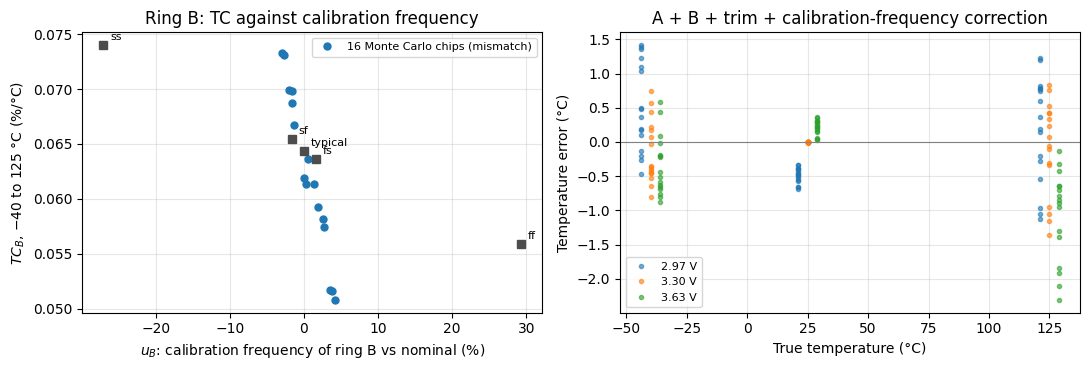

In [35]:
corner_u = np.log(cal.f_Hz_B / cal.loc["typical", "f_Hz_B"])
corner_tc = {c: 100 * np.log(d.set_index("temp_C").f_Hz_B[125] / d.set_index("temp_C").f_Hz_B[-40]) / 165
             for c, d in m[np.isclose(m.vdd_V, 3.30)].groupby("corner")}
print(f"correlation of TC_B with u_B over the Monte Carlo chips: {np.corrcoef(u_B, tc_B)[0, 1]:+.2f}")

mc["uB"] = mc.chip.map(u_B)
t_hat = (mc.eT_trim + mc.temp_C).to_numpy()
feat = mc.uB.to_numpy() * (t_hat - 25)
corrected = np.empty(len(mc))
for i in range(N_MC):
    tr = (mc.chip != i).to_numpy()
    c = (feat[tr] @ mc.eT_trim[tr]) / (feat[tr] @ feat[tr])
    corrected[~tr] = mc.eT_trim[~tr] - c * feat[~tr]
mc["eT_corr"] = corrected
ref = ref.assign(eT_corr=ref.eT_trim)
c_all = (feat @ mc.eT_trim) / (feat @ feat)
corr_table = pd.DataFrame({"A + B + supply trim": mc_row("eT_trim", False),
                           "   + calibration-frequency correction": mc_row("eT_corr", False)}).T.round(2)
try:
    display(corr_table)
except NameError:
    print(corr_table.to_string())
print(f"c fitted on all {N_MC} chips: {c_all:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(100 * u_B, tc_B, "o", ms=5, label=f"{N_MC} Monte Carlo chips (mismatch)")
for c in CORNERS:
    axes[0].plot(100 * corner_u[c], corner_tc[c], "s", color="0.3", ms=6)
    axes[0].annotate(c, (100 * corner_u[c], corner_tc[c]), textcoords="offset points", xytext=(5, 4), fontsize=8)
axes[0].set_xlabel("$u_B$: calibration frequency of ring B vs nominal (%)")
axes[0].set_ylabel("$TC_B$, −40 to 125 °C (%/°C)")
axes[0].set_title("Ring B: TC against calibration frequency")
axes[0].legend(fontsize=8)
for k, v in enumerate(VDDS):
    d = mc[np.isclose(mc.vdd_V, v)]
    axes[1].plot(d.temp_C + 4 * (k - 1), d.eT_corr, "o", ms=3, alpha=0.6, label=f"{v:.2f} V")
axes[1].axhline(0, color="0.5", lw=0.8)
axes[1].set_title("A + B + trim + calibration-frequency correction")
axes[1].set_xlabel("True temperature (°C)")
axes[1].set_ylabel("Temperature error (°C)")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

### 7.7 Interpretation

**Mismatch barely touches ring A but dominates the two-ring read-out.** Ring A alone keeps a 3σ spread of 0.33 °C, because its 22 devices average out. The two-ring read-out spreads ±8.0 °C (3σ; worst chip 5.4 °C), almost all from ring B: ring A's mismatch alone gives 0.43 °C. With 16 chips, these 3σ figures carry about ±20 % uncertainty.

**The culprit is the mirror reference shared by all stages.** Ring B's frequency spreads 2.4 % and its TC 12 %. The one-sigma shifts account for all of it: MNB, whose gate sets MNM and every nMOS starving device, carries about 73 % of the variance and MNM 22 %, while the 11 per-stage devices average out. An offset $\Delta V$ changes the copied current by about $2\Delta V/V_{ov}$ ($V_{ov} \approx 0.36$ V), and since $V_{ov}$ grows with temperature the relative error shrinks when hot: one offset moves both the frequency and the TC, which correlate at −0.98.

**Three ways out:** larger MNB and MNM (7.8), a second calibration temperature, or ring B's calibration frequency, which predicts the error: one coefficient fitted on the other chips brings the spread to ±2.4 °C (worst chip 2.3 °C). That last correction holds only on the typical corner: process moves the calibration frequency along a line about ten times flatter, so a usable model must tell process from mismatch, which needs the population of 7.9.

### 7.8 A fix to verify: larger mirror reference

Mismatch falls as $1/\sqrt{WL}$, so this section repeats the Monte Carlo with MNB and MNM at 8/4 µm instead of 2/1: the same $W/L$, 16 times the area, four times less $V_{TH}$ spread. The 11 MNS keep 2/1: their offsets average over the stages, and making them long too would remove the channel-length modulation that gives ring B part of its supply sensitivity (last line of the next cell: $S_{V,B}$ falls from about 20 to 8 %/V). The variant gets its own read-out fit on its typical corner, then the same 16 chips (same seeds), each with its own calibration and trim; ring A reuses 7.5. 170 simulations, cached.

In [36]:
# @title Monte Carlo of the 8/4 mirror (170 simulations, about 25 min in Colab)
FIX = {"wmir": 8.0, "lmir": 4.0}                  # MNB and MNM; the MNS keep 2/1
CSV_FIX = os.path.join(WORK, f"fix_mirror_{FIX['wmir']:g}x{FIX['lmir']:g}_{N_MC}.csv")
fix_jobs = ([("grid", -1, t, v) for t in TEMPS for v in VDDS]
            + [("mc", c, t, v) for c in range(N_MC) for t in MC_TEMPS for v in VDDS])


def fix_point(job):
    kind, chip, temp, vdd = job
    r = run_csro(bias=B_BIAS, temp=temp, vdd=vdd, mc_seed=None if chip < 0 else 2000 + chip, t_stop=0.9e-6, **FIX)
    return {"kind": kind, "chip": chip, "temp_C": temp, "vdd_V": vdd, "f_Hz": r["f"]}


fix_raw = pd.read_csv(CSV_FIX) if (os.path.exists(CSV_FIX) and not RERUN) else None
if fix_raw is not None and len(fix_raw) == len(fix_jobs):
    print(f"loaded {len(fix_raw)} simulations from {CSV_FIX}")
else:
    t0, rows = time.time(), []
    with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
        for i, row in enumerate(ex.map(fix_point, fix_jobs), 1):
            rows.append(row)
            if i % 33 == 0 or i == len(fix_jobs):
                print(f"{i}/{len(fix_jobs)} simulations ({time.time() - t0:.0f} s)", flush=True)
    fix_raw = pd.DataFrame(rows)
    fix_raw.to_csv(CSV_FIX, index=False)
    print("saved", CSV_FIX)

# the alternative: all 13 nMOS mirror devices (MNB, MNM and the MNS) at 8/4
alt = {k: run_csro(bias=B_BIAS, temp=t, vdd=v, t_stop=0.9e-6, wmir=8.0, lmir=4.0, wmns=8.0, lmns=4.0)["f"]
       for k, (t, v) in {"f0": (25, 3.30), "t0": (0, 3.30), "t55": (55, 3.30), "vm": (25, 2.97), "vp": (25, 3.63)}.items()}
print(f"all 13 nMOS mirror devices at 8/4: TC = {100 * (alt['t55'] - alt['t0']) / 55 / alt['f0']:.3f} %/C, "
      f"S_V = {100 * (alt['vp'] - alt['vm']) / 0.66 / alt['f0']:.1f} %/V")

33/165 simulations (318 s)
66/165 simulations (600 s)
99/165 simulations (904 s)
132/165 simulations (1217 s)
165/165 simulations (1508 s)
saved /content/gf180_work/fix_mirror_8x4_16.csv
all 13 nMOS mirror devices at 8/4: TC = 0.100 %/C, S_V = 8.4 %/V


,TC_B (%/C),"S_V,B (%/V)",cond(S),sigma TC_B (%/C),sigma f_B at 25 C (%),max |mean| (C),max 3 sigma (C),worst chip (C)
nMOS mirror devices,,,,,,,,
2/1 (design),0.0706,20.5402,2.0348,0.0074,2.4084,1.5546,8.0229,5.3926
+ calibration-frequency correction,NaN,NaN,NaN,NaN,NaN,1.0764,2.3558,2.3094
"MNB, MNM 8/4 (fix)",0.1204,21.7962,1.8716,0.0028,0.9550,1.2996,2.4001,2.3459
+ calibration-frequency correction,NaN,NaN,NaN,NaN,NaN,1.1999,2.2387,2.4607


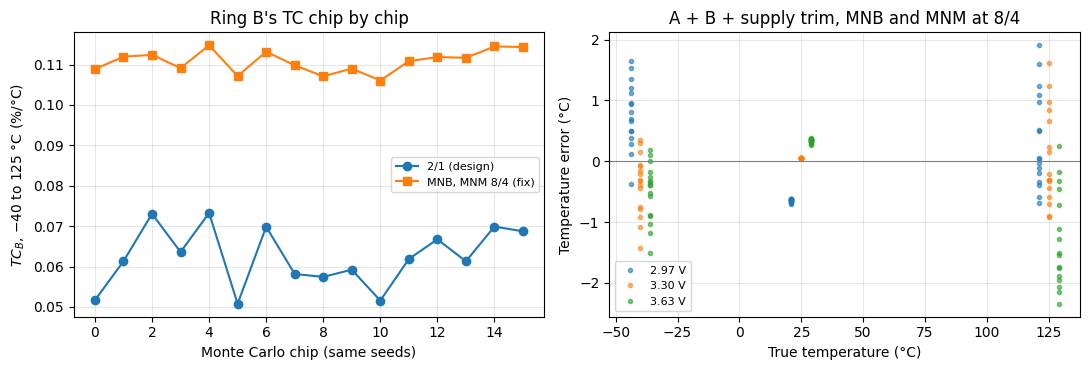

In [37]:
fx = fix_raw.assign(vdd_V=fix_raw.vdd_V.round(2))

# read-out fit for the variant, on its typical corner (ring A: the typical grid of section 6)
gB = fx[fx.kind == "grid"].set_index(["temp_C", "vdd_V"]).f_Hz
tA_pts = m[typ_rows].assign(vdd_V=m.vdd_V.round(2)).set_index(["temp_C", "vdd_V"])
gfit = pd.DataFrame({"xA": tA_pts.xA, "xB": np.log(gB / gB[(25, 3.30)])}).dropna()
k_fix_typ = ((gfit.xA[(25, 3.63)] - gfit.xA[(25, 2.97)]) / (gfit.xB[(25, 3.63)] - gfit.xB[(25, 2.97)]))
gfit = gfit.reset_index()
coef_fix = np.linalg.lstsq(basis_trim((gfit.xA - k_fix_typ * gfit.xB).to_numpy(), gfit.xB.to_numpy()),
                           gfit.temp_C.to_numpy(), rcond=None)[0]


def grid_sens(f):
    # TC (0 to 55 C) and S_V (2.97 to 3.63 V) around 25 C / 3.3 V from a typical grid, both relative to f(25, 3.3)
    return ((f[(55, 3.30)] - f[(0, 3.30)]) / 55 / f[(25, 3.30)], (f[(25, 3.63)] - f[(25, 2.97)]) / 0.66 / f[(25, 3.30)])


def typ_grid(df):
    d = df[df.corner == "typical"]
    return d.assign(vdd_V=d.vdd_V.round(2)).set_index(["temp_C", "vdd_V"]).f_Hz


tA_g, vA_g = grid_sens(typ_grid(pvt))
tc_des, sv_des = grid_sens(typ_grid(pvt_b))
tc_fix, sv_fix = grid_sens(gB)

# the same 16 chips: ring A from 7.5, ring B with the larger mirror devices
mf = (fx[fx.kind == "mc"].rename(columns={"f_Hz": "f_B"})[["chip", "temp_C", "vdd_V", "f_B"]]
      .merge(mc[["chip", "temp_C", "vdd_V", "f_A", "xA"]], on=["chip", "temp_C", "vdd_V"]))
calB = mf[(mf.temp_C == 25) & np.isclose(mf.vdd_V, 3.30)].set_index("chip").f_B
mf["xB"] = np.log(mf.f_B / mf.chip.map(calB))
s25f = mf[mf.temp_C == 25].sort_values("vdd_V")
vB_fix = s25f.groupby("chip").xB.apply(lambda x: (x.iloc[-1] - x.iloc[0]) / 0.66)
mf["eT_fix"] = (basis_trim((mf.xA - mf.chip.map(vA_mc / vB_fix) * mf.xB).to_numpy(), mf.xB.to_numpy()) @ coef_fix
                - mf.temp_C)
xb33f = mf[np.isclose(mf.vdd_V, 3.30)].pivot(index="chip", columns="temp_C", values="xB")
tc_B_fix = 100 * (xb33f[125] - xb33f[-40]) / 165

# calibration-frequency correction (leave-one-chip-out), as in 7.6
u_fix = np.log(calB / gB[(25, 3.30)])
feat_f = mf.chip.map(u_fix).to_numpy() * (mf.eT_fix + mf.temp_C - 25).to_numpy()
corr_f = np.empty(len(mf))
for i in range(N_MC):
    tr = (mf.chip != i).to_numpy()
    c = (feat_f[tr] @ mf.eT_fix[tr]) / (feat_f[tr] @ feat_f[tr])
    corr_f[~tr] = mf.eT_fix[~tr] - c * feat_f[~tr]
mf["eT_fix_corr"] = corr_f


def spread(d, col):
    per_point = d.groupby(["temp_C", "vdd_V"])[col]
    return per_point.mean().abs().max(), 3 * per_point.std().max(), d[col].abs().max()


rows = []
for name, d, col, tc, sv, tcs, fsd in (
        ("2/1 (design)", mc, "eT_trim", tc_des, sv_des, tc_B, cal_mc.f_B),
        ("   + calibration-frequency correction", mc, "eT_corr", np.nan, np.nan, None, None),
        ("MNB, MNM 8/4 (fix)", mf, "eT_fix", tc_fix, sv_fix, tc_B_fix, calB),
        ("   + calibration-frequency correction", mf, "eT_fix_corr", np.nan, np.nan, None, None)):
    mean, s3, worst = spread(d, col)
    rows.append({"nMOS mirror devices": name, "TC_B (%/C)": 100 * tc, "S_V,B (%/V)": 100 * sv,
                 "cond(S)": np.linalg.cond(np.array([[tA_g, vA_g], [tc, sv]]) * RANGES) if tc == tc else np.nan,
                 "sigma TC_B (%/C)": tcs.std() if tcs is not None else np.nan,
                 "sigma f_B at 25 C (%)": 100 * fsd.std() / fsd.mean() if fsd is not None else np.nan,
                 "max |mean| (C)": mean, "max 3 sigma (C)": s3, "worst chip (C)": worst})
fix_table = pd.DataFrame(rows).set_index("nMOS mirror devices").round(4)
try:
    display(fix_table)
except NameError:
    print(fix_table.to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(tc_B.index, tc_B, "o-", label="2/1 (design)")
axes[0].plot(tc_B_fix.index, tc_B_fix, "s-", label="MNB, MNM 8/4 (fix)")
axes[0].set_xlabel("Monte Carlo chip (same seeds)")
axes[0].set_ylabel("$TC_B$, −40 to 125 °C (%/°C)")
axes[0].set_title("Ring B's TC chip by chip")
axes[0].legend(fontsize=8)
for k, v in enumerate(VDDS):
    d = mf[np.isclose(mf.vdd_V, v)]
    axes[1].plot(d.temp_C + 4 * (k - 1), d.eT_fix, "o", ms=3, alpha=0.6, label=f"{v:.2f} V")
axes[1].axhline(0, color="0.5", lw=0.8)
axes[1].set_title("A + B + supply trim, MNB and MNM at 8/4")
axes[1].set_xlabel("True temperature (°C)")
axes[1].set_ylabel("Temperature error (°C)")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**The fix works where the diagnosis said it would.** Ring B's frequency spread falls from 2.4 to 0.96 % and its TC spread from 0.0074 to 0.0028 %/°C, close to the threefold reduction expected when the devices that carried 95 % of the variance get four times smaller offsets. The read-out follows: ±2.4 °C (3σ) instead of ±8.0 °C and 2.3 instead of 5.4 °C for the worst chip, for about 60 µm² of device area (4 % of ring B). TC_B rises from 0.071 to 0.120 %/°C while $S_{V,B}$ stays near 22 %/V, so the pair is slightly better conditioned (1.9 instead of 2.0).

**Why not all 13 devices.** With the MNS long as well, $S_{V,B}$ drops to 8.4 %/V; the per-chip trim ratio $v_A/v_B$ then grows and amplifies the spread of $v_B$, and in a trial run the read-out got worse. A fix has to be checked against every quantity the read-out uses.

**Across the corners.** The cell below repeats the corner study of 7.3 for the variant (same grid, its own calibration and trim per corner, read-out fitted on its typical corner); section 9 lays it out.

In [38]:
# @title The 8/4 mirror across the corners (84 simulations, about 15 min in Colab)
CSV_FIXC = os.path.join(WORK, f"fix_mirror_{FIX['wmir']:g}x{FIX['lmir']:g}_corners.csv")
fixc_jobs = [(c, t, v) for c in CORNERS if c != "typical" for t in TEMPS for v in VDDS]


def fixc_point(p):
    corner, temp, vdd = p
    r = run_csro(bias=B_BIAS, corner=corner, temp=temp, vdd=vdd, t_stop=0.9e-6, **FIX)
    return {"corner": corner, "temp_C": temp, "vdd_V": vdd, "f_Hz": r["f"]}


fixc = pd.read_csv(CSV_FIXC) if (os.path.exists(CSV_FIXC) and not RERUN) else None
if fixc is not None and len(fixc) == len(fixc_jobs):
    print(f"loaded {len(fixc)} points from {CSV_FIXC}")
else:
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
        fixc = pd.DataFrame(list(ex.map(fixc_point, fixc_jobs)))
    fixc.to_csv(CSV_FIXC, index=False)
    print(f"saved {CSV_FIXC} ({time.time() - t0:.0f} s)")

# read-out of 7.3 with ring B replaced by the variant (typical grid from the first cell of 7.8)
grid_fix = pd.concat([fixc, fx[fx.kind == "grid"].assign(corner="typical")[["corner", "temp_C", "vdd_V", "f_Hz"]]])
mfx = (pvt[["corner", "temp_C", "vdd_V", "f_Hz"]].assign(vdd_V=pvt.vdd_V.round(2))
       .merge(grid_fix.assign(vdd_V=grid_fix.vdd_V.round(2)), on=["corner", "temp_C", "vdd_V"], suffixes=("_A", "_B")))
cal_fx = mfx[(mfx.temp_C == 25) & (mfx.vdd_V == 3.30)].set_index("corner")
mfx["xA"] = np.log(mfx.f_Hz_A / mfx.corner.map(cal_fx.f_Hz_A))
mfx["xB"] = np.log(mfx.f_Hz_B / mfx.corner.map(cal_fx.f_Hz_B))
d25f = mfx[mfx.temp_C == 25].sort_values("vdd_V")
vA_fx = d25f.groupby("corner").xA.apply(lambda x: (x.iloc[-1] - x.iloc[0]) / 0.66)
vB_fx = d25f.groupby("corner").xB.apply(lambda x: (x.iloc[-1] - x.iloc[0]) / 0.66)
mfx["eT_fix"] = (basis_trim((mfx.xA - mfx.corner.map(vA_fx / vB_fx) * mfx.xB).to_numpy(), mfx.xB.to_numpy())
                 @ coef_fix - mfx.temp_C)
fix_corner_rows = []
for c in CORNERS:
    tc_d, sv_d = grid_sens(pvt_b[pvt_b.corner == c].assign(vdd_V=pvt_b.vdd_V.round(2)).set_index(["temp_C", "vdd_V"]).f_Hz)
    tc_c, sv_c = grid_sens(mfx[mfx.corner == c].set_index(["temp_C", "vdd_V"]).f_Hz_B)
    fix_corner_rows.append({"corner": c, "design 2/1: max |error| (C)": readout.loc[c, "3) A + B + supply trim (C)"],
                            "fix 8/4: max |error| (C)": mfx[mfx.corner == c].eT_fix.abs().max(),
                            "design 2/1: TC_B (%/C)": 100 * tc_d, "fix 8/4: TC_B (%/C)": 100 * tc_c,
                            "design 2/1: S_V,B (%/V)": 100 * sv_d, "fix 8/4: S_V,B (%/V)": 100 * sv_c})
fix_corner_table = pd.DataFrame(fix_corner_rows).set_index("corner").round(3)
try:
    display(fix_corner_table)
except NameError:
    print(fix_corner_table.to_string())

saved /content/gf180_work/fix_mirror_8x4_corners.csv (868 s)


,design 2/1: max |error| (C),fix 8/4: max |error| (C),design 2/1: TC_B (%/C),fix 8/4: TC_B (%/C),"design 2/1: S_V,B (%/V)","fix 8/4: S_V,B (%/V)"
corner,,,,,,
typical,0.84,1.118,0.071,0.120,20.540,21.796
ff,4.90,5.490,0.062,0.105,16.563,17.245
ss,2.00,3.393,0.081,0.138,26.514,28.338
fs,1.33,2.530,0.070,0.125,20.454,22.099
sf,1.10,2.739,0.072,0.116,20.924,21.802


**The fix costs some corner robustness, for a different reason than expected.** Ring B's TC moves across the corners by the same relative amount in both versions (−13 % in ff, +14 to +15 % in ss), so the length difference between MNB and the MNS does not make the mirror more process-dependent. But the variant's TC is 70 % larger, so the same relative change moves the read-out further: up to 5.5 °C in ff (4.9 °C for the design), 3.4 °C in ss (2.0 °C) and 2.5 to 2.7 °C in fs and sf (1.1 to 1.3 °C). Against the mismatch it removes (±8.0 to ±2.4 °C, 3σ), the trade still favours the variant for a one-temperature calibration, where mismatch dominates.

### 7.9 Process and mismatch together: one calibration temperature, a learned correction, or two temperatures

Sections 7.3 and 7.5 treat process and mismatch apart; a real wafer has both, and 7.7 left an open question, since process moves ring B's calibration frequency too. This section builds a population with both and asks how far one calibration temperature is from the ±2 °C of the corner study, and whether a model learned from a characterized population can close the gap using only what a tester measures at that temperature.

**The population.** The `statistical` and `res_statistical` sections of the GF180MCU models draw global process parameters ($V_{TH}$, oxide thickness, length and width offsets of each device type, poly sheet resistance) with `agauss`. Each chip gets its own copy with every draw replaced by a seeded random number, so rings A and B share one die, plus its own mismatch seeds as in 7.5; all draws at zero reproduce the typical corner.

**The data.** Per chip, both rings at the 9 points of 7.5 with their supply currents, ring A at 25 °C and 1.2 V (an extra calibration input for 7.10), and both rings at 85 °C (only as a two-temperature reference): 21 simulations per chip, 48 chips. Chips 0 to 23 train, chips 24 to 47 only test.  In Colab these 1008 simulations take about 2 h 40 min.

In [39]:
# @title Process + mismatch population (1008 simulations, about 2 h 40 min in Colab)
N_G = 48                                 # chips with global process + mismatch
N_TRAIN = 24                             # chips 0..23 train the correction of 7.10; chips 24..47 only test it
G_POINTS = [(t, v) for t in MC_TEMPS for v in VDDS] + [(85, 3.30)]
A_LOW = 1.20                             # V: ring A's extra calibration point at 25 C
CHIP_DIR = os.path.join(WORK, "chips")
os.makedirs(CHIP_DIR, exist_ok=True)
_AGAUSS = re.compile(r"agauss\(\s*([-+\d.eE]+)\s*,\s*([-+\d.eE]+)\s*,\s*([-+\d.eE]+)\s*\)")


def chip_lib(k):
    # global process sample k: the statistical sections of sm141064.spice with each agauss() replaced by a draw
    path = os.path.join(CHIP_DIR, f"chip{k:02d}.lib")
    if not os.path.exists(path):
        text = open(os.path.join(GF180_MODELS, "sm141064.spice")).read()
        rng = np.random.default_rng(7000 + k)
        out = []
        for name in ("statistical", "res_statistical"):
            body = re.search(rf"^\.lib {name}\n(.*?)^\.endl {name}\n", text, re.S | re.M).group(1)
            body = _AGAUSS.sub(lambda mt: f"{float(mt[1]) + float(mt[2]) / float(mt[3]) * rng.standard_normal():.6g}",
                               body)
            body = body.replace("'sm141064.spice'", f"'{os.path.join(GF180_MODELS, 'sm141064.spice')}'")
            out.append(f".lib {name}\n{body}.endl {name}\n")
        with open(path, "w") as f:
            f.write("\n".join(out))
    return path


def ring_a_window(vdd):
    # a slow chip at 125 C and 2.97 V needs about 40 ns for 30 periods; at 1.2 V the ring runs near 250 MHz
    return {"t_stop": 200e-9, "t_step": 5e-12} if vdd < 2 else {"t_stop": 45e-9, "t_step": 2e-12}


def g_point(job):
    k, ring, temp, vdd = job
    if ring == "A":
        r = run_ro(corner=chip_lib(k), temp=temp, vdd=vdd, mc_seed=5000 + k, **ring_a_window(vdd))
    else:
        r = run_csro(bias=B_BIAS, corner=chip_lib(k), temp=temp, vdd=vdd, mc_seed=6000 + k)
    return {"chip": k, "ring": ring, "temp_C": temp, "vdd_V": vdd, "f_Hz": r["f"], "power_W": r["power"],
            "retries": r["retries"]}


CSV_G = os.path.join(WORK, f"mc_global_{N_G}.csv")
g_jobs = ([(k, ring, t, v) for k in range(N_G) for ring in ("A", "B") for t, v in G_POINTS]
          + [(k, "A", 25, A_LOW) for k in range(N_G)])
g_raw = pd.read_csv(CSV_G) if (os.path.exists(CSV_G) and not RERUN) else None
if g_raw is not None and len(g_raw) == len(g_jobs):
    print(f"loaded {len(g_raw)} simulations from {CSV_G}")
else:
    for k in range(N_G):
        chip_lib(k)
    t0, rows = time.time(), []
    with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
        for i, row in enumerate(ex.map(g_point, g_jobs), 1):
            rows.append(row)
            if i % 48 == 0 or i == len(g_jobs):
                print(f"{i}/{len(g_jobs)} simulations ({time.time() - t0:.0f} s)", flush=True)
    g_raw = pd.DataFrame(rows)
    g_raw.to_csv(CSV_G, index=False)
    print("saved", CSV_G)
print(f"simulations that needed a longer window: {int((g_raw.retries > 0).sum())} of {len(g_raw)}")

48/1008 simulations (441 s)
96/1008 simulations (903 s)
144/1008 simulations (1360 s)
192/1008 simulations (1819 s)
240/1008 simulations (2304 s)
288/1008 simulations (2740 s)
336/1008 simulations (3204 s)
384/1008 simulations (3652 s)
432/1008 simulations (4089 s)
480/1008 simulations (4573 s)
528/1008 simulations (4997 s)
576/1008 simulations (5463 s)
624/1008 simulations (5923 s)
672/1008 simulations (6387 s)
720/1008 simulations (6907 s)
768/1008 simulations (7345 s)
816/1008 simulations (7806 s)
864/1008 simulations (8269 s)
912/1008 simulations (8712 s)
960/1008 simulations (9204 s)
1008/1008 simulations (9711 s)
saved /content/gf180_work/mc_global_48.csv
simulations that needed a longer window: 0 of 1008


48 chips, TC from -40 to 125 C (mean, 1 sigma): ring A -0.1837, 0.0032 %/C; ring B 0.0644, 0.0072 %/C; correlation 0.21
read-out variable z = xA - (vA/vB) xB, vA/vB = 1.07: TC -0.2529 %/C, 1 sigma 0.0077 %/C (3.0 %)


,max |mean| (C),max 3 sigma (C),worst chip (C),rms (C)
1 temperature (25 C) + supply trim,0.95,9.41,8.21,2.02
2 temperatures (25 and 85 C) + supply trim,1.44,1.43,2.13,0.68
"2 temperatures, read-out refitted for them",0.37,0.59,1.00,0.22


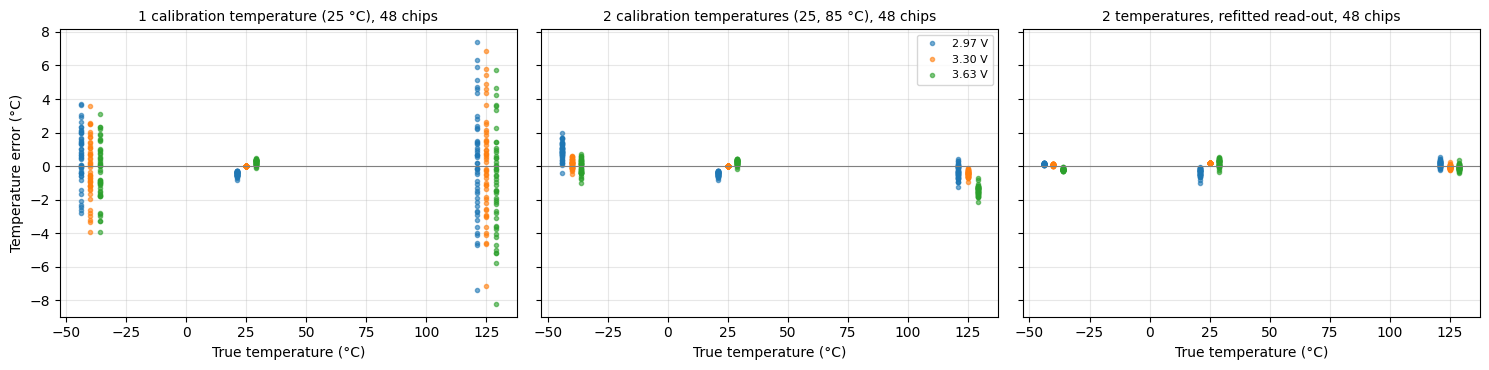

In [40]:
# per-chip calibration at 25 C / 3.3 V and supply trim, read-out coefficients of 7.3 (typical corner), as in 7.5
gq = g_raw.assign(vdd_V=g_raw.vdd_V.round(2))
gm = (gq[gq.vdd_V > 2].pivot_table(index=["chip", "temp_C", "vdd_V"], columns="ring", values="f_Hz")
      .reset_index())
gm.columns.name = None
gm = gm.rename(columns={"A": "f_A", "B": "f_B"})
gcal = gm[(gm.temp_C == 25) & (gm.vdd_V == 3.30)].set_index("chip")
gm["xA"] = np.log(gm.f_A / gm.chip.map(gcal.f_A))
gm["xB"] = np.log(gm.f_B / gm.chip.map(gcal.f_B))
g25 = gm[gm.temp_C == 25].sort_values("vdd_V")
vA_g = g25.groupby("chip").xA.apply(lambda x: (x.iloc[-1] - x.iloc[0]) / 0.66)
vB_g = g25.groupby("chip").xB.apply(lambda x: (x.iloc[-1] - x.iloc[0]) / 0.66)
gm["T_hat"] = basis_trim((gm.xA - gm.chip.map(vA_g / vB_g) * gm.xB).to_numpy(), gm.xB.to_numpy()) @ coef_t
gm["e_1pt"] = gm.T_hat - gm.temp_C

# a second calibration temperature (85 C, 3.3 V) measures each chip's own gain:
# T = 25 + (T_hat - 25) * 60 / (T_hat(85 C) - 25)
t85 = gm[gm.temp_C == 85].set_index("chip").T_hat
gm["e_2pt"] = 25 + (gm.T_hat - 25) * gm.chip.map(60 / (t85 - 25)) - gm.temp_C
gt = gm[gm.temp_C != 85].copy()                       # the 9 test points of 7.5 for every chip

# the read-out of 7.3 refitted for the two-point scheme: the same polynomial basis, now in the two-point reading and
# xB, fitted on the population (leave-one-chip-out here; on the training chips only in 7.10 and 7.11)
gt["T_2pt"] = gt.e_2pt + gt.temp_C


def basis_2pt(d):
    return basis_trim(((d.T_2pt - 25) / 100).to_numpy(), d.xB.to_numpy())


B2 = basis_2pt(gt)
e2 = np.empty(len(gt))
for k in gt.chip.unique():
    tr, te = (gt.chip != k).to_numpy(), (gt.chip == k).to_numpy()
    e2[te] = B2[te] @ np.linalg.lstsq(B2[tr], gt.temp_C.to_numpy()[tr], rcond=None)[0] - gt.temp_C.to_numpy()[te]
gt["e_2pt_fit"] = e2


def pop_stats(d, col):
    per_point = d.groupby(["temp_C", "vdd_V"])[col]
    return {"max |mean| (C)": per_point.mean().abs().max(), "max 3 sigma (C)": 3 * per_point.std().max(),
            "worst chip (C)": d[col].abs().max(), "rms (C)": np.sqrt((d[col] ** 2).mean())}


# each ring's TC from -40 to 125 C at 3.3 V, chip by chip
g33 = gm[gm.vdd_V == 3.30].pivot(index="chip", columns="temp_C", values=["f_A", "f_B"])
tc_g = pd.DataFrame({ring: 100 * np.log(g33[(f"f_{ring}", 125)] / g33[(f"f_{ring}", -40)]) / 165
                     for ring in ("A", "B")})
k_g = float((vA_g / vB_g).median())
tc_z = tc_g.A - k_g * tc_g.B
print(f"{N_G} chips, TC from -40 to 125 C (mean, 1 sigma): ring A {tc_g.A.mean():.4f}, {tc_g.A.std():.4f} %/C; "
      f"ring B {tc_g.B.mean():.4f}, {tc_g.B.std():.4f} %/C; correlation {tc_g.A.corr(tc_g.B):.2f}")
print(f"read-out variable z = xA - (vA/vB) xB, vA/vB = {k_g:.2f}: TC {tc_z.mean():.4f} %/C, "
      f"1 sigma {tc_z.std():.4f} %/C ({100 * tc_z.std() / abs(tc_z.mean()):.1f} %)")

pop_table = pd.DataFrame({
    "1 temperature (25 C) + supply trim": pop_stats(gt, "e_1pt"),
    "2 temperatures (25 and 85 C) + supply trim": pop_stats(gt, "e_2pt"),
    "2 temperatures, read-out refitted for them": pop_stats(gt, "e_2pt_fit")}).T.round(2)
try:
    display(pop_table)
except NameError:
    print(pop_table.to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, col, title in zip(axes, ["e_1pt", "e_2pt", "e_2pt_fit"],
                          ["1 calibration temperature (25 °C)", "2 calibration temperatures (25, 85 °C)",
                           "2 temperatures, refitted read-out"]):
    for k, v in enumerate(VDDS):
        d = gt[gt.vdd_V == round(v, 2)]
        ax.plot(d.temp_C + 4 * (k - 1), d[col], "o", ms=3, alpha=0.6, label=f"{v:.2f} V")
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_title(f"{title}, {N_G} chips", fontsize=10)
    ax.set_xlabel("True temperature (°C)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Temperature error (°C)")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

**One calibration temperature: ±9.4 °C (3σ).** The read-out of 7.3 (each chip's own calibration and trim, typical-corner coefficients) stays nearly unbiased (largest mean error about 1 °C) but spreads ±9.4 °C (3σ), 8.2 °C for the worst of 48 chips. The spread is a gain error that follows each chip's TC of $z$, which varies by 3.0 % (1σ). Ring B's TC varies by 11 % (0.0072 %/°C) and ring A's by 2 % (0.0032 %/°C); being only weakly correlated (0.2), they add. The result is close to the mismatch-only ±8.0 °C of 7.5, so ring B's mismatch is still the larger part.

**Two calibration temperatures: ±1.4 °C, or ±0.6 °C with a read-out fitted for them.** A second point at 85 °C measures each chip's gain. With the read-out of 7.3 a mean error of up to 1.4 °C remains, the same on every chip; refitting the same polynomial on the two-point reading (leave-one-chip-out) removes it: ±0.6 °C (3σ), worst chip 1.0 °C, close to the ±0.3 °C numerical precision of these simulations. That is the class of the best two-point sensors (section 10), but a second temperature is costly in production. BJT sensors avoid the chamber with an on-chip heater, because their $\Delta V_{BE}$ tells the heated temperature [Yousefzadeh 2020]; a ring oscillator lacks that built-in reference.

### 7.10 A learned single-temperature calibration

Can each chip's gain error be predicted from what it shows at 25 °C, with a model trained on a population whose true temperatures are known? In production that population would be chips characterized once at several temperatures, the idea behind batch calibration [Pertijs 2010]; here it is the 24 training chips. The model never sees a chip away from 25 °C.

**Inputs, measured at 25 °C relative to the nominal chip:**

- $u_A$, $u_B$: each ring's frequency at 3.3 V; $\delta v_A$, $\delta v_B$: each ring's supply slope, already measured for the trim.
- $s_A$: ring A's frequency at 1.2 V relative to 3.3 V. A $V_{TH}$ shift changes ring A's TC through the overdrive, while mobility, oxide or length shifts mostly scale the current. At 3.3 V both look alike; at 1.2 V the small overdrive makes the $V_{TH}$ shift weigh several times more.
- $q_A$, $q_B$: each ring's supply charge per period, $I_{DD}/f$. For ring A it is switched capacitance times swing; for ring B it includes the bias branches, whose current the resistor sets, so it sees the sheet resistance apart from the devices.

**Model.** With $g = (\hat T - 25\ \text{°C})/100\ \text{°C}$, each chip's error is a gain and a curvature term linear in the scaled inputs $\phi$, $e = g\,(a_0 + \mathbf a\cdot\phi) + g^2\,(b_0 + \mathbf b\cdot\phi)$, subtracted from the reading. It is fitted by ridge regression, with $\lambda$ chosen by leave-one-chip-out cross-validation on the training chips and the inputs scaled with training statistics only; the test chips take part in nothing but the final evaluation. Two versions: the inputs the read-out already has ($u$, $\delta v$), and those plus $s_A$, $q_A$, $q_B$.

**Related work.** In ring-oscillator test structures, frequency with supply current separates capacitance from drive and delay versus $V_{DD}$ reveals $V_{TH}$ [Bhushan 2006]; ring frequencies at several supplies feed a learned $V_{TH}$ predictor in [Huang 2017]; predicting a costly quantity from cheap on-chip measurements with a population-trained regression is indirect performance sensing [Sun 2014]. For temperature sensors, [Datta 2010] corrects slope and offset with a dedicated process sensor and an analytical model, and [Gondo 2020] estimates temperature and voltage from several rings with support-vector regression. As far as we know, learning a two-ring sensor's per-chip gain from the sensing rings' own measurements at the calibration temperature, without added circuitry, has not been reported.

test chips 24 to 47,max |mean| (C),max 3 sigma (C),worst chip (C),rms (C),lambda
1 temperature + supply trim,1.472,9.996,8.206,2.148,NaN
+ learned correction: frequencies and supply slopes only,1.480,8.038,7.269,1.802,100.0
+ learned correction: + supply currents and ring A at 1.2 V,1.441,5.308,4.658,1.319,1.0
2 temperatures + supply trim,1.491,1.760,2.131,0.705,NaN
"2 temperatures, read-out refitted on the training chips",0.369,0.689,0.993,0.227,NaN


R^2 (below 0: worse than the mean),"TC_A, training (LOO)","TC_A, test","TC_B, training (LOO)","TC_B, test","TC_z, training (LOO)","TC_z, test"
frequencies and supply slopes only,0.01,-0.30,0.61,0.87,0.01,0.63
+ supply currents and ring A at 1.2 V,0.64,0.32,0.71,0.90,0.69,0.77


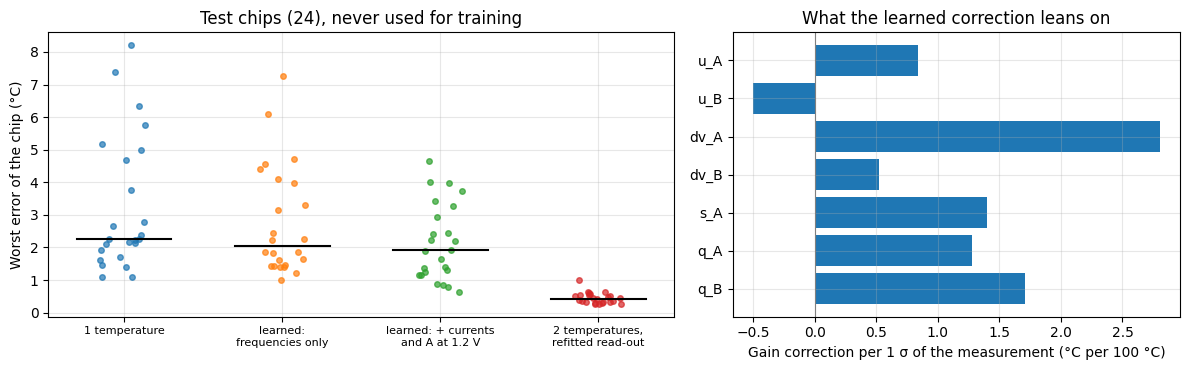

In [41]:
# what a tester measures on each chip at 25 C, relative to the nominal typical chip (all in %)
c25 = gq[gq.temp_C == 25]
f_low = c25[(c25.ring == "A") & (c25.vdd_V == A_LOW)].set_index("chip").f_Hz
p33 = c25[c25.vdd_V == 3.30].pivot(index="chip", columns="ring", values="power_W")
f_low_typ = run_ro(temp=25, vdd=A_LOW, **ring_a_window(A_LOW))["f"]       # nominal chip at 1.2 V


def charge(p, f):
    return p / (3.30 * f)                                  # supply charge per period


feat = pd.DataFrame({
    "u_A": 100 * np.log(gcal.f_A / cal.loc["typical", "f_Hz_A"]),     # frequency at 3.3 V
    "u_B": 100 * np.log(gcal.f_B / cal.loc["typical", "f_Hz_B"]),
    "dv_A": 100 * (vA_g - v_A["typical"]),                             # supply slope (%/V)
    "dv_B": 100 * (vB_g - v_B["typical"]),
    "s_A": 100 * np.log(f_low / f_low_typ) - 100 * np.log(gcal.f_A / cal.loc["typical", "f_Hz_A"]),
    "q_A": 100 * np.log(charge(p33.A, gcal.f_A) / charge(cal.loc["typical", "power_W_A"],
                                                          cal.loc["typical", "f_Hz_A"])),
    "q_B": 100 * np.log(charge(p33.B, gcal.f_B) / charge(cal.loc["typical", "power_W_B"],
                                                          cal.loc["typical", "f_Hz_B"]))})
MODELS = {"frequencies and supply slopes only": ["u_A", "u_B", "dv_A", "dv_B"],
          "+ supply currents and ring A at 1.2 V": ["u_A", "u_B", "dv_A", "dv_B", "s_A", "q_A", "q_B"]}
train = gt[gt.chip < N_TRAIN]
test = gt[gt.chip >= N_TRAIN].copy()
coef_2pt = np.linalg.lstsq(basis_2pt(train), train.temp_C.to_numpy(), rcond=None)[0]   # training chips only
test["e_2pt_fit"] = basis_2pt(test) @ coef_2pt - test.temp_C
zf = (feat - feat.loc[:N_TRAIN - 1].mean()) / feat.loc[:N_TRAIN - 1].std()   # scaled with training chips only


def design(d, cols):
    # error = g * (a0 + a . phi) + g^2 * (b0 + b . phi), g = (T_hat - 25 C) / 100 C: each chip gets a gain and a
    # curvature error, both linear in its scaled calibration measurements phi
    g = ((d.T_hat - 25) / 100).to_numpy()[:, None]
    phi = np.column_stack([np.ones(len(d))] + [zf.loc[d.chip, c].to_numpy() for c in cols])
    return np.hstack([phi * g, phi * g ** 2])


def ridge(d, cols, lam):
    X = design(d, cols)
    return np.linalg.solve(X.T @ X + lam * np.eye(X.shape[1]), X.T @ d.e_1pt.to_numpy())


def cv_rms(cols, lam):
    # leave-one-chip-out inside the training chips; the test chips play no part in any choice
    res = [d.e_1pt.to_numpy() - design(d, cols) @ ridge(train[train.chip != k], cols, lam)
           for k, d in train.groupby("chip")]
    return np.sqrt(np.mean(np.concatenate(res) ** 2))


LAMBDAS = [1e-3, 1e-2, 1e-1, 1, 10, 100]
rows, weights = {"1 temperature + supply trim": {**pop_stats(test, "e_1pt"), "lambda": np.nan}}, {}
for name, cols in MODELS.items():
    lam = min(LAMBDAS, key=lambda x: cv_rms(cols, x))
    w = ridge(train, cols, lam)
    weights[name] = pd.Series(w[1:len(cols) + 1], index=cols)
    test[name] = test.e_1pt - design(test, cols) @ w
    rows[f"   + learned correction: {name}"] = {**pop_stats(test, name), "lambda": lam}
rows["2 temperatures + supply trim"] = {**pop_stats(test, "e_2pt"), "lambda": np.nan}
rows["2 temperatures, read-out refitted on the training chips"] = {**pop_stats(test, "e_2pt_fit"), "lambda": np.nan}
learn_table = pd.DataFrame(rows).T.round(3)
learn_table.columns.name = f"test chips {N_TRAIN} to {N_G - 1}"
try:
    display(learn_table)
except NameError:
    print(learn_table.to_string())

# how much of each TC spread the calibration measurements explain (least squares): leave-one-chip-out inside the
# training chips, and trained on all of them for the test chips. TC_z is the TC of the read-out variable
# z = xA - (vA/vB) xB, the chip's gain.
tr_c, te_c = np.arange(N_TRAIN), np.arange(N_TRAIN, N_G)


def r2(y, pred):
    return 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()


r2_rows = {}
for name, cols in MODELS.items():
    X = np.column_stack([np.ones(N_G), zf[cols].to_numpy()])
    for label, y in (("TC_A", tc_g.A), ("TC_B", tc_g.B), ("TC_z", tc_z)):
        y = y.to_numpy()
        loo = [X[k] @ np.linalg.lstsq(X[tr_c[tr_c != k]], y[tr_c[tr_c != k]], rcond=None)[0] for k in tr_c]
        b = np.linalg.lstsq(X[tr_c], y[tr_c], rcond=None)[0]
        r2_rows[(name, f"{label}, training (LOO)")] = r2(y[tr_c], np.array(loo))
        r2_rows[(name, f"{label}, test")] = r2(y[te_c], X[te_c] @ b)
r2_table = pd.Series(r2_rows).unstack().reindex(index=list(MODELS), columns=list(dict.fromkeys(
    c for _, c in r2_rows))).round(2)
r2_table.columns.name = "R^2 (below 0: worse than the mean)"
try:
    display(r2_table)
except NameError:
    print(r2_table.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.4, 1]})
cases = [("1 temperature", "e_1pt"), ("learned:\nfrequencies only", list(MODELS)[0]),
         ("learned: + currents\nand A at 1.2 V", list(MODELS)[1]), ("2 temperatures,\nrefitted read-out", "e_2pt_fit")]
for i, (label, col) in enumerate(cases):
    worst_chip = test.groupby("chip")[col].apply(lambda e: e.abs().max())
    axes[0].plot(i + 0.15 * np.random.default_rng(i).uniform(-1, 1, len(worst_chip)), worst_chip, "o", ms=4,
                 alpha=0.7)
    axes[0].plot([i - 0.3, i + 0.3], [worst_chip.median()] * 2, "k-", lw=1.5)
axes[0].set_xticks(range(len(cases)), [c[0] for c in cases], fontsize=8)
axes[0].set_ylabel("Worst error of the chip (°C)")
axes[0].set_title(f"Test chips ({N_G - N_TRAIN}), never used for training")
wl = weights[list(MODELS)[1]]
axes[1].barh(wl.index[::-1], wl.to_numpy()[::-1])
axes[1].axvline(0, color="0.5", lw=0.8)
axes[1].set_xlabel("Gain correction per 1 σ of the measurement (°C per 100 °C)")
axes[1].set_title("What the learned correction leans on")
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**On unseen chips, the learned correction roughly halves the error.** Over the 24 test chips the 3σ spread falls from ±10.0 to ±5.3 °C, the worst chip from 8.2 to 4.7 °C and the rms error from 2.1 to 1.3 °C ($\lambda = 1$, 16 coefficients, 216 training points). With frequencies and supply slopes only it reaches ±8.0 °C: cross-validation finds little to learn there.

**Why the extra measurements matter.** From frequencies alone, ring B's TC is partly predictable (R² 0.61 in training, 0.87 on test), because the mirror and resistor that spread it also move its frequency; ring A's is not (R² 0.01 and −0.30). In the training chips both rings spread the gain comparably, so $TC_z$ is unpredictable there (R² 0.01). With $s_A$, $q_A$ and $q_B$ it becomes predictable in both groups (0.69 and 0.77). The model leans on ring A's supply slope and 1.2 V speed, both set by its overdrive, and on the two charges per period.

**Cost and limits.** No extra temperature, but one more supply setting and a per-ring supply-current measurement. The correction stays far from a second temperature (±5.3 against ±0.7 °C on the same chips), because ring A's TC remains only partly predictable (R² 0.32 on test). It learns the PDK's statistical description, not silicon; 7.11 tests how to adapt it. With 24 training chips, a linear model with physically chosen inputs is the right size.

### 7.11 From simulation to silicon: Bayesian model fusion

A model trained on simulation carries whatever bias the PDK has against silicon, and training on silicon alone fails too: every training chip must be characterized at several temperatures, and 16 coefficients cannot be fitted on one or two chips.

**Bayesian model fusion** [Wang 2013], used for on-chip performance sensing in [Sun 2014], combines both: the simulation-trained coefficients $\mathbf w_{sim}$ are a Gaussian prior and a few *golden* chips, characterized at several temperatures, are the evidence. The maximum-a-posteriori coefficients are

$$\mathbf w = \arg\min_{\mathbf w}\ \frac{\lVert \mathbf y - X\mathbf w\rVert^2}{\sigma^2} + \sum_k \frac{(w_k - w_{sim,k})^2}{s_k^2},$$

a ridge regression pulled toward the simulation model instead of toward zero. $\sigma$ is the simulation model's residual on its training chips. The prior width $s_k$ of each input coefficient is its bootstrap spread over the training chips; the intercepts $a_0$, $b_0$, where a population-wide gap shows first, get 5 °C per 100 °C, the size of the corner residual of 7.3.

**An emulated silicon lot.** 24 new chips drawn as in 7.9, but with the `ppolyf_u_1k` body TC at −845 instead of −939 ppm/°C, a 10 % model error that nothing in 7.10 knows about. From this lot, $k$ = 1, 2, 4 or 8 golden chips are drawn (every chip for $k = 1$, 40 random draws otherwise), and each method is scored on the rest of the lot.  The 504 simulations of the lot take about 1 h 20 min in Colab.

In [42]:
# @title Emulated silicon lot (504 simulations, about 1 h 20 min in Colab)
# the "silicon" lot: global process + mismatch as in 7.9, with the poly resistor's first-order TC 10 % smaller
TC1_MODEL, TC1_SILICON = -9.39e-4, -8.45e-4
SI_CHIPS = range(100, 124)                                 # random seeds 100 to 123, apart from 7.9
_text = open(os.path.join(GF180_MODELS, "sm141064.spice")).read()
_res = re.search(r"^\.lib res\n(.*?)^\.endl res\n", _text, re.S | re.M).group(1)
_i = _res.index(".subckt ppolyf_u_1k ")
_j = _res.index(".ends ppolyf_u_1k", _i)
_tc1_line = ".param r_tc1=-9.39e-4"                     # as written in the model file
assert _res[_i:_j].count(_tc1_line) == 1
SI_RES = os.path.join(CHIP_DIR, "silicon_res.lib")
with open(SI_RES, "w") as f:
    f.write(".lib res\n" + _res[:_i] + _res[_i:_j].replace(_tc1_line, f".param r_tc1={TC1_SILICON}")
            + _res[_j:] + ".endl res\n")


def chip_lib_si(k):
    # as chip_lib (7.9), with the resistor models taken from the modified copy
    path = os.path.join(CHIP_DIR, f"chip{k:03d}_si.lib")
    if not os.path.exists(path):
        rng = np.random.default_rng(7000 + k)
        out = []
        for name in ("statistical", "res_statistical"):
            body = re.search(rf"^\.lib {name}\n(.*?)^\.endl {name}\n", _text, re.S | re.M).group(1)
            body = _AGAUSS.sub(lambda mt: f"{float(mt[1]) + float(mt[2]) / float(mt[3]) * rng.standard_normal():.6g}",
                               body)
            body = body.replace("'sm141064.spice'", f"'{os.path.join(GF180_MODELS, 'sm141064.spice')}'")
            if name == "res_statistical":
                body = body.replace(f"'{os.path.join(GF180_MODELS, 'sm141064.spice')}' res\n", f"'{SI_RES}' res\n")
            out.append(f".lib {name}\n{body}.endl {name}\n")
        with open(path, "w") as f:
            f.write("\n".join(out))
    return path


def si_point(job):
    k, ring, temp, vdd = job
    if ring == "A":
        r = run_ro(corner=chip_lib_si(k), temp=temp, vdd=vdd, mc_seed=5000 + k, **ring_a_window(vdd))
    else:
        r = run_csro(bias=B_BIAS, corner=chip_lib_si(k), temp=temp, vdd=vdd, mc_seed=6000 + k)
    return {"chip": k, "ring": ring, "temp_C": temp, "vdd_V": vdd, "f_Hz": r["f"], "power_W": r["power"],
            "retries": r["retries"]}


CSV_SI = os.path.join(WORK, f"silicon_lot_{len(SI_CHIPS)}.csv")
si_jobs = ([(k, ring, t, v) for k in SI_CHIPS for ring in ("A", "B") for t, v in G_POINTS]
           + [(k, "A", 25, A_LOW) for k in SI_CHIPS])
si_raw = pd.read_csv(CSV_SI) if (os.path.exists(CSV_SI) and not RERUN) else None
if si_raw is not None and len(si_raw) == len(si_jobs):
    print(f"loaded {len(si_raw)} simulations from {CSV_SI}")
else:
    for k in SI_CHIPS:
        chip_lib_si(k)
    t0, rows = time.time(), []
    with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
        for i, row in enumerate(ex.map(si_point, si_jobs), 1):
            rows.append(row)
            if i % 48 == 0 or i == len(si_jobs):
                print(f"{i}/{len(si_jobs)} simulations ({time.time() - t0:.0f} s)", flush=True)
    si_raw = pd.DataFrame(rows)
    si_raw.to_csv(CSV_SI, index=False)
    print("saved", CSV_SI)
print(f"simulations that needed a longer window: {int((si_raw.retries > 0).sum())} of {len(si_raw)}")

48/504 simulations (450 s)
96/504 simulations (923 s)
144/504 simulations (1382 s)
192/504 simulations (1826 s)
240/504 simulations (2307 s)
288/504 simulations (2747 s)
336/504 simulations (3217 s)
384/504 simulations (3667 s)
432/504 simulations (4115 s)
480/504 simulations (4600 s)
504/504 simulations (4851 s)
saved /content/gf180_work/silicon_lot_24.csv
simulations that needed a longer window: 0 of 504


silicon lot (24 chips, resistor TC -845 instead of -939 ppm/C), no learned correction:


,max |mean| (C),max 3 sigma (C),worst chip (C),rms (C)
1 temperature + supply trim,5.68,9.56,9.49,3.49
2 temperatures + supply trim,2.44,1.36,3.00,1.11
"2 temperatures, refitted read-out",0.43,0.58,0.79,0.29


max |mean| (C)  \
golden chips method                                                       
1            simulation-trained correction as is                   5.79   
             correction fitted on the golden chips only            4.60   
             Bayesian model fusion                                 2.24   
2            simulation-trained correction as is                   5.81   
             correction fitted on the golden chips only            3.62   
             Bayesian model fusion                                 1.95   
4            simulation-trained correction as is                   5.77   
             correction fitted on the golden chips only            2.26   
             Bayesian model fusion                                 1.85   
8            simulation-trained correction as is                   5.81   
             correction fitted on the golden chips only            1.66   
             Bayesian model fusion                                 1.57   

                                                         max 3 sigma (C)  \
golden chips method                                                        
1            simulation-trained correction as is                    5.02   
             correction fitted on the golden chips only            11.70   
             Bayesian model fusion                                  5.55   
2            simulation-trained correction as is                    5.03   
             correction fitted on the golden chips only            11.90   
             Bayesian model fusion                                  6.40   
4            simulation-trained correction as is                    5.09   
             correction fitted on the golden chips only             9.15   
             Bayesian model fusion                                  6.19   
8            simulation-trained correction as is                    4.98   
             correction fitted on the golden chips only             6.69   
             Bayesian model fusion                                  5.49   

                                                         worst chip (C)  \
golden chips method                                                       
1            simulation-trained correction as is                   7.43   
             correction fitted on the golden chips only           10.95   
             Bayesian model fusion                                 5.58   
2            simulation-trained correction as is                   7.43   
             correction fitted on the golden chips only           10.59   
             Bayesian model fusion                                 5.91   
4            simulation-trained correction as is                   7.42   
             correction fitted on the golden chips only            7.78   
             Bayesian model fusion                                 5.72   
8            simulation-trained correction as is                   7.38   
             correction fitted on the golden chips only            5.50   
             Bayesian model fusion                                 4.64   

                                                         rms (C)  
golden chips method                                               
1            simulation-trained correction as is            3.14  
             correction fitted on the golden chips only     3.34  
             Bayesian model fusion                          1.63  
2            simulation-trained correction as is            3.15  
             correction fitted on the golden chips only     3.07  
             Bayesian model fusion                          1.66  
4            simulation-trained correction as is            3.13  
             correction fitted on the golden chips only     2.24  
             Bayesian model fusion                          1.59  
8            simulation-trained correction as is            3.15  
             correction fitted on the golden chips only     1.60  
             Bayesi

"rms (C), 1 golden chip",input priors x 0.3,input priors x 1,input priors x 3
intercept prior 2 C per 100 C,1.61,1.81,2.75
intercept prior 5 C per 100 C,1.66,1.63,1.92
intercept prior 10 C per 100 C,1.66,1.65,1.64


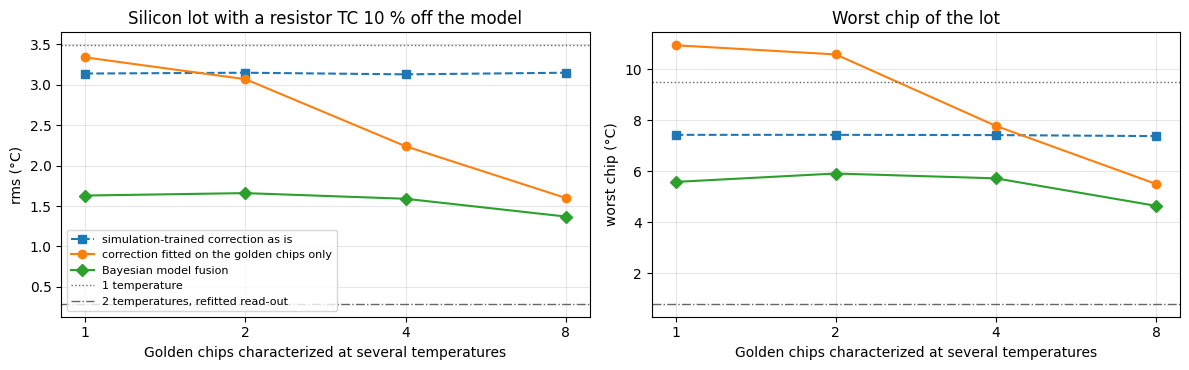

In [43]:
def lot_readout(raw):
    # the steps of 7.9 and 7.10 for any population: one-temperature read-out, two-temperature reference, and the
    # scaled calibration inputs (scaled with the statistics of the 24 simulated training chips)
    q = raw.assign(vdd_V=raw.vdd_V.round(2))
    d = q[q.vdd_V > 2].pivot_table(index=["chip", "temp_C", "vdd_V"], columns="ring", values="f_Hz").reset_index()
    d.columns.name = None
    d = d.rename(columns={"A": "f_A", "B": "f_B"})
    c = d[(d.temp_C == 25) & (d.vdd_V == 3.30)].set_index("chip")
    d["xA"] = np.log(d.f_A / d.chip.map(c.f_A))
    d["xB"] = np.log(d.f_B / d.chip.map(c.f_B))
    s25 = d[d.temp_C == 25].sort_values("vdd_V")
    va = s25.groupby("chip").xA.apply(lambda x: (x.iloc[-1] - x.iloc[0]) / 0.66)
    vb = s25.groupby("chip").xB.apply(lambda x: (x.iloc[-1] - x.iloc[0]) / 0.66)
    d["T_hat"] = basis_trim((d.xA - d.chip.map(va / vb) * d.xB).to_numpy(), d.xB.to_numpy()) @ coef_t
    d["e_1pt"] = d.T_hat - d.temp_C
    t_85 = d[d.temp_C == 85].set_index("chip").T_hat
    d["e_2pt"] = 25 + (d.T_hat - 25) * d.chip.map(60 / (t_85 - 25)) - d.temp_C
    d["T_2pt"] = d.e_2pt + d.temp_C
    d["e_2pt_fit"] = basis_2pt(d) @ coef_2pt - d.temp_C          # two-point read-out refitted on simulation (7.10)
    q25 = q[q.temp_C == 25]
    fl = q25[(q25.ring == "A") & (q25.vdd_V == A_LOW)].set_index("chip").f_Hz
    p = q25[q25.vdd_V == 3.30].pivot(index="chip", columns="ring", values="power_W")
    u_a = 100 * np.log(c.f_A / cal.loc["typical", "f_Hz_A"])
    x = pd.DataFrame({
        "u_A": u_a, "u_B": 100 * np.log(c.f_B / cal.loc["typical", "f_Hz_B"]),
        "dv_A": 100 * (va - v_A["typical"]), "dv_B": 100 * (vb - v_B["typical"]),
        "s_A": 100 * np.log(fl / f_low_typ) - u_a,
        "q_A": 100 * np.log(charge(p.A, c.f_A) / charge(cal.loc["typical", "power_W_A"], cal.loc["typical", "f_Hz_A"])),
        "q_B": 100 * np.log(charge(p.B, c.f_B) / charge(cal.loc["typical", "power_W_B"], cal.loc["typical", "f_Hz_B"]))})
    return d[d.temp_C != 85].copy(), (x - feat.loc[:N_TRAIN - 1].mean()) / feat.loc[:N_TRAIN - 1].std()


si, si_z = lot_readout(si_raw)
zf = pd.concat([zf, si_z])                         # design() of 7.10 reads the scaled inputs from zf
COLS = MODELS[list(MODELS)[1]]
LAM = learn_table.loc[f"   + learned correction: {list(MODELS)[1]}", "lambda"]
w_sim = ridge(train, COLS, LAM)                    # the correction of 7.10, trained on simulation only
sigma = np.std(train.e_1pt.to_numpy() - design(train, COLS) @ w_sim)
rng = np.random.default_rng(2027)
boot = [ridge(pd.concat([train[train.chip == k] for k in rng.choice(N_TRAIN, N_TRAIN)]), COLS, LAM)
        for _ in range(200)]
s_prior = np.std(boot, axis=0)
n_half = len(COLS) + 1
s_prior[[0, n_half]] = 5.0                          # intercepts a0, b0: broad prior (C per 100 C)


def fusion(gold, s=s_prior):
    # maximum a posteriori: Gaussian prior centred on w_sim with widths s, Gaussian residual sigma
    d = si[si.chip.isin(gold)]
    X = design(d, COLS)
    A = X.T @ X / sigma ** 2 + np.diag(1 / s ** 2)
    return np.linalg.solve(A, X.T @ d.e_1pt.to_numpy() / sigma ** 2 + w_sim / s ** 2)


def own_chips(gold):
    return ridge(si[si.chip.isin(gold)], COLS, LAM)


chips_si = sorted(si.chip.unique())
METHODS = {"simulation-trained correction as is": lambda gold: w_sim,
           "correction fitted on the golden chips only": own_chips,
           "Bayesian model fusion": fusion}
rows = []
for k in (1, 2, 4, 8):
    draws = [[c] for c in chips_si] if k == 1 else [list(rng.choice(chips_si, k, replace=False)) for _ in range(40)]
    for name, fit in METHODS.items():
        scores = []
        for gold in draws:
            d = si[~si.chip.isin(gold)].copy()
            d["e"] = d.e_1pt - design(d, COLS) @ fit(gold)
            scores.append(pop_stats(d, "e"))
        rows.append({"golden chips": k, "method": name, **pd.DataFrame(scores).mean().to_dict()})
bmf_table = pd.DataFrame(rows).set_index(["golden chips", "method"]).round(2)
ref_table = pd.DataFrame({"1 temperature + supply trim": pop_stats(si, "e_1pt"),
                          "2 temperatures + supply trim": pop_stats(si, "e_2pt"),
                          "2 temperatures, refitted read-out": pop_stats(si, "e_2pt_fit")}).T.round(2)
print(f"silicon lot ({len(chips_si)} chips, resistor TC {TC1_SILICON * 1e6:.0f} instead of {TC1_MODEL * 1e6:.0f} ppm/C), "
      f"no learned correction:")
for t in (ref_table, bmf_table):
    try:
        display(t)
    except NameError:
        print(t.to_string())



def one_chip_rms(s_int, scale):
    # rms over the lot after fusion with one golden chip, averaged over the 24 choices, for other prior widths
    s = np.std(boot, axis=0) * scale
    s[[0, n_half]] = s_int
    out = []
    for c in chips_si:
        d = si[si.chip != c]
        out.append(np.sqrt(np.mean((d.e_1pt - design(d, COLS) @ fusion([c], s)) ** 2)))
    return np.mean(out)


sens_table = pd.DataFrame({f"input priors x {sc:g}": {f"intercept prior {si_:g} C per 100 C": one_chip_rms(si_, sc)
                                                        for si_ in (2, 5, 10)} for sc in (0.3, 1, 3)}).round(2)
sens_table.columns.name = "rms (C), 1 golden chip"
try:
    display(sens_table)
except NameError:
    print(sens_table.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, col in zip(axes, ["rms (C)", "worst chip (C)"]):
    for name, mk in zip(METHODS, ["s--", "o-", "D-"]):
        v = bmf_table.xs(name, level="method")[col]
        ax.plot(v.index, v.to_numpy(), mk, label=name)
    for label, row, ls in (("1 temperature", "1 temperature + supply trim", ":"),
                           ("2 temperatures, refitted read-out", "2 temperatures, refitted read-out", "-.")):
        ax.axhline(ref_table.loc[row, col], color="0.4", ls=ls, lw=1, label=label)
    ax.set_xscale("log", base=2)
    ax.set_xticks([1, 2, 4, 8], ["1", "2", "4", "8"])
    ax.set_xlabel("Golden chips characterized at several temperatures")
    ax.set_ylabel(col.replace("(C)", "(°C)"))
    ax.grid(alpha=0.3)
axes[0].set_title("Silicon lot with a resistor TC 10 % off the model")
axes[1].set_title("Worst chip of the lot")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

**The model error appears as a bias.** On the silicon lot, the one-temperature read-out errs on average by up to 5.7 °C (rms 3.5 °C, worst chip 9.5 °C). The simulation-trained correction still removes most of the chip-to-chip spread (3σ from 9.6 to 5.0 °C), but not the bias: rms 3.1 °C, worst chip 7.4 °C.

**One golden chip removes most of it.** Fusion with a single golden chip brings the largest mean error to 2.2 °C, the worst chip to 5.6 °C and the rms error to 1.6 °C, close to the 1.3 °C the correction reaches in simulation. A correction fitted on golden chips alone is no better than the unadapted one with one or two chips, because it fits their mismatch, and needs eight to match fusion with one. The one-chip rms stays within 1.6 to 1.9 °C for other prior widths, unless the input priors are loose and the intercept prior tight (2.8 °C).

**For a production flow**, characterize one chip per lot, fuse, and calibrate the rest at one temperature: rms 1.6 °C here. Two temperatures on every chip still do much better (rms 0.3 °C, worst chip 0.8 °C), because they measure each chip's gain, including what the model gets wrong. The lot departs from the model in one known parameter, so the test shows the mechanism, not the size of a real gap.

## 8. Aging

Bias-temperature instability raises $|V_{TH}|$ over a chip's life; in this SiO₂-gate process, NBTI on the pMOS usually dominates. It is modelled with the `dvp` / `dvn` gate sources of section 4 from 0 to 50 mV, in two scenarios: **NBTI** (pMOS only) and **both** devices shifted equally. Only the inverter devices are aged: ring B's mirror pairs share their $V_{GS}$ and would age together, but a shift in its stack (MPD, MNB) would change $I_B$ and is not modelled.

### 8.1 Frequency shift versus ΔV<sub>TH</sub>

Typical corner, 25 °C, 3.3 V; 24 simulations.

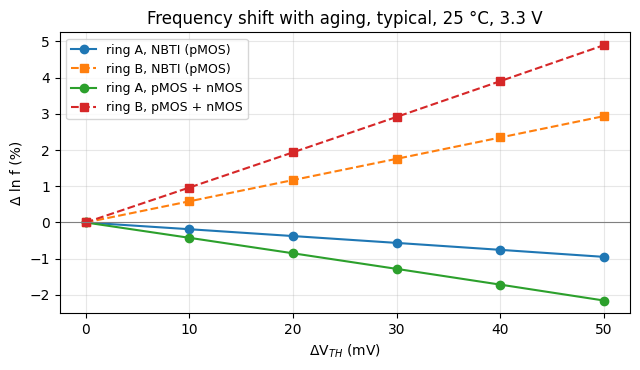

,ring A: %/10 mV,ring B: %/10 mV
scenario,,
NBTI (pMOS),-0.190,0.587
pMOS + nMOS,-0.431,0.980


In [44]:
# @title Aging sweep
AGE_MV = [0, 10, 20, 30, 40, 50]
SCENARIOS = {"NBTI (pMOS)": lambda dv: {"dvp": dv, "dvn": 0.0},
             "pMOS + nMOS": lambda dv: {"dvp": dv, "dvn": dv}}
RINGS = {"A": run_ro, "B": lambda **kw: run_csro(bias=B_BIAS, **kw)}


def age_point(job):
    scen, mv, ring = job
    r = RINGS[ring](temp=25, vdd=3.30, **SCENARIOS[scen](mv * 1e-3))
    return {"scenario": scen, "dVth_mV": mv, "ring": ring, "f_Hz": r["f"], "power_W": r["power"]}


age_jobs = [(s, mv, ring) for s in SCENARIOS for mv in AGE_MV for ring in RINGS]
with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
    aging = pd.DataFrame(list(ex.map(age_point, age_jobs)))
fresh = aging[aging.dVth_mV == 0].set_index(["scenario", "ring"]).f_Hz
aging["dlnf_pct"] = 100 * np.log(aging.f_Hz / [fresh[(s, r)] for s, r in zip(aging.scenario, aging.ring)])

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for (scen, ring), d in aging.groupby(["scenario", "ring"]):
    ax.plot(d.dVth_mV, d.dlnf_pct, "o-" if ring == "A" else "s--", label=f"ring {ring}, {scen}")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xlabel("ΔV$_{TH}$ (mV)")
ax.set_ylabel("Δ ln f (%)")
ax.set_title("Frequency shift with aging, typical, 25 °C, 3.3 V")
ax.grid(alpha=0.3)
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

age_slope = (aging.groupby(["scenario", "ring"])[["dVth_mV", "dlnf_pct"]]
             .apply(lambda d: 10 * np.polyfit(d.dVth_mV, d.dlnf_pct, 1)[0])
             .unstack("ring").round(3))
age_slope.columns = [f"ring {c}: %/10 mV" for c in age_slope.columns]
try:
    display(age_slope)
except NameError:
    print(age_slope.to_string())

### 8.2 Why ring B speeds up

Ring A slows down, as expected. Ring B speeds up: its current is set by the bias network, so the power stays the same, and a higher frequency at constant current means less charge per cycle. Load and swing do not change, so the saving must be short-circuit charge: higher thresholds shorten the time both devices of a stage conduct together. The cell checks the power and the charge per cycle, $Q = P/(V_{DD} f)$.

In [45]:
b_fresh = run_csro(bias=B_BIAS)
b_aged = run_csro(bias=B_BIAS, dvp=0.05)
mech = pd.DataFrame([{"ring B": name, "f (MHz)": r["f"] / 1e6, "P (uW)": r["power"] * 1e6,
                      "charge per cycle (pC)": r["power"] / (3.3 * r["f"]) * 1e12}
                     for name, r in (("fresh", b_fresh), ("NBTI, 50 mV", b_aged))]).set_index("ring B").round(4)
try:
    display(mech)
except NameError:
    print(mech.to_string())

,f (MHz),P (uW),charge per cycle (pC)
ring B,,,
fresh,46.9245,183.9898,1.1882
"NBTI, 50 mV",48.3218,184.0586,1.1542


### 8.3 What the temperature read-out sees

Two rings give two equations for three unknowns ($\Delta T$, $\Delta V_{DD}$, $\Delta V_{TH}$), so aging is read as some mix of temperature and supply. Mapping the aging vector through $S^{-1}$ (7.1) gives that mix per 10 mV; the second table checks it with the full read-out of 7.3 on a typical chip calibrated fresh and aged afterwards (NBTI, 25 and 50 mV, three temperatures; 18 simulations).

In [46]:
S_typ = np.array([[tA, vA], [sens_b[(B_BIAS, "typical")][1], sens_b[(B_BIAS, "typical")][2]]])
rows = []
for scen in SCENARIOS:
    a = age_slope.loc[scen].to_numpy() / 100          # d ln f per 10 mV, rings A and B
    dT_ab, dV_ab = np.linalg.solve(S_typ, a)
    rows.append({"scenario": scen, "A alone: apparent dT (C)": a[0] / tA,
                 "A + B: apparent dT (C)": dT_ab, "A + B: apparent dV_DD (mV)": 1e3 * dV_ab})
equiv = pd.DataFrame(rows).set_index("scenario").round(2)
equiv.columns.name = "per 10 mV of dV_TH"
try:
    display(equiv)
except NameError:
    print(equiv.to_string())

# full read-out on an aged typical chip, calibrated when fresh (coefficients coef_a, coef_t from 7.5)
k_typ = (v_A / v_B)["typical"]


def aged_readout(job):
    temp, mv = job
    fa = run_ro(temp=temp, vdd=3.30, dvp=mv * 1e-3)["f"]
    fb = run_csro(bias=B_BIAS, temp=temp, vdd=3.30, dvp=mv * 1e-3)["f"]
    xa = np.log(fa / cal.loc["typical", "f_Hz_A"])
    xb = np.log(fb / cal.loc["typical", "f_Hz_B"])
    t_a = (basis_a(np.array([xa])) @ coef_a)[0]
    t_ab = (basis_trim(np.array([xa - k_typ * xb]), np.array([xb])) @ coef_t)[0]
    return {"T (C)": temp, "NBTI dV_TH (mV)": mv, "A alone: error (C)": t_a - temp,
            "A + B + trim: error (C)": t_ab - temp}


with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
    aged = pd.DataFrame(list(ex.map(aged_readout, [(t, mv) for t in (-40, 25, 125) for mv in (0, 25, 50)])))
aged = aged.round(2)
try:
    display(aged)
except NameError:
    print(aged.to_string())

per 10 mV of dV_TH,A alone: apparent dT (C),A + B: apparent dT (C),A + B: apparent dV_DD (mV)
scenario,,,
NBTI (pMOS),1.00,3.12,17.99
pMOS + nMOS,2.28,5.63,28.53


,T (C),NBTI dV_TH (mV),A alone: error (C),A + B + trim: error (C)
0,-40,0,0.11,-0.23
1,-40,25,2.24,6.37
2,-40,50,4.44,13.25
3,25,0,-0.03,-0.01
4,25,25,2.47,7.98
5,25,50,5.05,16.37
6,125,0,-0.10,0.14
7,125,25,2.83,10.94
8,125,50,5.83,22.29


### 8.4 Interpretation

**The rings age in opposite directions.** Ring A's inverters set its current, so a higher $|V_{TH}|$ slows it (−0.19 %/10 mV with NBTI, −0.43 % with both devices). Ring B's bias network sets its current: the power stays at 184 µW while the charge per cycle falls 2.9 %, so it speeds up (+0.59 %/10 mV with NBTI, +0.98 % with both).

**Ring B trades supply robustness for aging sensitivity.** 10 mV of NBTI reads as +1.0 °C for ring A alone but +3.1 °C (and +18 mV of supply) for A + B. A + B still wins up to about 170 mV of NBTI, against ring A's ±41 °C from the supply, but aging dominates its error beyond about 15 mV.

**Aging needs a third observable.** A copy of ring A powered only during measurements would not age; its difference from the stressed copy would isolate $\Delta V_{TH}$, exactly the signal an aging-prediction model would learn from.

## 9. Layout and post-layout simulation

Both rings are laid out as code: Python writes a magic script that paints every rectangle on the GF180MCU grid with the schematic W/L; magic checks the design rules and extracts junction areas and wiring capacitance, netgen runs LVS, the PDK's KLayout deck runs sign-off DRC, and the extracted netlists replace the schematics in ngspice. A third cell lays out ring B with the 8/4 mirror of 7.8. Tools: magic 8.3.464, netgen 1.5.272, open_pdks `gf180mcuC` 1.0.471 and KLayout 0.28.17 (litex-hub conda packages, installed with micromamba).

In [47]:
# @title Layout tools: magic, netgen and the gf180mcuC technology files
MAMBA = os.path.join(WORK, "micromamba", "bin", "micromamba")
LENV = os.path.join(WORK, "layout_env")
LAYOUT_PKGS = ["litex-hub::magic=8.3.464_0_gcb73ebf", "litex-hub::netgen=1.5.272_0_g178af5f",
               "litex-hub::open_pdks.gf180mcuc=1.0.471_1_gd8bfd6f"]
if not os.path.exists(os.path.join(LENV, "bin", "netgen")):
    if not os.path.exists(MAMBA):
        sh("downloading micromamba 2.3.0", f"mkdir -p {WORK}/micromamba && cd {WORK}/micromamba && "
           "curl -sSL -o mm.tar.bz2 https://conda.anaconda.org/conda-forge/linux-64/micromamba-2.3.0-0.tar.bz2 && "
           "tar -xjf mm.tar.bz2 bin/micromamba")
    sh("installing magic, netgen and the gf180mcuC PDK files",
       f"MAMBA_ROOT_PREFIX={WORK}/mamba {MAMBA} create -y -q -p {LENV} -c litex-hub -c conda-forge "
       + " ".join(f'"{p}"' for p in LAYOUT_PKGS))
PDK_ROOT = os.path.join(LENV, "share", "pdk")
MAGICRC = os.path.join(PDK_ROOT, "gf180mcuC", "libs.tech", "magic", "gf180mcuC.magicrc")
NETGEN_SETUP = os.path.join(PDK_ROOT, "gf180mcuC", "libs.tech", "netgen", "gf180mcuC_setup.tcl")
LAYOUT = os.path.join(WORK, "layout")
os.makedirs(LAYOUT, exist_ok=True)
print(subprocess.run([os.path.join(LENV, "bin", "magic"), "--version"], capture_output=True, text=True).stdout.strip(),
      "| PDK files:", os.path.isfile(MAGICRC) and os.path.isfile(NETGEN_SETUP))

downloading micromamba 2.3.0 ...
installing magic, netgen and the gf180mcuC PDK files ...
8.3.464 | PDK files: True


### 9.1 Layout generators

**Ring A** (2.1 µm per stage): nMOS above the VSS rail and pMOS below the VDD rail share one vertical poly gate, fed through a poly contact between them; the drains join in a metal-1 strip that is the output and runs into the next stage's input. Taps sit under the rails, and the feedback runs in metal 2 below the VSS rail.

**Ring B** (5.6 µm per stage): the starving devices are turned sideways, so two horizontal poly lines, `nb` and `pb`, gate all 11 MNS and all 11 MPS. MNB and MPB sit as diodes at the start of those lines and MNM in a column of its own; MPD has its own n-well tied to `nd`, and the 70 µm resistor runs under the row.

**Ring B with the 8/4 mirror** (`ring_b_fix`): MNB and MNM no longer fit the L = 1 µm `nb` line, so they move to a block below MPD, two W = 8 µm devices under one L = 4 µm gate with their own tap and VSS rail, reached through metal 1 and metal 2.

In [48]:
# @title Layout generators and magic DRC
class Painter:
    # collects magic commands; coordinates in um
    def __init__(self):
        self.cmds = []

    def rect(self, layer, x1, y1, x2, y2):
        self.cmds.append(f"box {min(x1, x2):.3f}um {min(y1, y2):.3f}um {max(x1, x2):.3f}um {max(y1, y2):.3f}um\n"
                         f"paint {layer}")

    def label(self, text, x1, y1, x2, y2, port=None):
        self.cmds.append(f"box {x1:.3f}um {y1:.3f}um {x2:.3f}um {y2:.3f}um\nlabel {text} c metal1")
        if port is not None:
            self.cmds.append(f"port make {port}")

    def via(self, x, y):                                  # via1 with metal-1 and metal-2 landing pads
        self.rect("m1", x - 0.25, y - 0.25, x + 0.25, y + 0.25)
        self.rect("m2", x - 0.25, y - 0.25, x + 0.25, y + 0.25)
        self.rect("via1", x - 0.13, y - 0.13, x + 0.13, y + 0.13)


def inverter_core(p, x0, y_n, y_p, wn=1.0, wp=2.5):
    # nMOS (W = wn) from y_n, pMOS (W = wp) from y_p, L = 0.28, shared gate, input pad between them
    gap_top = y_n + wn
    p.rect("ndiff", x0 - 0.58, y_n, x0 + 0.58, y_n + wn)
    p.rect("pdiff", x0 - 0.58, y_p, x0 + 0.58, y_p + wp)
    p.rect("poly", x0 - 0.14, y_n - 0.22, x0 + 0.14, y_p + wp + 0.22)
    for x1 in (-0.515, 0.285):
        p.rect("ndc", x0 + x1, y_n + 0.065, x0 + x1 + 0.23, y_n + wn - 0.065)
        p.rect("pdc", x0 + x1, y_p + 0.065, x0 + x1 + 0.23, y_p + wp - 0.065)
    yi = gap_top + 0.42                                   # input poly pad and contact
    p.rect("poly", x0 - 0.565, yi, x0 - 0.14, yi + 0.36)
    p.rect("pc", x0 - 0.50, yi + 0.065, x0 - 0.27, yi + 0.295)
    p.rect("m1", x0 - 0.555, yi + 0.065, x0 - 0.215, yi + 0.295)
    p.rect("m1", x0 + 0.285, y_n + 0.01, x0 + 0.515, y_p + wp - 0.01)     # drains: output
    return yi + 0.065, yi + 0.295                         # y range of the input / output metal


def ring_a_layout(n=11, pitch=2.1):
    p, h = Painter(), pitch / 2
    for i in range(n):
        x0 = i * pitch
        p.rect("pwell", x0 - h, -0.40, x0 + h, 2.14)      # wells before diffusions
        p.rect("nwell", x0 - h, 2.47, x0 + h, 6.70)
        p.rect("psd", x0 - h, -0.20, x0 + h, 0.20)        # substrate tap under VSS
        p.rect("psc", x0 - 0.6, -0.115, x0 + 0.6, 0.115)
        p.rect("nsd", x0 - h + 0.15, 6.00, x0 + h - 0.15, 6.40)   # n-well tap under VDD
        p.rect("nsc", x0 - 0.6, 6.085, x0 + 0.6, 6.315)
        p.rect("m1", x0 - h, -0.30, x0 + h, 0.30)
        p.rect("m1", x0 - h, 5.90, x0 + h, 6.50)
        y1, y2 = inverter_core(p, x0, 0.80, 2.90)
        p.rect("m1", x0 - 0.515, 0.30, x0 - 0.285, 1.79)  # sources to the rails
        p.rect("m1", x0 - 0.515, 2.91, x0 - 0.285, 5.90)
        p.rect("m1", x0 - h, y1, x0 - 0.215, y2)          # input from the left edge
        if i < n - 1:
            p.rect("m1", x0 + 0.515, y1, x0 + h, y2)      # output to the next stage
        p.label(f"n{i}", x0 - 0.555, y1, x0 - 0.215, y2)
    xe, xs = (n - 1) * pitch + h + 0.8, -h - 0.8          # feedback in metal 2 below the VSS rail
    p.rect("m1", (n - 1) * pitch + 0.515, y1, xe + 0.25, y2)
    p.rect("m1", xs - 0.25, y1, -h, y2)
    for xv in (xe, xs):
        p.via(xv, (y1 + y2) / 2)
        p.rect("m2", xv - 0.20, -1.30, xv + 0.20, (y1 + y2) / 2)
    p.rect("m2", xs - 0.20, -1.30, xe + 0.20, -0.90)
    p.label("VDD", -h, 5.90, -h + 0.5, 6.50, port=1)
    p.label("VSS", -h, -0.30, -h + 0.5, 0.30, port=2)
    return p.cmds


def ring_b_layout(n=11, pitch=5.6, r_len=70.0, big_mirror=False):
    # big_mirror: MNB and MNM at 8/4 (section 7.8), in a block of their own below MPD
    p = Painter()
    xb1, xb2, xl = -2 * pitch, -pitch, (n - 1) * pitch    # bias columns, last stage
    x0r, x1r = xb1 - 3.2, xl + 3.2                        # row extent
    p.rect("pwell", x0r, -0.40, x1r, 4.84)
    p.rect("nwell", x0r, 5.17, x1r, 12.0)
    p.rect("psd", x0r, -0.20, x1r, 0.20)
    p.rect("nsd", x0r + 0.15, 11.30, x1r - 0.15, 11.70)
    for xc in [xb1, xb2] + [i * pitch for i in range(n)]:
        p.rect("psc", xc - 2.2, -0.115, xc + 2.2, 0.115)
        p.rect("nsc", xc - 2.2, 11.385, xc + 2.2, 11.615)
    p.rect("m1", x0r, -0.30, x1r, 0.30)                   # VSS
    p.rect("m1", x0r, 11.20, max(x1r + 3.7, r_len - 7.1), 11.80)   # VDD, extended at least to the resistor's via
    p.rect("poly", xb1 - 1.45, 1.40, x1r - 0.35, 2.40)    # nb: gates of MNB, MNM and the 11 MNS (L = 1)
    p.rect("poly", xb1 - 2.95, 9.30, x1r - 0.25, 10.30)   # pb: gates of MPB and the 11 MPS (L = 1)

    def nstarve(x0):                                      # W = 2 nMOS on the nb line, source to VSS
        p.rect("ndiff", x0 - 1.0, 0.80, x0 + 1.0, 3.00)
        p.rect("ndc", x0 - 0.935, 0.865, x0 + 0.935, 1.095)
        p.rect("ndc", x0 - 0.935, 2.705, x0 + 0.935, 2.935)
        p.rect("m1", x0 - 0.935, 0.30, x0 + 0.935, 1.15)
        p.rect("m1", x0 - 0.935, 2.65, x0 + 0.935, 2.99)  # drain bar

    def pstarve(x0):                                      # W = 5 pMOS on the pb line, source to VDD
        p.rect("pdiff", x0 - 2.5, 8.70, x0 + 2.5, 10.90)
        p.rect("pdc", x0 - 2.435, 8.765, x0 + 2.435, 8.995)
        p.rect("pdc", x0 - 2.435, 10.605, x0 + 2.435, 10.835)
        p.rect("m1", x0 - 2.435, 8.71, x0 + 2.435, 9.05)  # drain bar
        p.rect("m1", x0 - 2.435, 10.55, x0 + 2.435, 11.20)

    for i in range(n):
        x0 = i * pitch
        nstarve(x0)
        pstarve(x0)
        y1, y2 = inverter_core(p, x0, 3.50, 5.60)
        p.rect("m1", x0 - 0.515, 2.65, x0 - 0.285, 4.49) # MN source to the MNS drain
        p.rect("m1", x0 - 0.515, 5.61, x0 - 0.285, 8.71) # MP source to the MPS drain
        p.rect("m1", x0 - (2.0 if i == 0 else pitch / 2), y1, x0 - 0.215, y2)
        p.rect("m1", x0 + 0.515, y1, x0 + (2.0 if i == n - 1 else pitch / 2), y2)
        p.label(f"n{i}", x0 - 0.555, y1, x0 - 0.215, y2)
    for xv in (-2.25, xl + 2.25):                         # feedback in metal 2 below the VSS rail
        p.via(xv, (y1 + y2) / 2)
        p.rect("m2", xv - 0.2, -1.6, xv + 0.2, (y1 + y2) / 2)
    p.rect("m2", -2.45, -1.6, xl + 2.45, -1.2)
    # bias column 1: MNB (diode on nb) and MPB (diode on pb)
    if not big_mirror:
        nstarve(xb1)
        p.rect("m1", xb1 + 0.935, 2.65, xb1 + 1.67, 2.99)
    p.rect("m1", xb1 + 1.33, 1.05, xb1 + 1.67, 2.99 if not big_mirror else 2.15)
    p.rect("pc", xb1 + 1.385, 1.785, xb1 + 1.615, 2.015)
    p.via(xb1 + 1.5, 1.30)
    pstarve(xb1)
    p.rect("m1", xb1 + 2.435, 8.71, xb1 + 3.07, 9.05)
    p.rect("m1", xb1 + 2.73, 8.71, xb1 + 3.07, 9.97)
    p.rect("pc", xb1 + 2.785, 9.685, xb1 + 3.015, 9.915)
    p.label("nb", xb1 + 1.33, 2.2, xb1 + 1.67, 2.5)
    p.label("pb", xb1 + 2.73, 9.3, xb1 + 3.07, 9.6)
    # bias column 2: MNM (gate nb, drain to pb)
    if not big_mirror:
        nstarve(xb2)
        p.rect("m1", xb2 - 0.17, 2.65, xb2 + 0.17, 9.97)
    p.rect("pc", xb2 - 0.115, 9.685, xb2 + 0.115, 9.915)
    # below the row: MPD in its own n-well (body = source = nd), then R from nd to VDD
    xm = xb1 - 2.0
    p.rect("nwell", xm - 2.95, -9.00, xm + 3.40, -5.37)
    p.rect("nsd", xm - 2.4, -8.85, xm + 2.4, -8.45)
    p.rect("nsc", xm - 2.2, -8.765, xm + 2.2, -8.535)
    p.rect("pdiff", xm - 2.5, -8.00, xm + 2.5, -5.80)
    p.rect("pdc", xm - 2.435, -7.935, xm + 2.435, -7.705)
    p.rect("pdc", xm - 2.435, -6.095, xm + 2.435, -5.865)
    p.rect("poly", xm - 2.75, -7.40, xm + 3.10, -6.40)
    p.rect("pc", xm + 2.785, -7.015, xm + 3.015, -6.785)
    p.rect("m1", xm - 2.435, -8.82, xm + 2.435, -7.65)    # tap + source: nd
    xr = -8.0                                             # left end of the resistor
    p.rect("m1", xm + 2.435, -7.99, xr - 0.315, -7.65)
    p.rect("m1", xm - 2.435, -6.15, xb1 + 1.75, -5.81)    # drain bar: nb
    p.rect("m1", xm + 2.73, -7.07, xm + 3.07, -5.81)      # gate to drain
    p.via(xb1 + 1.5, -5.90)
    p.rect("m2", xb1 + 1.30, -5.90, xb1 + 1.70, 1.30)     # nb up to MNB
    p.rect("hires", xr, -4.5, xr + r_len, -3.5)           # R: r_len x 1 um of ppolyf_u_1k
    p.rect("poly", xr - 0.61, -4.5, xr, -3.5)
    p.rect("poly", xr + r_len, -4.5, xr + r_len + 0.61, -3.5)
    p.rect("pc", xr - 0.545, -4.435, xr - 0.315, -3.565)
    p.rect("pc", xr + r_len + 0.315, -4.435, xr + r_len + 0.545, -3.565)
    p.rect("m1", xr - 0.545, -7.99, xr - 0.315, -3.51)
    p.rect("m1", xr + r_len + 0.315, -4.49, xr + r_len + 0.545, -3.51)
    xv = xr + r_len + 0.43
    p.via(xv, -4.0)
    p.rect("m2", xv - 0.2, -4.0, xv + 0.2, 11.5)
    p.via(xv, 11.5)
    p.label("nd", xr - 0.545, -6.0, xr - 0.315, -5.5)
    if big_mirror:
        # MNM (x -15..-7) and MNB (x -5..3): W = 8 along x, one L = 4 poly gate (nb) shared by both, sources down to a
        # VSS rail with its own substrate tap, tied to the main VSS rail through metal 1 at the far left
        p.rect("pwell", -15.6, -17.3, 3.6, -10.0)
        p.rect("poly", -15.3, -15.2, 3.3, -11.2)
        for xa in (-15.0, -5.0):
            p.rect("ndiff", xa, -15.8, xa + 8.0, -10.6)
            p.rect("ndc", xa + 0.065, -15.735, xa + 7.935, -15.505)      # source row
            p.rect("ndc", xa + 0.065, -10.895, xa + 7.935, -10.665)      # drain row
            p.rect("m1", xa + 0.065, -16.5, xa + 7.935, -15.45)
            p.rect("m1", xa + 0.065, -10.95, xa + 7.935, -10.61)         # drain bar
        p.rect("psd", -15.4, -17.0, 3.4, -16.6)
        p.rect("psc", -15.2, -16.915, 3.2, -16.685)
        p.rect("m1", -17.0, -17.1, 3.4, -16.5)                          # block VSS rail
        p.rect("m1", -17.0, -17.1, -16.6, 0.30)                         # up to the main VSS rail
        p.rect("m1", -17.0, -0.30, x0r, 0.30)
        # gate contact between the two devices; MNB is a diode: gate to its drain (nb)
        p.rect("pc", -6.115, -13.315, -5.885, -13.085)
        p.rect("m1", -6.17, -13.37, -5.83, -9.50)
        p.rect("m1", -6.17, -10.95, -4.935, -10.61)
        # nb to MPD's drain bar: metal 1 below MPD, then metal 2 up to the existing nb via
        p.rect("m1", -9.95, -9.90, -5.83, -9.50)
        p.via(-9.70, -9.70)
        p.rect("m2", -9.90, -9.70, -9.50, -5.90)
        # MNM drain (pb) up to the pb line in metal 2, left of the feedback wire
        p.via(-7.40, -10.78)
        p.rect("m2", -7.60, -10.78, -7.20, 9.80)
        p.via(-7.40, 9.80)
        p.rect("m1", -7.65, 9.63, xb2 + 0.17, 9.97)
    p.label("VDD", x0r, 11.2, x0r + 0.5, 11.8, port=1)
    p.label("VSS", x0r, -0.3, x0r + 0.5, 0.3, port=2)
    return p.cmds


def run_magic(cell, cmds):
    # paints the cell, runs DRC, writes .mag / .gds and two netlists: devices only (LVS) and devices + capacitances
    with open(os.path.join(LAYOUT, f"{cell}_paint.tcl"), "w") as f:
        f.write("\n".join(cmds) + "\n")
    script = textwrap.dedent(f'''\
        cellname rename (UNNAMED) {cell}
        load {cell}
        source {cell}_paint.tcl
        select top cell
        drc style drc(full)
        drc check
        drc catchup
        puts "DRC_COUNT [drc list count total]"
        foreach {{why boxes}} [drc listall why] {{ puts "DRC_ERROR $why ([llength $boxes] boxes)" }}
        save {cell}
        gds write {cell}.gds
        extract all
        ext2spice lvs
        ext2spice -o {cell}_lvs.spice
        ext2spice cthresh 0
        ext2spice -o {cell}_pex.spice
        quit -noprompt
        ''')
    with open(os.path.join(LAYOUT, f"{cell}_flow.tcl"), "w") as f:
        f.write(script)
    env = dict(os.environ, PDK_ROOT=PDK_ROOT)
    p = subprocess.run([os.path.join(LENV, "bin", "magic"), "-dnull", "-noconsole", "-rcfile", MAGICRC,
                        f"{cell}_flow.tcl"], cwd=LAYOUT, capture_output=True, text=True, env=env, timeout=900)
    count = re.search(r"DRC_COUNT (\d+)", p.stdout)
    if count is None:
        print(p.stdout[-3000:], p.stderr[-2000:])
        raise RuntimeError(f"magic failed on {cell}")
    return int(count.group(1)), re.findall(r"DRC_ERROR (.*)", p.stdout)


CELLS = {"ring_a": ring_a_layout(), "ring_b": ring_b_layout(), "ring_b_fix": ring_b_layout(big_mirror=True)}
for cell, cmds in CELLS.items():
    n_err, errors = run_magic(cell, cmds)
    print(f"{cell}: {len(cmds)} shapes painted, DRC errors: {n_err}", *errors, sep="\n  ")

ring_a: 278 shapes painted, DRC errors: 0
ring_b: 392 shapes painted, DRC errors: 0
ring_b_fix: 413 shapes painted, DRC errors: 0


### 9.2 Layout versus schematic

The reference netlists below are written from the same topology as `ro_netlist` and `csro_netlist` (without the aging sources, which exist only in simulation). netgen matches devices, nets and W/L.

In [49]:
# @title LVS with netgen
def ring_a_schematic(n=11):
    s = [".subckt ring_a VDD VSS"]
    for i in range(n):
        a, y = f"n{i}", f"n{(i + 1) % n}"
        s += [f"XMN{i} {y} {a} VSS VSS nfet_03v3 w=1u l=0.28u", f"XMP{i} {y} {a} VDD VDD pfet_03v3 w=2.5u l=0.28u"]
    return "\n".join(s + [".ends", ""])


def ring_b_schematic(n=11, cell="ring_b", wmir=2.0, lmir=1.0, r_len=70.0):
    s = [f".subckt {cell} VDD VSS", f"XR VDD nd VSS ppolyf_u_1k r_length={r_len:g}u r_width=1u",
         "XMPD nb nb nd nd pfet_03v3 w=5u l=1u", f"XMNB nb nb VSS VSS nfet_03v3 w={wmir:g}u l={lmir:g}u",
         f"XMNM pb nb VSS VSS nfet_03v3 w={wmir:g}u l={lmir:g}u", "XMPB pb pb VDD VDD pfet_03v3 w=5u l=1u"]
    for i in range(n):
        a, y = f"n{i}", f"n{(i + 1) % n}"
        s += [f"XMPS{i} sp{i} pb VDD VDD pfet_03v3 w=5u l=1u", f"XMNS{i} sn{i} nb VSS VSS nfet_03v3 w=2u l=1u",
              f"XMN{i} {y} {a} sn{i} VSS nfet_03v3 w=1u l=0.28u", f"XMP{i} {y} {a} sp{i} VDD pfet_03v3 w=2.5u l=0.28u"]
    return "\n".join(s + [".ends", ""])


def mag_bbox(cell):
    # bounding box of the drawn shapes in um, from the .mag file (internal unit = 5 nm with magscale 1 10)
    text = open(os.path.join(LAYOUT, f"{cell}.mag")).read()
    scale = 0.05 * np.divide(*map(int, re.search(r"magscale (\d+) (\d+)", text).groups()))
    xy = np.array([list(map(int, r.split()[1:5])) for r in re.findall(r"^rect .*$", text, re.M)]) * scale
    return xy[:, [0, 2]].min(), xy[:, [1, 3]].min(), xy[:, [0, 2]].max(), xy[:, [1, 3]].max()


lvs_rows = []
for cell, schem in (("ring_a", ring_a_schematic()), ("ring_b", ring_b_schematic()),
                    ("ring_b_fix", ring_b_schematic(cell="ring_b_fix", wmir=FIX["wmir"], lmir=FIX["lmir"]))):
    with open(os.path.join(LAYOUT, f"{cell}_sch.spice"), "w") as f:
        f.write(schem)
    subprocess.run([os.path.join(LENV, "bin", "netgen"), "-batch", "lvs", f"{cell}_lvs.spice {cell}",
                    f"{cell}_sch.spice {cell}", NETGEN_SETUP, f"{cell}_lvs.out"],
                   cwd=LAYOUT, capture_output=True, text=True, env=dict(os.environ, PDK_ROOT=PDK_ROOT), timeout=900)
    report = open(os.path.join(LAYOUT, f"{cell}_lvs.out")).read()
    result = re.findall(r"Final result: (.*)", report)
    devices = re.findall(r"Number of devices: (\d+)", report)
    x1, y1, x2, y2 = mag_bbox(cell)
    lvs_rows.append({"cell": cell, "devices (layout | schematic)": " | ".join(devices[-2:]),
                     "LVS": result[-1] if result else "no result", "size (um)": f"{x2 - x1:.1f} x {y2 - y1:.1f}",
                     "area (um^2)": round((x2 - x1) * (y2 - y1))})
lvs_table = pd.DataFrame(lvs_rows).set_index("cell")
try:
    display(lvs_table)
except NameError:
    print(lvs_table.to_string())

,devices (layout | schematic),LVS,size (um),area (um^2)
cell,,,,
ring_a,22 | 22,Circuits match uniquely.,25.2 x 8.0,202
ring_b,49 | 49,Circuits match uniquely.,79.1 x 21.0,1660
ring_b_fix,49 | 49,Circuits match uniquely.,79.9 x 29.3,2341


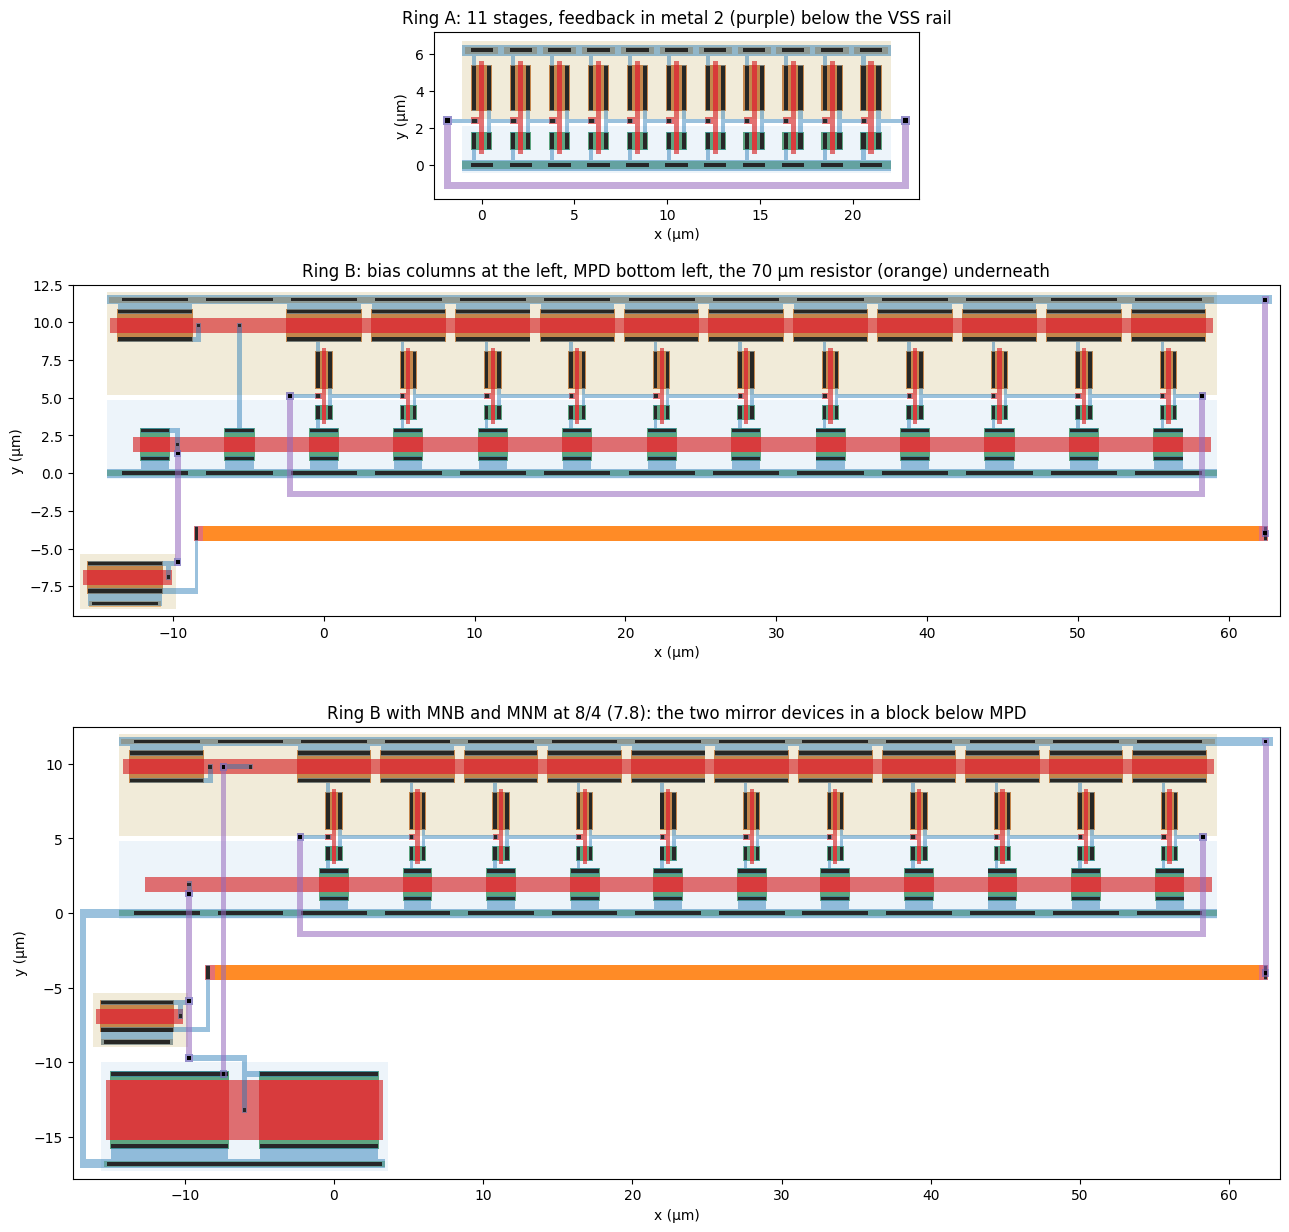

In [50]:
# @title Layout plots
from matplotlib.patches import Rectangle

LAYER_STYLE = {   # magic layer: (colour, alpha, z-order)
    "nwell": ("#c9b26b", 0.25, 0), "pwell": ("#9fc5e8", 0.18, 0),
    "ndiff": ("#2e8b57", 0.75, 1), "pdiff": ("#b5651d", 0.75, 1), "psubdiff": ("#6aa84f", 0.6, 1),
    "nsubdiff": ("#e69138", 0.6, 1), "nmos": ("#d62728", 0.9, 2), "pmos": ("#d62728", 0.9, 2),
    "polysilicon": ("#d62728", 0.65, 2), "nhighres": ("#ff7f0e", 0.9, 2),
    "ndiffc": ("#111111", 0.9, 4), "pdiffc": ("#111111", 0.9, 4), "psubdiffcont": ("#111111", 0.9, 4),
    "nsubdiffcont": ("#111111", 0.9, 4), "polycontact": ("#111111", 0.9, 4),
    "metal1": ("#1f77b4", 0.45, 3), "metal2": ("#9467bd", 0.55, 5), "via1": ("#000000", 1.0, 6)}


def draw_mag(cell, ax):
    text = open(os.path.join(LAYOUT, f"{cell}.mag")).read()
    scale = 0.05 * np.divide(*map(int, re.search(r"magscale (\d+) (\d+)", text).groups()))
    for layer, body in re.findall(r"<< (\w+) >>\n((?:rect .*\n)*)", text):
        if layer not in LAYER_STYLE:
            continue
        c, a, z = LAYER_STYLE[layer]
        for line in body.splitlines():
            x1, y1, x2, y2 = (int(v) * scale for v in line.split()[1:5])
            ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, color=c, alpha=a, lw=0, zorder=z))
    x1, y1, x2, y2 = mag_bbox(cell)
    ax.set_xlim(x1 - 0.5, x2 + 0.5)
    ax.set_ylim(y1 - 0.5, y2 + 0.5)
    ax.set_aspect("equal")
    ax.set_xlabel("x (µm)")
    ax.set_ylabel("y (µm)")


fig, axes = plt.subplots(3, 1, figsize=(13, 12.5), gridspec_kw={"height_ratios": [1, 2.2, 3.0]})
draw_mag("ring_a", axes[0])
axes[0].set_title("Ring A: 11 stages, feedback in metal 2 (purple) below the VSS rail")
draw_mag("ring_b", axes[1])
axes[1].set_title("Ring B: bias columns at the left, MPD bottom left, the 70 µm resistor (orange) underneath")
draw_mag("ring_b_fix", axes[2])
axes[2].set_title("Ring B with MNB and MNM at 8/4 (7.8): the two mirror devices in a block below MPD")
fig.tight_layout()
plt.show()

### 9.3 Sign-off DRC with KLayout

magic's rules are a fast interactive check. The PDK's sign-off deck (`libs.tech/klayout/drc` in open_pdks) needs KLayout with its Ruby engine, which the conda-forge builds lack and the litex-hub build of KLayout 0.28.17 has (with Ruby 2.5 from the anaconda channel). The deck runs with variant C, the `gf180mcuC` metal stack (5 metal layers, 9 kÅ top metal), once for the front- and back-end rules and once for the antenna rules; density rules apply to a full chip, not to a block.

In [51]:
# @title Sign-off DRC with KLayout
import glob

KENV = os.path.join(WORK, "klayout_env")
if not os.path.exists(os.path.join(KENV, "bin", "klayout")):
    sh("installing KLayout 0.28.17 with its Ruby interpreter",
       f"MAMBA_ROOT_PREFIX={WORK}/mamba {MAMBA} create -y -q -p {KENV} -c litex-hub -c anaconda -c conda-forge "
       "--override-channels klayout=0.28.17 ruby=2.5")
try:
    import docopt, klayout.db                             # used by the deck's runner script
except ImportError:
    sh("installing the Python packages of the DRC runner", f"{sys.executable} -m pip install -q docopt klayout")
KBIN = os.path.join(WORK, "klayout_bin")                  # only the klayout binary on PATH, not its Python
os.makedirs(KBIN, exist_ok=True)
if not os.path.exists(os.path.join(KBIN, "klayout")):
    os.symlink(os.path.join(KENV, "bin", "klayout"), os.path.join(KBIN, "klayout"))
DRC_DECK = os.path.join(PDK_ROOT, "gf180mcuC", "libs.tech", "klayout", "drc")
kenv = dict(os.environ, PATH=KBIN + os.pathsep + os.environ["PATH"], QT_QPA_PLATFORM="offscreen")


def klayout_drc(cell, extra, tag):
    run_dir = os.path.join(LAYOUT, f"klayout_{tag}_{cell}")
    shutil.rmtree(run_dir, ignore_errors=True)
    os.makedirs(run_dir)
    p = subprocess.run([sys.executable, os.path.join(DRC_DECK, "run_drc.py"), f"--path={cell}.gds", "--variant=C",
                        f"--topcell={cell}", f"--run_dir={run_dir}", f"--mp={os.cpu_count()}"] + extra,
                       cwd=LAYOUT, env=kenv, capture_output=True, text=True, timeout=1800)
    dbs = glob.glob(os.path.join(run_dir, "*.lyrdb"))
    if not dbs:
        print(p.stdout[-2000:], p.stderr[-2000:])
        raise RuntimeError(f"KLayout DRC produced no results for {cell}")
    return len(dbs), sum(open(f).read().count("<item>") for f in dbs)


signoff_rows = []
for cell in CELLS:
    n_tab, n_viol = klayout_drc(cell, [], "drc")
    _, n_ant = klayout_drc(cell, ["--antenna_only"], "antenna")
    signoff_rows.append({"cell": cell, "rule tables": n_tab, "DRC violations": n_viol, "antenna violations": n_ant})
signoff_table = pd.DataFrame(signoff_rows).set_index("cell")
print(subprocess.run([os.path.join(KBIN, "klayout"), "-b", "-v"], capture_output=True, text=True, env=kenv).stdout.strip(),
      "| GF180MCU sign-off deck, variant C")
try:
    display(signoff_table)
except NameError:
    print(signoff_table.to_string())

installing KLayout 0.28.17 with its Ruby interpreter ...
installing the Python packages of the DRC runner ...
KLayout 0.28.17 | GF180MCU sign-off deck, variant C


,rule tables,DRC violations,antenna violations
cell,,,
ring_a,53,0,0
ring_b,53,0,0
ring_b_fix,53,0,0


### 9.4 Post-layout simulation

The extracted netlists add the junction areas of every device and the wiring capacitance. Each ring is simulated at the 13 points of its sensitivities and of the read-out of 7.3 (26 simulations) and read with the schematic coefficients, after its own calibration and trim. The second cell repeats this for the 8/4 variant against its own schematic.

In [52]:
# @title Post-layout simulation
def post_netlist(cell, vdd=3.3, corner="typical", temp=27, t_stop=30e-9, t_step=2e-12, rise_a=10, rise_b=30):
    h = vdd / 2
    res = f'.lib "{GF180_MODELS}/sm141064.spice" {RES_CORNER[corner]}\n' if cell.startswith("ring_b") else ""
    return header(corner, temp) + res + textwrap.dedent(f'''\
        .include "{os.path.join(LAYOUT, cell + "_pex.spice")}"
        Vdd vdd 0 {vdd}
        X1 vdd 0 {cell}
        .ic v(x1.n0)=0 v(x1.n1)={vdd}
        .control
        tran {t_step} {t_stop} uic
        meas tran ta WHEN v(x1.n0)={h} RISE={rise_a}
        meas tran tb WHEN v(x1.n0)={h} RISE={rise_b}
        meas tran iavg AVG i(Vdd) FROM=ta TO=tb
        quit
        .endc
        .end
        ''')


POST_PTS = ([(t, v) for t in (-40, 25, 125) for v in VDDS] + [(0, 3.30), (50, 3.30), (25, 3.20), (25, 3.40)])


def post_point(job):
    ring, temp, vdd = job
    if ring == "A":
        r = run_ring(lambda **kw: post_netlist("ring_a", **kw), temp=temp, vdd=vdd, t_stop=60e-9, t_step=2e-12)
    else:
        r = run_ring(lambda **kw: post_netlist("ring_b", **kw), temp=temp, vdd=vdd, t_stop=1.2e-6, t_step=50e-12)
    return {"ring": ring, "temp_C": temp, "vdd_V": vdd, "f_Hz": r["f"], "power_W": r["power"]}


with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
    post = pd.DataFrame(list(ex.map(post_point, [(ring, t, v) for ring in ("A", "B") for t, v in POST_PTS])))


def post_sens(ring):
    d = post[post.ring == ring].set_index(["temp_C", "vdd_V"])
    f0 = d.f_Hz[(25, 3.30)]
    return (f0, d.power_W[(25, 3.30)], (d.f_Hz[(50, 3.30)] - d.f_Hz[(0, 3.30)]) / 50 / f0,
            (d.f_Hz[(25, 3.40)] - d.f_Hz[(25, 3.20)]) / 0.2 / f0)


sch_power = {r: pvt_[(pvt_.corner == "typical") & (pvt_.temp_C == 25) & np.isclose(pvt_.vdd_V, 3.30)].power_W.iloc[0]
             for r, pvt_ in (("A", pvt), ("B", pvt_b))}
rows = []
for ring, (f_s, tc_s, sv_s) in (("A", (fA, tA, vA)), ("B", sens_b[(B_BIAS, "typical")])):
    f_l, p_l, tc_l, sv_l = post_sens(ring)
    rows += [{"ring": ring, "netlist": "schematic", "f at 25 C (MHz)": f_s / 1e6, "P (uW)": 1e6 * sch_power[ring],
              "TC (%/C)": 100 * tc_s, "S_V (%/V)": 100 * sv_s},
             {"ring": ring, "netlist": "layout (extracted)", "f at 25 C (MHz)": f_l / 1e6, "P (uW)": 1e6 * p_l,
              "TC (%/C)": 100 * tc_l, "S_V (%/V)": 100 * sv_l}]
post_table = pd.DataFrame(rows).set_index(["ring", "netlist"]).round(3)
try:
    display(post_table)
except NameError:
    print(post_table.to_string())

# read-out of 7.3 on the post-layout rings: own calibration and supply trim, schematic coefficients
pl = (post.assign(vdd_V=post.vdd_V.round(2)).pivot_table(index=["temp_C", "vdd_V"], columns="ring", values="f_Hz")
      .reset_index())
pl = pl[pl.temp_C.isin(MC_TEMPS) & pl.vdd_V.isin(VDDS)].copy()
c25 = pl[(pl.temp_C == 25) & np.isclose(pl.vdd_V, 3.30)].iloc[0]
pl["xA"], pl["xB"] = np.log(pl.A / c25.A), np.log(pl.B / c25.B)
s25 = pl[pl.temp_C == 25].sort_values("vdd_V")
k_pl = (s25.xA.iloc[-1] - s25.xA.iloc[0]) / (s25.xB.iloc[-1] - s25.xB.iloc[0])
pl["eT_A"] = basis_a(pl.xA.to_numpy()) @ coef_a - pl.temp_C
pl["eT_trim"] = basis_trim((pl.xA - k_pl * pl.xB).to_numpy(), pl.xB.to_numpy()) @ coef_t - pl.temp_C
sch_pts = ref.assign(vdd_V=ref.vdd_V.round(2)).set_index(["temp_C", "vdd_V"])
readout_post = pd.DataFrame({
    "A alone, 3.3 V: schematic (C)": sch_pts.eT_A[sch_pts.index.get_level_values(1) == 3.30].abs().max(),
    "A alone, 3.3 V: layout (C)": pl.eT_A[np.isclose(pl.vdd_V, 3.30)].abs().max(),
    "A + B + trim: schematic (C)": sch_pts.eT_trim.abs().max(),
    "A + B + trim: layout (C)": pl.eT_trim.abs().max()}, index=["max |error|, -40 / 25 / 125 C"]).round(2)
try:
    display(readout_post)
except NameError:
    print(readout_post.to_string())

f at 25 C (MHz)    P (uW)  TC (%/C)  S_V (%/V)
ring netlist                                                           
A    schematic                  1200.854  1226.873    -0.189     22.248
     layout (extracted)          851.632  1236.702    -0.189     23.362
B    schematic                    46.857   183.562     0.071     20.244
     layout (extracted)           34.400   192.549     0.067     18.147

,"A alone, 3.3 V: schematic (C)","A alone, 3.3 V: layout (C)",A + B + trim: schematic (C),A + B + trim: layout (C)
"max |error|, -40 / 25 / 125 C",0.11,1.07,0.84,2.98


In [53]:
# @title Post-layout check of the 8/4 mirror
# ring B with the 8/4 mirror (7.8): extracted netlist and schematic at the same sensitivity points, then the read-out
# with the variant's schematic coefficients (coef_fix) on the extracted rings A and B
def fix_pair_point(job):
    netlist, temp, vdd = job
    if netlist == "layout":
        r = run_ring(lambda **kw: post_netlist("ring_b_fix", **kw), temp=temp, vdd=vdd, t_stop=1.2e-6, t_step=50e-12)
    else:
        r = run_csro(bias=B_BIAS, temp=temp, vdd=vdd, t_stop=0.9e-6, **FIX)
    return {"netlist": netlist, "temp_C": temp, "vdd_V": vdd, "f_Hz": r["f"], "power_W": r["power"]}


fp_jobs = ([("layout", t, v) for t, v in POST_PTS]
           + [("schematic", t, v) for t, v in ((25, 3.30), (0, 3.30), (50, 3.30), (25, 3.20), (25, 3.40))])
with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
    fpair = pd.DataFrame(list(ex.map(fix_pair_point, fp_jobs)))
fpair["vdd_V"] = fpair.vdd_V.round(2)
rows = []
for netlist in ("schematic", "layout"):
    d = fpair[fpair.netlist == netlist].set_index(["temp_C", "vdd_V"])
    f0 = d.f_Hz[(25, 3.30)]
    rows.append({"ring": "B, MNB and MNM 8/4", "netlist": netlist if netlist == "schematic" else "layout (extracted)",
                 "f at 25 C (MHz)": f0 / 1e6, "P (uW)": 1e6 * d.power_W[(25, 3.30)],
                 "TC (%/C)": 100 * (d.f_Hz[(50, 3.30)] - d.f_Hz[(0, 3.30)]) / 50 / f0,
                 "S_V (%/V)": 100 * (d.f_Hz[(25, 3.40)] - d.f_Hz[(25, 3.20)]) / 0.2 / f0})
post_fix_table = pd.DataFrame(rows).set_index(["ring", "netlist"]).round(3)

plf = (post[post.ring == "A"].assign(vdd_V=post[post.ring == "A"].vdd_V.round(2))[["temp_C", "vdd_V", "f_Hz"]]
       .merge(fpair[fpair.netlist == "layout"][["temp_C", "vdd_V", "f_Hz"]], on=["temp_C", "vdd_V"],
              suffixes=("_A", "_B")))
plf = plf[plf.temp_C.isin(MC_TEMPS) & plf.vdd_V.isin(VDDS)].copy()
c25f = plf[(plf.temp_C == 25) & (plf.vdd_V == 3.30)].iloc[0]
plf["xA"], plf["xB"] = np.log(plf.f_Hz_A / c25f.f_Hz_A), np.log(plf.f_Hz_B / c25f.f_Hz_B)
s25f = plf[plf.temp_C == 25].sort_values("vdd_V")
k_plf = (s25f.xA.iloc[-1] - s25f.xA.iloc[0]) / (s25f.xB.iloc[-1] - s25f.xB.iloc[0])
plf["eT"] = basis_trim((plf.xA - k_plf * plf.xB).to_numpy(), plf.xB.to_numpy()) @ coef_fix - plf.temp_C
fix_typ = mfx[(mfx.corner == "typical") & mfx.temp_C.isin(MC_TEMPS)]
post_fix_table.loc[("B, MNB and MNM 8/4", "schematic"), "A + B + trim: max |error| (C)"] = fix_typ.eT_fix.abs().max()
post_fix_table.loc[("B, MNB and MNM 8/4", "layout (extracted)"), "A + B + trim: max |error| (C)"] = plf.eT.abs().max()
try:
    display(post_fix_table.round(3))
except NameError:
    print(post_fix_table.round(3).to_string())

f at 25 C (MHz)   P (uW)  TC (%/C)  \
ring               netlist                                                  
B, MNB and MNM 8/4 schematic                    44.462  179.974     0.121   
                   layout (extracted)           32.659  188.955     0.115   

                                       S_V (%/V)  \
ring               netlist                         
B, MNB and MNM 8/4 schematic              21.479   
                   layout (extracted)     19.187   

                                       A + B + trim: max |error| (C)  
ring               netlist                                            
B, MNB and MNM 8/4 schematic                                   1.118  
                   layout (extracted)                          4.555

**Across the corners.** In a real flow the read-out is fitted on extracted netlists. The cell below simulates both extracted rings on the full grid (5 corners, 7 temperatures, 3 supplies: 210 simulations, cached) and compares the schematic read-out of 7.3 with the extracted rings read with the schematic coefficients and with coefficients refitted on their own typical corner.  About 35 min in Colab.

In [54]:
# @title Extracted netlists across the corners (210 simulations, about 35 min in Colab)
CSV_POST = os.path.join(WORK, "post_layout_grid.csv")
pg_jobs = [(ring, c, t, v) for ring in ("A", "B") for c in CORNERS for t in TEMPS for v in VDDS]


def pg_point(job):
    ring, corner, temp, vdd = job
    cell, win = (("ring_a", {"t_stop": 60e-9, "t_step": 2e-12}) if ring == "A"
                 else ("ring_b", {"t_stop": 1.2e-6, "t_step": 50e-12}))
    r = run_ring(lambda **kw: post_netlist(cell, **kw), corner=corner, temp=temp, vdd=vdd, **win)
    return {"ring": ring, "corner": corner, "temp_C": temp, "vdd_V": vdd, "f_Hz": r["f"]}


pg = pd.read_csv(CSV_POST) if (os.path.exists(CSV_POST) and not RERUN) else None
if pg is not None and len(pg) == len(pg_jobs):
    print(f"loaded {len(pg)} simulations from {CSV_POST}")
else:
    t0, rows = time.time(), []
    with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
        for i, row in enumerate(ex.map(pg_point, pg_jobs), 1):
            rows.append(row)
            if i % 42 == 0 or i == len(pg_jobs):
                print(f"{i}/{len(pg_jobs)} simulations ({time.time() - t0:.0f} s)", flush=True)
    pg = pd.DataFrame(rows)
    pg.to_csv(CSV_POST, index=False)
    print("saved", CSV_POST)

mp = (pg.assign(vdd_V=pg.vdd_V.round(2)).pivot_table(index=["corner", "temp_C", "vdd_V"], columns="ring",
                                                      values="f_Hz").reset_index())
cal_p = mp[(mp.temp_C == 25) & (mp.vdd_V == 3.30)].set_index("corner")
mp["xA"] = np.log(mp.A / mp.corner.map(cal_p.A))
mp["xB"] = np.log(mp.B / mp.corner.map(cal_p.B))
d25p = mp[mp.temp_C == 25].sort_values("vdd_V")
vA_p = d25p.groupby("corner").xA.apply(lambda x: (x.iloc[-1] - x.iloc[0]) / 0.66)
vB_p = d25p.groupby("corner").xB.apply(lambda x: (x.iloc[-1] - x.iloc[0]) / 0.66)
mp["z"] = mp.xA - mp.corner.map(vA_p / vB_p) * mp.xB
typ_p, nom_p = mp.corner == "typical", mp.vdd_V == 3.30
coef_t_post = np.linalg.lstsq(basis_trim(mp.z[typ_p].to_numpy(), mp.xB[typ_p].to_numpy()),
                              mp.temp_C[typ_p].to_numpy(), rcond=None)[0]
coef_a_post = np.linalg.lstsq(basis_a(mp.xA[typ_p & nom_p].to_numpy()), mp.temp_C[typ_p & nom_p].to_numpy(),
                              rcond=None)[0]
mp["e_sch_coef"] = basis_trim(mp.z.to_numpy(), mp.xB.to_numpy()) @ coef_t - mp.temp_C
mp["e_refit"] = basis_trim(mp.z.to_numpy(), mp.xB.to_numpy()) @ coef_t_post - mp.temp_C
mp["eA_refit"] = basis_a(mp.xA.to_numpy()) @ coef_a_post - mp.temp_C
post_corner_table = pd.DataFrame({
    "A alone, 3.3 V: layout, refitted (C)": mp[nom_p].groupby("corner").eA_refit.apply(lambda e: e.abs().max()),
    "A + B + trim: schematic, 7.3 (C)": readout["3) A + B + supply trim (C)"],
    "A + B + trim: layout, schematic coefficients (C)": mp.groupby("corner").e_sch_coef.apply(lambda e: e.abs().max()),
    "A + B + trim: layout, refitted (C)": mp.groupby("corner").e_refit.apply(lambda e: e.abs().max())}
).reindex(CORNERS).round(2)
try:
    display(post_corner_table)
except NameError:
    print(post_corner_table.to_string())

42/210 simulations (307 s)
84/210 simulations (638 s)
126/210 simulations (1012 s)
168/210 simulations (1531 s)
210/210 simulations (1974 s)
saved /content/gf180_work/post_layout_grid.csv


,"A alone, 3.3 V: layout, refitted (C)","A + B + trim: schematic, 7.3 (C)","A + B + trim: layout, schematic coefficients (C)","A + B + trim: layout, refitted (C)"
corner,,,,
typical,0.25,0.84,2.98,0.85
ff,1.54,4.90,3.71,5.09
ss,0.45,2.00,3.36,1.19
fs,1.59,1.33,3.06,2.17
sf,0.61,1.10,2.43,1.02


### 9.5 Interpretation

**The layouts are clean.** All three cells pass magic DRC, LVS (22, 49 and 49 devices) and the KLayout sign-off deck, with no violation in its 53 rule tables nor in the antenna rules. Ring A takes 25 × 8 µm and ring B 79 × 21 µm, mostly the resistor and the 5 µm-wide pMOS starving devices: about 0.0019 mm² for the pair. The 8/4 mirror grows ring B to 80 × 29 µm; its devices add only about 60 µm², the rest is empty space below the row that a tighter placement would recover.

**Parasitics slow both rings by a common factor.** The extracted rings run 29 % (A) and 27 % (B) slower, mostly from the junction capacitance the schematics omit. A common factor is what the ratio calibration removes: ring A's TC does not move (−0.189 %/°C).

**Ring B changes shape, and a refit restores the corners.** Its TC falls 7 % and its $S_V$ 10 %, so the read-out with schematic coefficients errs by up to 3.0 °C (0.8 °C on the schematic), and by 2.4 to 3.7 °C at every corner. Refitted on the extracted typical corner, it returns to the schematic results: 0.9 °C typical, 1.0 to 2.2 °C in ss, fs and sf, and 5.1 °C in ff; ring A alone stays within 1.6 °C. The 8/4 variant follows the same pattern (27 % slower, TC −5 %, $S_V$ −11 %, 4.6 °C with schematic coefficients). The layout changes which coefficients the read-out needs, not how well it works.

## 10. Comparison with published work

| Work | Technology | Principle | Data | Range (°C) | Calibration | Inaccuracy | Supply sensitivity | Power / energy |
|---|---|---|---|---|---|---|---|---|
| This work | GF180MCU 180 nm, 3.3 V | Two 11-stage rings (plain and resistor-biased current-starved), frequency ratios | Schematic simulation (5 corners, 16-chip mismatch and 48-chip process + mismatch Monte Carlo); layout clean under sign-off DRC and LVS, extracted netlists across the 5 corners | −40 to 125 | 1 temperature (25 °C) + 2 extra supply points; optionally 3 more measurements at 25 °C (7.10) or a 2nd temperature | Corners: ≤ 4.9 °C (ff), ≤ 2 °C in the other four, over ±10 % supply. Process + mismatch, 24 unseen chips (3σ): ±10.0 °C with 1 temperature, ±5.3 °C with the learned correction, ±0.7 °C with 2 temperatures and a refitted read-out | ≤ 3.5 °C/V (A + B); 126–166 °C/V for ring A alone (worst over temperature, cell below) | 1.4 mW continuous (A: 1.22 mW at 1.2 GHz, B: 0.18 mW); about 21 nJ per conversion at 0.1 °C quantization, rings only (10.1); 0.0019 mm² (layout) |
| [Anand 2016] | 65 nm, 1.0 V | Two rings with different $L$ ($\Delta V_{TH}$ from reverse short-channel effect), frequency ratio | Measured | 0 to 100 | 1 point / 2 points | ±3.3 °C / ±0.9 °C (2nd-order correction) | 34 °C/V (0.034 °C/mV) | 154 µW; ≈1 pJ/conversion at 1 °C quantization; 0.004 mm² |
| [Yang 2017] | 180 nm, 1.2 V | Subthreshold ring, exponential temperature dependence | Measured | −20 to 80 (fully integrated, RC reference) | 2 points + one universal correction | ±0.76 °C (3σ, 5 chips) | 0.36 °C/V | 4.56 nJ/conversion (0.6 nJ sensing core); 8865 µm² |
| [Chen 2010] | 65 nm, 0.3 to 1 V | Weak-inversion current into a ring for T, a ZTC ring for process, voltage-to-time for supply | Simulation | −50 to 125 | Not described | ±0.8 °C over 0.3 to 1 V supply | Not reported | 3.7 µW at 0.3 V, 10 kS/s |

- **The inaccuracy figures are not directly comparable:** this work reports worst-case corners and Monte Carlo spreads in simulation; [Anand 2016] and [Yang 2017] are measured on a few chips; [Chen 2010] is simulated.
- **Per 1 % of supply**, the error is about 0.11 °C here (3.3 °C/V × 33 mV), 0.34 °C for [Anand 2016] and 0.004 °C for [Yang 2017], whose ring runs behind a supply-regulating native NMOS header.
- [Anand 2016] makes two rings differ through $V_{TH}$ and digitizes their ratio; this work makes them differ through what sets their current, which gives opposite TCs, and uses per-chip supply slopes instead of a plain ratio. [Kim 2007] compares a stressed and an unstressed ring, the third-observable idea of 8.4.

In [55]:
# residual supply sensitivity of each read-out: change of the temperature reading between 2.97 V and 3.63 V,
# per volt, at every corner and temperature (no new simulations: uses the read-out of section 7.3)
def per_volt(err_col):
    d = m.assign(reading=m[err_col] + m.temp_C).sort_values("vdd_V")
    return d.groupby(["corner", "temp_C"]).reading.apply(lambda r: (r.iloc[-1] - r.iloc[0]) / 0.66).abs()


supply_sens = pd.DataFrame({"ring A alone (C/V)": per_volt("eT_A").groupby("corner").max(),
                            "A + B + supply trim (C/V)": per_volt("eT_trim").groupby("corner").max()})
supply_sens = supply_sens.reindex(CORNERS).round(2)
supply_sens.index.name = "worst over temperature"
try:
    display(supply_sens)
except NameError:
    print(supply_sens.to_string())

,ring A alone (C/V),A + B + supply trim (C/V)
worst over temperature,,
typical,146.75,2.00
ff,125.79,1.53
ss,166.33,3.31
fs,149.98,2.05
sf,144.01,1.84


### 10.1 Interpretation

**Supply rejection by computation, not regulation.** Per 1 % of supply this work moves 0.11 °C, three times better than [Anand 2016] and far from [Yang 2017], whose header keeps supply changes from reaching the ring at a cost in headroom, power and area. Here ring B estimates $V_{DD}$ and the read-out subtracts its effect, which is also why ring B's aging degrades the rejection.

**Inaccuracy follows the number of calibration temperatures.** With one point, [Anand 2016] reaches ±3.3 °C, while the unseen chips of this population spread ±10.0 °C (±5.3 °C with the learned correction). With two, [Anand 2016] reaches ±0.9 °C, [Yang 2017] ±0.76 °C and those chips ±0.7 °C, in simulation with ±0.3 °C numerical precision. The one-temperature spread is the rings' chip-to-chip TC, exactly what a second temperature measures.

**Power and energy per conversion.** Ring A spends 1.02 pJ per cycle at 1.2 GHz (1.22 mW), ring B 3.9 pJ at 47 MHz (0.18 mW). A counter quantizes $\ln f$ to $1/N$ for $N$ counted cycles, and the read-out weights ring B by $v_A/v_B \approx 1.07$, so one count of each ring is worth $\Delta T$ when $N_A = 1/(|TC_z|\,\Delta T)$ and $N_B = 1.07\,N_A$, with $|TC_z| = 0.25$ %/°C (7.9). If each ring runs only for its own count, $\Delta T = 0.1$ °C takes 4,000 cycles of ring A (3.3 µs, 4.0 nJ) and 4,200 of ring B (90 µs, 16.6 nJ): about 21 nJ per conversion, 2.1 nJ at 1 °C, and about 40 % more with the extracted netlists, whose rings are slower at almost the same power. Ring A alone needs 5.6 nJ at 0.1 °C. The counter and its reference clock are not included. This is of the order of [Yang 2017] and far above [Anand 2016]; ring B sets both the conversion time and most of the energy (16.6 of 21 nJ), so lowering its energy per cycle is the first lever. Duty cycling sets the average power (one 0.1 °C conversion every 10 ms is about 2 µW) and also reduces aging stress.

## 11. Limitations

- **Statistics.** 16 chips for mismatch and 48 for process + mismatch: the 3σ figures carry about ±15 to ±20 % uncertainty. The corrections of 7.6 and 7.10 learn the PDK's statistical description, not silicon; 7.11 emulates a model gap with one parameter, so it shows the mechanism of the fusion, not the size of a real gap. The correction of 7.10 is linear and needs per-ring supply currents. The 8/4 mirror is checked across the corners and in layout, not in the population.
- **Corners.** Resistor corners follow the MOS corner; mixed combinations such as ss MOS with `res_ff` appear only at random, in the population of 7.9.
- **Layout.** magic DRC, KLayout sign-off DRC (with antenna rules) and LVS pass; density rules apply to a full chip and are not run. Extraction gives capacitance but no wire resistance, once from the drawn geometry; the Monte Carlo runs and the aging study use the schematic netlists. The 8/4 block is placed for simplicity, not area. There is no pad frame or output buffer.
- **Aging.** Only the inverter devices age; DC stress on ring B's stack and mirror, and BTI recovery, are not modelled.
- **Numerics.** With a 2 ps step the frequency converges to a few hundred ppm, about ±0.3 °C (11.1); runs on different machines differ by up to 0.2 °C, so errors are given with one decimal.
- **Read-out circuit.** The counter and its reference clock are not modelled; 10.1 estimates the conversion time and energy from the rings alone.

### 11.1 Numerical accuracy

Three ring-A points simulated with the default 2 ps step and with a 0.5 ps step; the frequency change is converted to a temperature with TC ≈ 0.18 %/°C.

In [56]:
acc_pts = [("typical", 25, 3.30), ("ss", -40, 2.97), ("typical", 125, 2.97)]


def accuracy(p):
    corner, temp, vdd = p
    f_default = run_ro(corner=corner, temp=temp, vdd=vdd)["f"]
    f_fine = run_ro(corner=corner, temp=temp, vdd=vdd, t_step=0.5e-12)["f"]
    ppm = (f_fine / f_default - 1) * 1e6
    return {"corner": corner, "temp_C": temp, "vdd_V": vdd, "f default (GHz)": f_default / 1e9,
            "change with 0.5 ps (ppm)": ppm, "equivalent (C)": abs(ppm) * 1e-6 / 0.0018}


with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
    acc = pd.DataFrame(list(ex.map(accuracy, acc_pts))).round(3)
try:
    display(acc)
except NameError:
    print(acc.to_string())

,corner,temp_C,vdd_V,f default (GHz),change with 0.5 ps (ppm),equivalent (C)
0,typical,25,3.30,1.201,238.306,0.132
1,ss,-40,2.97,1.024,177.964,0.099
2,typical,125,2.97,0.933,561.704,0.312


## 12. Error budget

Every error source quantified in this notebook, for ring A alone and for the two-ring read-out with the supply trim, in °C over −40 to 125 °C: worst case for the systematic sources, 3σ for mismatch, and per 10 mV of $\Delta V_{TH}$ for aging. No new simulations.

,kind,ring A alone (C),A + B + supply trim (C)
source,,,
Process corners with a ±10 % supply (worst corner),systematic,62.92,4.90
"Mismatch, 16 chips (3σ)",random,0.33,8.02
Mismatch with the calibration-frequency correction (7.6),random,NaN,2.36
"Mismatch with MNB, MNM at 8/4 (7.8)",random,NaN,2.40
"Process + mismatch, 1 temperature (3σ, 7.9)",random,NaN,9.41
"Process + mismatch, learned correction, test chips (7.10)",random,NaN,5.31
"Process + mismatch, 2 temperatures, refitted read-out (3σ, 7.9)",random,NaN,0.59
"Model-to-silicon gap: correction trained on simulation (largest mean error, 7.11)",systematic,NaN,5.79
Model-to-silicon gap: after fusion with 1 golden chip (7.11),systematic,NaN,2.24


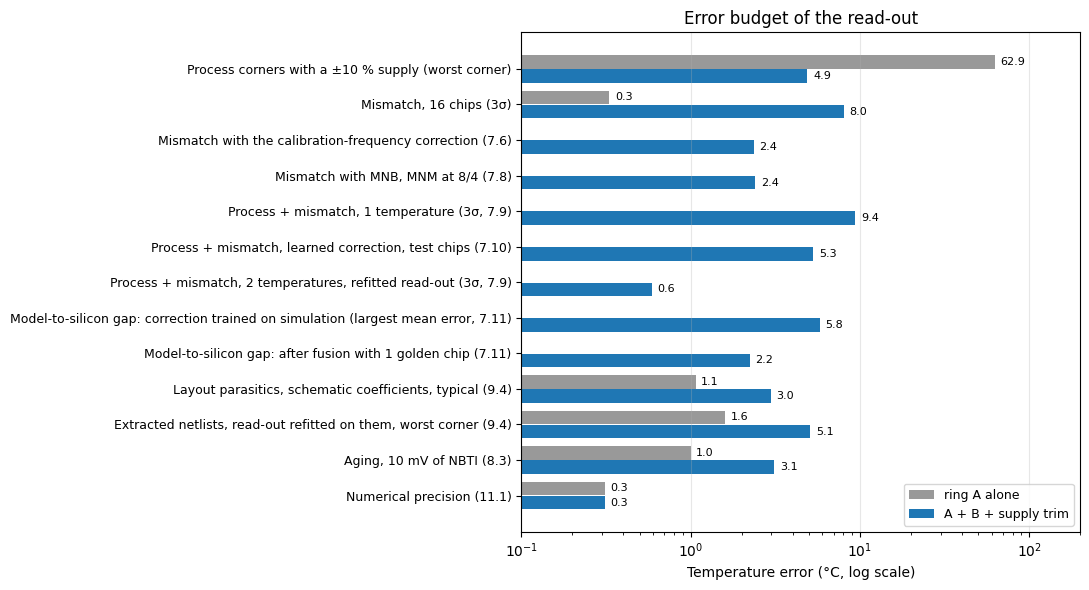

In [57]:
cf_row = "   + calibration-frequency correction"
budget = pd.DataFrame([
    ("Process corners with a ±10 % supply (worst corner)", "systematic",
     readout["1) A alone, 3.3 V +/-10 % (C)"].max(), readout["3) A + B + supply trim (C)"].max()),
    ("Mismatch, 16 chips (3σ)", "random",
     mc_table.loc["A alone, 3.3 V", "MC: max 3 sigma (C)"],
     mc_table.loc["A + B + supply trim, 3.3 V +/-10 %", "MC: max 3 sigma (C)"]),
    ("Mismatch with the calibration-frequency correction (7.6)", "random", np.nan,
     corr_table.loc[cf_row, "MC: max 3 sigma (C)"]),
    ("Mismatch with MNB, MNM at 8/4 (7.8)", "random", np.nan, fix_table.loc["MNB, MNM 8/4 (fix)", "max 3 sigma (C)"]),
    ("Process + mismatch, 1 temperature (3σ, 7.9)", "random", np.nan,
     pop_table.loc["1 temperature (25 C) + supply trim", "max 3 sigma (C)"]),
    ("Process + mismatch, learned correction, test chips (7.10)", "random", np.nan,
     learn_table.loc[f"   + learned correction: {list(MODELS)[1]}", "max 3 sigma (C)"]),
    ("Process + mismatch, 2 temperatures, refitted read-out (3σ, 7.9)", "random", np.nan,
     pop_table.loc["2 temperatures, read-out refitted for them", "max 3 sigma (C)"]),
    ("Model-to-silicon gap: correction trained on simulation (largest mean error, 7.11)", "systematic", np.nan,
     bmf_table.loc[(1, "simulation-trained correction as is"), "max |mean| (C)"]),
    ("Model-to-silicon gap: after fusion with 1 golden chip (7.11)", "systematic", np.nan,
     bmf_table.loc[(1, "Bayesian model fusion"), "max |mean| (C)"]),
    ("Layout parasitics, schematic coefficients, typical (9.4)", "systematic",
     readout_post["A alone, 3.3 V: layout (C)"].iloc[0], readout_post["A + B + trim: layout (C)"].iloc[0]),
    ("Extracted netlists, read-out refitted on them, worst corner (9.4)", "systematic",
     post_corner_table["A alone, 3.3 V: layout, refitted (C)"].max(), post_corner_table["A + B + trim: layout, refitted (C)"].max()),
    ("Aging, 10 mV of NBTI (8.3)", "drift",
     abs(equiv.loc["NBTI (pMOS)", "A alone: apparent dT (C)"]), abs(equiv.loc["NBTI (pMOS)", "A + B: apparent dT (C)"])),
    ("Numerical precision (11.1)", "simulation", acc["equivalent (C)"].max(), acc["equivalent (C)"].max()),
], columns=["source", "kind", "ring A alone (C)", "A + B + supply trim (C)"]).set_index("source")
try:
    display(budget.round(2))
except NameError:
    print(budget.round(2).to_string())

fig, ax = plt.subplots(figsize=(11, 6.0))
y = np.arange(len(budget))[::-1]
for dy, col, color in ((0.2, "ring A alone (C)", "0.6"), (-0.2, "A + B + supply trim (C)", "#1f77b4")):
    vals = budget[col].to_numpy(dtype=float)
    ok = ~np.isnan(vals)
    ax.barh(y[ok] + dy, vals[ok], height=0.38, color=color, label=col.replace(" (C)", ""))
    for yy, v in zip(y[ok] + dy, vals[ok]):
        ax.text(v * 1.08, yy, f"{v:.1f}", va="center", fontsize=8)
ax.set_xscale("log")
ax.set_xlim(0.1, 200)
ax.set_yticks(y)
ax.set_yticklabels(budget.index, fontsize=9)
ax.set_xlabel("Temperature error (°C, log scale)")
ax.set_title("Error budget of the read-out")
ax.grid(axis="x", alpha=0.3)
ax.legend(fontsize=9, loc="lower right")
fig.tight_layout()
plt.show()

**Ring A alone has one problem, the supply** (63 °C over ±10 % in the worst corner); every other source is about 1 °C or less. **The two-ring read-out trades it for several smaller errors:** the corner residual (4.9 °C), mismatch (8.0 °C, 3σ; 2.4 °C with either fix), layout parasitics (3.0 °C until the read-out is refitted on the extracted netlists, where the worst corner is 5.1 °C as in the schematic) and aging (3.1 °C per 10 mV). With process and mismatch together, one temperature leaves 9.4 °C over all 48 chips, the learned correction 5.3 °C on the 24 test chips and two temperatures 0.6 °C; a model-to-silicon gap adds a bias (5.8 °C on the emulated lot) that fusion with one golden chip cuts to 2.2 °C. Aging is the one term without a remedy in this design, which makes an unstressed reference ring the most important next step.

## 13. Conclusions

- **One ring cannot tell temperature from supply.** A one-point calibration removes process (ring A's TC varies only ±1 % across corners), but 10 mV of supply reads as 1.1 to 1.4 °C.
- **Two rings work when they differ in what sets their current**, device drive against a resistor, and when ring B's bias stack points its sensitivity away from ring A's: a pMOS over an nMOS diode (condition number 2.1) also cancels the fs and sf corners. One calibration temperature and a supply trim give 2 °C in four corners and 4.9 °C in ff.
- **Mismatch in one shared mirror device sets the real accuracy** (±8 °C, 3σ); enlarging MNB and MNM gives ±2.4 °C, at a small corner cost from its larger TC.
- **The number of calibration temperatures decides the accuracy class:** ±10.0 °C with one and ±0.7 °C with two on 24 unseen process + mismatch chips. A correction learned from three extra measurements at the calibration temperature halves the one-temperature error on unseen chips, because those measurements tell $V_{TH}$ shifts apart from mobility and length shifts, which frequencies alone cannot.
- **One measured chip bridges simulation and silicon:** Bayesian model fusion cuts the bias of a simulation-trained correction on a mismatched lot from rms 3.1 to 1.6 °C, which fitting on measured chips alone needs eight chips to match.
- **Layout costs speed, not accuracy:** all three layouts pass sign-off DRC and LVS, and with the read-out refitted on extracted netlists the corners return to their schematic results.
- **Aging is the price of ring B:** 10 mV of NBTI reads as 3.1 °C, and only a third, unstressed ring can make it observable.

**Reusing the flow.** The design is one sensor, but its parts are functions that take the design choices as arguments:

- **Netlists:** `ro_netlist` and `csro_netlist` take the stage count, device sizes, bias stack and resistor squares; `header` sets the corner, temperature and mismatch seed, and `chip_lib` turns the PDK's statistical section into one reproducible chip.
- **Layout as code:** `ring_a_layout(n, pitch)` and `ring_b_layout(n, pitch, r_len, big_mirror)` draw the rings in magic for another stage count or resistor length, with or without the 8/4 mirror; `ring_a_schematic` and `ring_b_schematic` write the matching LVS references, and `klayout_drc` and `post_netlist` repeat sign-off DRC and extraction. Generated outside this run, rings of 7 and 15 stages with 50- to 100-square resistors, and the 8/4 mirror at 7 stages, all pass magic DRC, LVS and the sign-off DRC and antenna decks.
- **Calibration:** the analyses of 7.9 to 7.11 read a table of per-chip measurements (frequency and supply power of each ring at each temperature and supply; the CSV files in `data` show the format), not the circuit, so the supply-trim read-out, the ridge correction and the model fusion apply to any two-oscillator sensor whose simulations fill the same table.

Porting to another PDK means changing the model include, the device names and the layer names of the layout generator.

## 14. Future work

- **Learned calibration on silicon:** fuse the simulation-trained correction with one or two measured chips per lot and check that the same inputs carry the same information; add inputs readable at one temperature and an aging reference ring, the natural link to machine-learning-based PVT and aging prediction.
- **Reference ring for aging**, powered only during conversions, and aging of ring B's stack and mirror devices.
- **Sizing:** the 8/4 mirror throughout the population, and how $N$, $W_p/W_n$, $L$ and $R$ trade sensitivity against energy per conversion.
- **Read-out:** a frequency counter with its conversion time, and duty-cycled operation of both rings.
- **Toward tape-out:** wire resistance in the extraction, a compact mirror block, a pad frame with output buffers, and a slot on an open GF180MCU shuttle.

## Acknowledgements

Claude (Anthropic) assisted with the circuit analysis, the code, the literature search and the writing; every result comes from the simulations in this notebook, and its content is the author's responsibility.

## References

- GF180MCU primitive device library (`gf180mcu_fd_pr`), Apache 2.0: https://github.com/fossi-foundation/globalfoundries-pdk-libs-gf180mcu_fd_pr
- ngspice: https://ngspice.sourceforge.io/
- magic VLSI layout tool: http://opencircuitdesign.com/magic/
- netgen LVS: http://opencircuitdesign.com/netgen/
- KLayout: https://www.klayout.de/ (GF180MCU sign-off DRC deck in open_pdks, `libs.tech/klayout/drc`)
- open_pdks (GF180MCU technology files for magic and netgen): https://github.com/RTimothyEdwards/open_pdks
- litex-hub conda packages of the open-source EDA tools: https://anaconda.org/litex-hub
- schemdraw: https://schemdraw.readthedocs.io/
- [Anand 2016] T. Anand, K. A. A. Makinwa and P. K. Hanumolu, "A VCO based highly digital temperature sensor with 0.034 °C/mV supply sensitivity," *IEEE J. Solid-State Circuits*, vol. 51, no. 11, p. 2651, Nov. 2016. https://web.engr.oregonstate.edu/~anandt/papers/anand_jssc_2016.pdf
- [Yang 2017] K. Yang, Q. Dong, W. Jung, Y. Zhang, M. Choi, D. Blaauw and D. Sylvester, "A 0.6nJ −0.22/+0.19°C inaccuracy temperature sensor using exponential subthreshold oscillation dependence," *ISSCC*, paper 9.2, 2017. https://blaauw.engin.umich.edu/wp-content/uploads/sites/342/2018/02/Kaiyuan-Yang-A-0.6nJ-0.220.19C-Inaccuracy-Temperature-Sensor-Using.pdf
- [Chen 2010] S.-W. Chen, M.-H. Chang, W.-C. Hsieh and W. Hwang, "Fully on-chip temperature, process, and voltage sensors," *Proc. IEEE ISCAS*, pp. 897–900, 2010. https://ieeexplore.ieee.org/document/5537410
- [Kim 2007] T.-H. Kim, R. Persaud and C. H. Kim, "Silicon odometer: an on-chip reliability monitor for measuring frequency degradation of digital circuits," *Symp. VLSI Circuits*, pp. 122–123, 2007. https://doi.org/10.1109/VLSIC.2007.4342682
- [Bhushan 2006] M. Bhushan, A. Gattiker, M. B. Ketchen and K. K. Das, "Ring oscillators for CMOS process tuning and variability control," *IEEE Trans. Semiconductor Manufacturing*, vol. 19, no. 1, pp. 10–18, Feb. 2006. https://doi.org/10.1109/TSM.2005.863244
- [Huang 2017] T.-H. Huang, W.-T. Hung, H.-Y. Yang, W.-H. Chang, M. C.-T. Chao, Y.-Y. Chen, C.-Y. Kuo and J.-N. Lee, "Predicting Vt variation and static IR drop of ring oscillators using model-fitting techniques," *ASP-DAC*, 2017. https://www.aspdac.com/aspdac2017/archive/pdf/5B-3_add_file.pdf
- [Sun 2014] S. Sun, F. Wang, S. Yaldiz, X. Li, L. Pileggi et al., "Indirect performance sensing for on-chip self-healing of analog and RF circuits," *IEEE Trans. Circuits and Systems I*, vol. 61, no. 8, Aug. 2014. https://users.ece.cmu.edu/~xinli/papers/2014_TCAS_healing.pdf
- [Wang 2013] F. Wang, W. Zhang, S. Sun, X. Li and C. Gu, "Bayesian model fusion: large-scale performance modeling of analog and mixed-signal circuits by reusing early-stage data," *Design Automation Conference (DAC)*, 2013. https://doi.org/10.1145/2463209.2488812
- [Datta 2010] B. Datta and W. Burleson, "Calibration of on-chip thermal sensors using process monitoring circuits," *ISQED*, 2010. https://isqed.org/English/Archives/2010/Technical_Sessions/169.html
- [Gondo 2020] M. Gondo, Y. Miyake and S. Kajihara, "On machine learning based accuracy improvement for a digital temperature and voltage sensor," *IEICE Technical Report*, vol. 119, no. 420, DC2019-86, 2020. https://www.ieice.org/ken/paper/20200226n1Vj/eng/
- [Pertijs 2010] M. A. P. Pertijs, A. L. Aita, K. A. A. Makinwa and J. H. Huijsing, "Low-cost calibration techniques for smart temperature sensors," *IEEE Sensors Journal*, vol. 10, no. 6, June 2010. https://ei.et.tudelft.nl/smart_temperature/Low-Cost_Calibration_Techniques_for_Smart_Temperature_Sensors.pdf
- [Yousefzadeh 2020] B. Yousefzadeh and K. A. A. Makinwa, "A BJT-based temperature-to-digital converter with a ±0.25 °C 3σ-inaccuracy from −40 °C to +180 °C using heater-assisted voltage calibration," *IEEE J. Solid-State Circuits*, vol. 55, no. 2, Feb. 2020. https://doi.org/10.1109/JSSC.2019.2953834